# Zwroty w Nordvik: co wraca częściej, niż wynika z kanału, i ile to będzie kosztować

## Metadata & Purpose

| | |
| --- | --- |
| **Autor** | agent AI (materiał szkoleniowy; dane syntetyczne) |
| **Data** | 2026-11-10 (stan danych: 2026-09-20) |
| **Zespół** | obsługa zwrotów i e-commerce (zleceniodawca), analityka danych (wykonawca) |
| **Firma** | Nordvik: polska sieć odzieżowa z własną marką, 5 sklepów stacjonarnych i sklep internetowy. Waluta PLN, VAT 23%. |
| **Status notebooka** | w budowie (praca w kilku etapach); ten zapis obejmuje etapy: zrozumienie zlecenia, audyt danych, eksploracja |

### Zlecenie biznesowe (własnymi słowami)

Kierownik obsługi zwrotów i zespół e-commerce zauważyli, że online wraca ok. 18% sztuk, a w sklepach ok. 4%. Wiedzą, że to w dużej mierze cecha kanału (klient online nie może przymierzyć ubrania), więc nie pytają, **czy** online wraca więcej, tylko **gdzie zwrotów jest więcej, niż wynika z samego kanału**. Pytania:

1. **Oferta:** które modele i rozmiary wracają wyraźnie częściej, niż byśmy oczekiwali (po to, by poprawić tabele rozmiarów, opisy i rozmowę z dostawcą)?
2. **Moment zakupu:** co jeszcze, **już w momencie zakupu**, zwiększa ryzyko zwrotu?
3. **Koszt:** ile zwroty będą nas kosztować w następnym kwartale?
4. **Kontrola jakości:** moce pozwalają dokładnie sprawdzić (stan, uszkodzenia) ok. 100 zwróconych pozycji tygodniowo. Czy da się wskazać, które zwroty sprawdzać w pierwszej kolejności?

### Jak rozumiem zlecenie: trzy różne decyzje

Cztery pytania to w istocie **trzy decyzje na różnych poziomach szczegółowości**, więc każda wymaga innej zmiennej celu i innej miary sukcesu (uzasadnienie i szczegóły w sekcji „Faza 1" poniżej):

| Decyzja | Poziom analizy | Zmienna celu | Miara sukcesu |
| --- | --- | --- | --- |
| A. Poprawa oferty (modele, rozmiary) | komórka model × rozmiar × kanał | wskaźnik zwrotów z przedziałem niepewności, ponad oczekiwanie wynikające z kanału, kategorii i rozmiaru | czy potrafimy wskazać komórki, które odstają bardziej, niż tłumaczy losowość |
| B. Działania przy zakupie | pozycja sprzedaży (jednostka) | czy sprzedana sztuka zostanie zwrócona w ciągu H dni | jakość rankingu ryzyka **wewnątrz kanału** (PR-AUC, ROC-AUC), kalibracja, przyrost ponad baseline „sam kanał" |
| C. Koszt następnego kwartału | agregat (kanał × tydzień/miesiąc) | wartość zwrotów (PLN netto) | błąd prognozy na okresach, których model nie widział, przedział niepewności |

Pytanie o kolejność kontroli (4) traktuję osobno: zwroty do sprawdzenia **już dotarły**, więc ryzyko zwrotu „z chwili zakupu" nie jest tu właściwą informacją (patrz Faza 1).

### Hipotezy (wstępne, formalne progi decyzji zapiszę przed budową modeli)

- **H1 (rozmiar × kanał):** online skrajne rozmiary (XS, XL) wracają częściej niż M i L, w sklepach różnica jest słabsza.
- **H2 (cechy zakupu):** cena, rabat, kolekcja i zawartość paragonu niosą informację o ryzyku zwrotu ponad kanał, kategorię i rozmiar.
- **H3 (heterogeniczność modeli):** niektóre modele odbiegają od oczekiwań bardziej, niż wynika z losowości.
- **H4 (powody w czasie):** struktura powodów zwrotu niektórych modeli zmienia się w czasie (np. wzrost udziału uszkodzeń), co sygnalizuje problem jakości.
- **H5 (rabat):** rabat zwiększa ryzyko zwrotu (sprawdzę efekt surowy i po kontroli modelu i rozmiaru).

### Wyniki

_Uzupełniane na końcu pracy (sekcja „Results & Conclusions")._

### Jak czytać ten notebook

Przed każdym krokiem jest „po co", po wyniku „co widzę", a po bloku „wniosek/decyzja". Fakty (liczby z kodu) są oddzielone od interpretacji. Założenia i niepewności są oznaczone. Pojęcia specjalistyczne wyjaśniam przy pierwszym użyciu. Ślepe uliczki zostają w zapisie.

## Setup

Po co: ustalić wersje bibliotek, ziarno losowe i ścieżki, żeby wynik dało się odtworzyć. Dane czytam bezpośrednio z plików Parquet zapytaniami SQL (silnik DuckDB). Żadnych haseł ani adresów usług nie potrzeba.

In [1]:
import os
import platform
import warnings
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import statsmodels

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 20260920  # stałe ziarno dla wszystkiego, co losowe (bootstrap, podziały)
rng = np.random.default_rng(SEED)

# Ścieżki liczone od katalogu repozytorium (notebook uruchamiany z katalogu głównego lub z katalogu analizy)
ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "datasets" / "synthetic" / "bc05"
CACHE = ROOT / "analizy" / "bc05-prognoza-zwrotow" / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5)})

con = duckdb.connect()  # baza w pamięci; dane zostają w Parquet

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__, "| duckdb", duckdb.__version__)
print("Katalog danych:", DATA.relative_to(ROOT), "| istnieje:", DATA.exists())

Python 3.12.5 | pandas 3.1.1 | numpy 2.5.4 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2 | seaborn 0.13.2 | duckdb 2.0.0
Katalog danych: datasets\synthetic\bc05 | istnieje: True


## Load Data

Po co: zobaczyć, co faktycznie jest w pięciu tabelach (rozmiary, kolumny, typy), zanim cokolwiek policzę.

**Dane (wyciąg z hurtowni, format Parquet, stan 2026-09-20):**

| Tabela | Jedna linia to | Najważniejsze kolumny |
| --- | --- | --- |
| `dim_date` | dzień kalendarzowy | `DateKey` (rrrrmmdd), `Date`, `IsoYear`, `IsoWeek`, `Season` |
| `dim_store` | sklep (także sklep internetowy) | `StoreKey`, `StoreCode`, `Channel` (`STORE` albo `ONLINE`) |
| `dim_product` | SKU = model × kolor × rozmiar | `ProductKey`, `StyleCode` (model), `Category`, `Size`, `ListPrice` (brutto, bieżąca), `UnitCost` |
| `fact_sales` | pozycja paragonu lub zamówienia | `TransactionNo`, `ProductKey`, `StoreKey`, `DateKey`, `Quantity`, `UnitPrice`, `DiscountAmount`, `GrossAmount` |
| `fact_returns` | pozycja zwrotu przyjętego w portalu zwrotów | `TransactionNo` (paragon pierwotnej sprzedaży), `ProductKey`, `DateKey` i `StoreKey` (**data i miejsce przyjęcia zwrotu**, nie zakupu), `Quantity`, `ReturnAmount` (brutto), `ReturnReason` |

Ważne własności (z opisu danych): zwrot nie ma numeru linii paragonu ani identyfikatora klienta, łączy się ze sprzedażą po parze (`TransactionNo`, `ProductKey`); jeden wiersz zwrotu może dotyczyć części sztuk z pozycji; powód zwrotu bywa pusty.

In [2]:
def q(sql):
    """Zapytanie SQL (DuckDB) po Parquet; zwraca DataFrame."""
    return con.execute(sql).df()

for name in ["dim_date", "dim_store", "dim_product", "fact_sales", "fact_returns"]:
    con.execute(f"CREATE OR REPLACE VIEW {name} AS SELECT * FROM read_parquet('{(DATA / (name + '.parquet')).as_posix()}')")

tables = {}
for name in ["dim_date", "dim_store", "dim_product", "fact_sales", "fact_returns"]:
    tables[name] = q(f"SELECT * FROM {name} LIMIT 5")
    n = q(f"SELECT COUNT(*) AS n FROM {name}")["n"][0]
    print(f"{name}: {n:,} wierszy, {len(tables[name].columns)} kolumn")

dim_date: 761 wierszy, 14 kolumn
dim_store: 6 wierszy, 10 kolumn
dim_product: 312 wierszy, 11 kolumn
fact_sales: 433,298 wierszy, 13 kolumn
fact_returns: 32,319 wierszy, 10 kolumn


In [3]:
# Małe wymiary wczytuję w całości; fakty zostają w Parquet i czytam je zapytaniami.
dim_store = q("SELECT * FROM dim_store")
dim_product = q("SELECT * FROM dim_product")
print("dim_store", dim_store.shape)
display(dim_store)
print("dim_product", dim_product.shape)
display(dim_product.head())
print("fact_sales (próbka)")
display(tables["fact_sales"])
print("fact_returns (próbka)")
display(tables["fact_returns"])

dim_store (6, 10)


,StoreKey,StoreCode,StoreName,City,Region,Channel,Format,SalesAreaM2,OpenedDate,RemodelDate
0,1,S-WAW-01,Nordvik Arkadia,Warszawa,Mazowieckie,STORE,Galeria,420,2016-04-15,NaT
1,2,S-WAW-02,Nordvik Mokotów,Warszawa,Mazowieckie,STORE,Ulica,260,2019-09-01,NaT
2,3,S-KRK-01,Nordvik Kraków Rynek,Kraków,Małopolskie,STORE,Ulica,320,2017-11-20,2026-04-01
3,4,S-POZ-01,Nordvik Poznań,Poznań,Wielkopolskie,STORE,Galeria,300,2018-03-10,NaT
4,5,S-GDA-01,Nordvik Gdańsk,Gdańsk,Pomorskie,STORE,Ulica,240,2021-10-05,NaT
5,6,S-ONL-01,Nordvik Online,-,Online,ONLINE,E-commerce,<NA>,2015-01-01,NaT


dim_product (312, 11)


,ProductKey,SKU,StyleCode,StyleName,Department,Category,Color,Size,ListPrice,UnitCost,IsActive
0,1,W-JKT-001-CZA-XS,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,XS,399,148,1
1,2,W-JKT-001-CZA-S,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,S,399,148,1
2,3,W-JKT-001-CZA-M,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,M,399,148,1
3,4,W-JKT-001-CZA-L,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,L,399,148,1
4,5,W-JKT-001-CZA-XL,W-JKT-001,Kurtka pikowana damska,WOMEN,Kurtki,Czarny,XL,399,148,1


fact_sales (próbka)


,SalesKey,DateKey,ProductKey,StoreKey,TransactionNo,LineNumber,Quantity,UnitPrice,DiscountAmount,GrossAmount,NetAmount,UnitCost,LoadId
0,1,20250101,3,6,T-S-ONL-01-20250101-0001,1,2,399,0,798,648.7800,148,1
1,2,20250101,247,6,T-S-ONL-01-20250101-0001,2,1,39,0,39,31.7100,14.8000,1
2,3,20250101,73,6,T-S-ONL-01-20250101-0001,3,1,429,0,429,348.7800,160,1
3,4,20250101,25,6,T-S-ONL-01-20250101-0002,1,1,199,0,199,161.7900,62,1
4,5,20250101,8,6,T-S-ONL-01-20250101-0003,1,1,399,0,399,324.3900,148,1


fact_returns (próbka)


,ReturnKey,DateKey,ProductKey,StoreKey,ReturnNo,TransactionNo,Quantity,ReturnAmount,ReturnReason,LoadId
0,1,20250106,123,6,R-20250106-000001,T-S-ONL-01-20250101-0023,1,89,CHANGED_MIND,1
1,2,20250106,173,6,R-20250106-000002,T-S-ONL-01-20250103-0047,1,239,WRONG_SIZE,1
2,3,20250107,34,6,R-20250107-000001,T-S-ONL-01-20250101-0042,1,179,OTHER,1
3,4,20250107,29,1,R-20250107-000002,T-S-WAW-01-20250103-0056,1,199,WRONG_SIZE,1
4,5,20250107,5,6,R-20250107-000003,T-S-ONL-01-20250102-0019,1,399,CHANGED_MIND,1


## Explore

Ta sekcja ma trzy części: najpierw (1) rozpisuję, jak rozumiem zlecenie, potem (2) sprawdzam, czy dane nadają się do odpowiedzi (audyt), a następnie (3) wracam do definicji etykiety i okna zwrotu, które da się ustalić dopiero po obejrzeniu opóźnień, i (4) szukam wzorców pod hipotezy.

### Faza 1 (część a): zrozumienie zlecenia

**Po co ten krok:** zanim cokolwiek policzę, chcę mieć jasność, *jaką decyzję* wspiera każde pytanie, bo od tego zależy, co jest zmienną celu i jak ocenię sukces. Wybór złego poziomu analizy (np. modelu na poziomie pozycji paragonu do decyzji o tabeli rozmiarów) kończy się wynikiem, który nie odpowiada na pytanie.

**Decyzja A: poprawa oferty (pytanie 1).**
- Pytanie dotyczy *trwałych właściwości* modelu i rozmiaru (krój, tabela rozmiarów, opis), więc analizuję komórki **model × rozmiar × kanał**, a nie pojedyncze zakupy.
- „Wyraźnie częściej, niż byśmy się spodziewali" oznacza porównanie z **wartością oczekiwaną**. Najprostsza sensowna wartość oczekiwana wynika z kanału, kategorii i rozmiaru (łącznie), bo zleceniodawca sam mówi, że kanał tłumaczy dużą część różnic.
- Komórki są małe (np. 3 zwroty z 7 sprzedanych sztuk), więc surowe wskaźniki wprowadzają w błąd. Potrzebne są przedziały niepewności i **kurczenie** (shrinkage): ściąganie wskaźnika małej komórki w stronę wartości oczekiwanej, tym mocniej, im mniej w niej danych.
- Miara sukcesu: czy umiem wskazać komórki odstające bardziej, niż tłumaczy losowość, z przedziałem po uwzględnieniu liczebności.

**Decyzja B: działania w momencie zakupu (pytanie 2).**
- Interesuje nas, które cechy **znane w chwili sprzedaży** (cena, rabat, kolekcja, rozmiar, zawartość tego samego paragonu) zwiększają ryzyko zwrotu **ponad** kanał, kategorię i rozmiar. Poziom: pozycja sprzedaży, a dokładniej **sztuka** (patrz niżej, dlaczego).
- Zmienna celu: czy sprzedana sztuka została zwrócona w ciągu *H* dni od sprzedaży (*H* wyprowadzę z rozkładu opóźnień).
- Miara sukcesu: jakość rankingu ryzyka **wewnątrz kanału** (PR-AUC, ROC-AUC; wyjaśnię je przy użyciu), kalibracja prawdopodobieństw i przyrost względem baseline'u „średnia kanału". Wspólny ROC-AUC dla obu kanałów byłby zawyżony wyłącznie różnicą bazową 18% vs 4%.

**Decyzja C: koszt zwrotów w następnym kwartale (pytanie 3).**
- To prognoza **zagregowana** (kanał × okres), a nie suma ryzyk z pojedynczych pozycji. Tu obowiązuje definicja słownikowa (zwrot liczony w okresie *przyjęcia*), bo koszt powstaje wtedy, gdy zwrot jest przyjmowany. Do prognozy potrzebne są: przyszła sprzedaż (której nie mam, to osobny problem), wskaźnik zwrotów i opóźnienie zwrotu.
- Słowo „koszt" jest niejednoznaczne (utracona sprzedaż netto? koszt obsługi? odpis towaru nieodsprzedawalnego?). Dane zawierają tylko kwotę zwrotu, więc **zakładam: koszt = wartość zwrotów netto** (`SUM(ReturnAmount) / 1,23`, definicja ze słownika metryk). To pytanie do zleceniodawcy.

**Poziom jednostki dla decyzji B: sztuka, nie wiersz.** Pozycja paragonu może mieć `Quantity` > 1, a zwrot bywa częściowy (np. zwrócona 1 z 2 sztuk). Traktowanie pozycji jako 0/1 wymagałoby arbitralnej reguły („zwrot, jeśli wróciła choć jedna sztuka"?). Dlatego etykietą jest **udział zwróconych sztuk** w pozycji; w modelach klasyfikacyjnych rozwinę pozycje do pojedynczych sztuk (lub zastosuję wagi). Jeśli większość pozycji ma `Quantity` = 1, problem jest drobny, ale sprawdzę to w audycie.

**Pytanie o kolejność kontroli (pytanie 4): czy ryzyko zwrotu z chwili zakupu jest właściwą informacją?**
- Moje rozumienie: zwroty do sprawdzenia **już przyszły**, a pracownik wybiera, które z puli przyjętych w tym tygodniu obejrzeć dokładnie. Interesuje go nie to, czy klient *zwróci* towar, tylko czy **zwrócony egzemplarz jest uszkodzony lub niezdatny do odsprzedaży** albo czy to sygnał problemu jakości.
- Zatem model „ryzyka zwrotu w chwili zakupu" **nie odpowiada** na to pytanie: zwrot już nastąpił, więc prawdopodobieństwo zwrotu wynosi 1. Właściwą informacją byłoby prawdopodobieństwo, że *zwrot okaże się wadliwy*, liczone z cech znanych **w chwili przyjęcia** (model, rozmiar, opóźnienie, kwota, powód wpisany przy przyjęciu).
- Problem: w danych **nie ma wyniku kontroli** (nie wiemy, które zwroty po sprawdzeniu faktycznie okazały się uszkodzone). Jest tylko `ReturnReason` wpisany przez obsługę przy przyjęciu, z wartością `DAMAGED` jako deklaracją, a nie wynikiem kontroli. Nie da się więc *wyuczyć ani zweryfikować* rankingu kontroli. Mogę najwyżej zaproponować **heurystykę priorytetów** (np. modele o rosnącym udziale `DAMAGED`) i wprost napisać, że jej skuteczności nie da się zmierzyć na tych danych. Wracam do tego w wynikach.

**Cenzurowanie (wyjaśnienie pojęcia).** Etykieta „zwrócona w ciągu H dni" wymaga, żeby od sprzedaży minęło co najmniej H dni **i** żeby zwroty przyjęte w tym czasie były już w hurtowni. Dla sztuk sprzedanych niedawno okno obserwacji jest jeszcze otwarte: brak zwrotu może znaczyć „jeszcze nie wrócił". Taką obserwację nazywa się **ocenzurowaną** (niepełna informacja o etykiecie). Nie wolno jej traktować jako „niezwróconej", bo zaniżyłoby to wskaźnik zwrotów w ostatnich tygodniach i model nauczyłby się fałszywego trendu.

### Faza 2: audyt danych

**Po co ten krok:** sprawdzić, czy zwroty da się rzetelnie połączyć ze sprzedażą i czy dane nie mają pułapek (duplikaty, zwroty bez pary, zwroty „sprzed" sprzedaży, braki). Każdy wniosek o wskaźniku zwrotów stoi na tym złączeniu.

#### 2.1 Podstawowe kontrole sprzedaży i zwrotów

Sprawdzam zakres dat, unikalność kluczy, arytmetykę kwot (zgodnie z opisem: `GrossAmount = Quantity × UnitPrice − DiscountAmount`, `NetAmount = GrossAmount / 1,23`) oraz rozkład `Quantity`.

In [4]:
# Widoki pomocnicze: daty w formacie DATE i kanał ze sprzedaży (z dim_store).
con.execute("""
CREATE OR REPLACE VIEW sales_f AS
SELECT s.SalesKey, s.TransactionNo, s.LineNumber, s.ProductKey, s.StoreKey,
       strptime(CAST(s.DateKey AS VARCHAR), '%Y%m%d')::DATE AS SaleDate,
       st.Channel, st.StoreCode,
       s.Quantity, s.UnitPrice, s.DiscountAmount, s.GrossAmount, s.NetAmount, s.UnitCost
FROM fact_sales s JOIN dim_store st USING (StoreKey)
""")
con.execute("""
CREATE OR REPLACE VIEW returns_f AS
SELECT r.ReturnKey, r.ReturnNo, r.TransactionNo, r.ProductKey, r.StoreKey AS ReturnStoreKey,
       strptime(CAST(r.DateKey AS VARCHAR), '%Y%m%d')::DATE AS ReturnDate,
       st.Channel AS ReturnChannel, st.StoreCode AS ReturnStoreCode,
       r.Quantity, r.ReturnAmount, r.ReturnReason
FROM fact_returns r JOIN dim_store st USING (StoreKey)
""")

print("Sprzedaż: zakres dat i podstawowe liczności")
display(q("""
SELECT MIN(SaleDate) AS od, MAX(SaleDate) AS do, COUNT(*) AS wiersze, SUM(Quantity) AS sztuki,
       COUNT(DISTINCT TransactionNo) AS paragony,
       COUNT(DISTINCT (TransactionNo, LineNumber)) AS unikalne_linie
FROM sales_f"""))
print("Zwroty: zakres dat i podstawowe liczności")
display(q("""
SELECT MIN(ReturnDate) AS od, MAX(ReturnDate) AS do, COUNT(*) AS wiersze, SUM(Quantity) AS sztuki,
       COUNT(DISTINCT ReturnKey) AS unikalne_ReturnKey, COUNT(DISTINCT ReturnNo) AS unikalne_ReturnNo,
       COUNT(DISTINCT TransactionNo) AS paragony_ze_zwrotem
FROM returns_f"""))

print("Rozkład Quantity w sprzedaży (po kanale):")
display(q("""SELECT Channel, Quantity, COUNT(*) AS wiersze FROM sales_f GROUP BY ALL ORDER BY Channel, Quantity"""))
print("Rozkład Quantity w zwrotach:")
display(q("""SELECT Quantity, COUNT(*) AS wiersze FROM returns_f GROUP BY ALL ORDER BY Quantity"""))

print("Arytmetyka kwot (maks. odchylenie bezwzględne, PLN):")
display(q("""
SELECT MAX(ABS(GrossAmount - (Quantity * UnitPrice - DiscountAmount))) AS maks_odch_brutto,
       MAX(ABS(NetAmount - GrossAmount / 1.23)) AS maks_odch_netto,
       SUM(CASE WHEN DiscountAmount < 0 THEN 1 ELSE 0 END) AS ujemny_rabat,
       SUM(CASE WHEN GrossAmount <= 0 THEN 1 ELSE 0 END) AS brutto_niedodatnie
FROM sales_f"""))

Sprzedaż: zakres dat i podstawowe liczności


,od,do,wiersze,sztuki,paragony,unikalne_linie
0,2025-01-01,2026-09-20,433298,"520,513",207970,433298


Zwroty: zakres dat i podstawowe liczności


,od,do,wiersze,sztuki,unikalne_ReturnKey,unikalne_ReturnNo,paragony_ze_zwrotem
0,2025-01-06,2026-09-20,32319,"36,283",32319,32319,28556


Rozkład Quantity w sprzedaży (po kanale):


,Channel,Quantity,wiersze
0,ONLINE,1,80777
1,ONLINE,2,13167
2,ONLINE,3,2647
3,STORE,1,277672
4,STORE,2,49316
5,STORE,3,9719


Rozkład Quantity w zwrotach:


,Quantity,wiersze
0,1,28979
1,2,2716
2,3,624


Arytmetyka kwot (maks. odchylenie bezwzględne, PLN):


,maks_odch_brutto,maks_odch_netto,ujemny_rabat,brutto_niedodatnie
0,0,0.0050,0,0


**Co widzę (fakty):**
- Sprzedaż: 433 298 pozycji paragonów (520 513 sztuk), 207 970 paragonów, od 2025-01-01 do 2026-09-20. Para (`TransactionNo`, `LineNumber`) jest unikalna, zgodnie z opisem.
- Zwroty: 32 319 wierszy (36 283 sztuk) od **2025-01-06** do 2026-09-20; `ReturnKey` i `ReturnNo` są unikalne. Pierwszy zwrot pojawia się 5 dni po starcie sprzedaży, co jest wiarygodne (zwrot nie może przyjść przed zakupem).
- `Quantity` ma tylko wartości 1, 2, 3. Pozycji wielosztukowych jest ok. 17,5% w sklepach i ok. 16,4% online, więc zwrot częściowy może się zdarzać, ale nie jest to większość.
- Arytmetyka kwot zgadza się z opisem (odchylenie brutto 0, netto do 0,005 PLN, czyli zaokrąglenie do grosza), brak ujemnych rabatów i pozycji o niedodatniej wartości.

**Interpretacja:** surowa jakość tabel sprzedaży wygląda czysto. Nie wnioskuję jeszcze nic o zwrotach, bo kluczowe jest dopiero złączenie z paragonami.

#### 2.2 Złączenie zwrotów ze sprzedażą: pokrycie, kolejność dat, nadmiar sztuk, duplikaty

**Po co:** zwrot nie ma numeru linii paragonu, więc łączymy go po parze (`TransactionNo`, `ProductKey`). Muszę wiedzieć: (a) ile zwrotów nie ma pary w sprzedaży, (b) czy zwrot nie poprzedza sprzedaży, (c) czy łącznie zwrócono nie więcej sztuk, niż sprzedano, (d) czy nie ma zdublowanych wierszy zwrotu. Każdy z tych problemów zniekształciłby wskaźnik zwrotów w innym kierunku.

Najpierw agreguję sprzedaż do poziomu klucza złączenia (`TransactionNo`, `ProductKey`): liczba pozycji (linii) o tym kluczu, suma sztuk, data i kanał.

In [5]:
# Sprzedaż zagregowana do klucza złączenia zwrotów; n_linii > 1 oznacza, że klucz nie wskazuje jednej pozycji.
con.execute("""
CREATE OR REPLACE VIEW sales_key AS
SELECT TransactionNo, ProductKey,
       COUNT(*) AS n_linii, SUM(Quantity) AS sold_qty,
       MIN(SaleDate) AS SaleDate, MAX(SaleDate) AS SaleDateMax,
       MIN(Channel) AS Channel, COUNT(DISTINCT StoreKey) AS n_sklepow
FROM sales_f GROUP BY TransactionNo, ProductKey
""")
# Zwroty zagregowane do tego samego klucza (jeden klucz może mieć kilka wierszy zwrotu).
con.execute("""
CREATE OR REPLACE VIEW returns_key AS
SELECT TransactionNo, ProductKey, COUNT(*) AS n_wierszy_zwrotu, SUM(Quantity) AS ret_qty,
       MIN(ReturnDate) AS FirstReturnDate, MAX(ReturnDate) AS LastReturnDate
FROM returns_f GROUP BY TransactionNo, ProductKey
""")

print("(a) Pokrycie złączenia: wiersze zwrotu bez pary w sprzedaży")
display(q("""
SELECT COUNT(*) AS wiersze_zwrotu, SUM(r.Quantity) AS sztuki_zwrotu,
       SUM(CASE WHEN k.TransactionNo IS NULL THEN 1 ELSE 0 END) AS bez_pary_po_kluczu,
       SUM(CASE WHEN t.TransactionNo IS NULL THEN 1 ELSE 0 END) AS bez_paragonu_w_ogole
FROM returns_f r
LEFT JOIN sales_key k ON k.TransactionNo = r.TransactionNo AND k.ProductKey = r.ProductKey
LEFT JOIN (SELECT DISTINCT TransactionNo FROM sales_f) t ON t.TransactionNo = r.TransactionNo
"""))

print("(b) Kolejność dat: zwrot względem sprzedaży (dni od sprzedaży do przyjęcia zwrotu)")
display(q("""
SELECT SUM(CASE WHEN r.ReturnDate < k.SaleDate THEN 1 ELSE 0 END) AS zwrot_przed_sprzedaza,
       SUM(CASE WHEN r.ReturnDate = k.SaleDate THEN 1 ELSE 0 END) AS zwrot_w_dniu_sprzedazy,
       SUM(CASE WHEN r.ReturnDate > k.SaleDate THEN 1 ELSE 0 END) AS zwrot_po_sprzedazy,
       MIN(DATE_DIFF('day', k.SaleDate, r.ReturnDate)) AS min_dni, MAX(DATE_DIFF('day', k.SaleDate, r.ReturnDate)) AS max_dni
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey)
"""))

print("(c) Nadmiar: klucze, dla których zwrócono więcej sztuk niż sprzedano")
display(q("""
SELECT COUNT(*) AS klucze_ze_zwrotem, SUM(CASE WHEN r.ret_qty > k.sold_qty THEN 1 ELSE 0 END) AS zwrot_ponad_sprzedaz,
       SUM(CASE WHEN r.ret_qty = k.sold_qty THEN 1 ELSE 0 END) AS zwrot_calosci,
       SUM(CASE WHEN r.ret_qty < k.sold_qty THEN 1 ELSE 0 END) AS zwrot_czesci,
       SUM(CASE WHEN r.n_wierszy_zwrotu > 1 THEN 1 ELSE 0 END) AS klucze_z_wieloma_wierszami_zwrotu
FROM returns_key r JOIN sales_key k USING (TransactionNo, ProductKey)
"""))

print("(d) Podejrzane duplikaty: ten sam klucz, ta sama data, ta sama ilość, ten sam powód w >1 wierszu")
display(q("""
SELECT COUNT(*) AS grupy_zduplikowane, SUM(n) AS wiersze_w_tych_grupach
FROM (SELECT TransactionNo, ProductKey, ReturnDate, Quantity, ReturnReason, COUNT(*) AS n
      FROM returns_f GROUP BY ALL HAVING COUNT(*) > 1)
"""))
print("    Klucze z >1 wierszem zwrotu: rozkład liczby wierszy i różnicy dat między nimi")
display(q("""
SELECT n_wierszy_zwrotu, COUNT(*) AS klucze,
       AVG(DATE_DIFF('day', FirstReturnDate, LastReturnDate)) AS sr_dni_miedzy_pierwszym_a_ostatnim
FROM returns_key WHERE n_wierszy_zwrotu > 1 GROUP BY 1 ORDER BY 1
"""))

print("(e) Unikalność klucza złączenia w sprzedaży: ile kluczy ma >1 linię paragonu")
display(q("""
SELECT n_linii, COUNT(*) AS klucze, SUM(sold_qty) AS sztuki,
       SUM(CASE WHEN n_sklepow > 1 THEN 1 ELSE 0 END) AS klucze_wielosklepowe
FROM sales_key GROUP BY 1 ORDER BY 1
"""))

(a) Pokrycie złączenia: wiersze zwrotu bez pary w sprzedaży


,wiersze_zwrotu,sztuki_zwrotu,bez_pary_po_kluczu,bez_paragonu_w_ogole
0,32319,"36,283",0,0


(b) Kolejność dat: zwrot względem sprzedaży (dni od sprzedaży do przyjęcia zwrotu)


,zwrot_przed_sprzedaza,zwrot_w_dniu_sprzedazy,zwrot_po_sprzedazy,min_dni,max_dni
0,0,0,"32,319",1,61


(c) Nadmiar: klucze, dla których zwrócono więcej sztuk niż sprzedano


,klucze_ze_zwrotem,zwrot_ponad_sprzedaz,zwrot_calosci,zwrot_czesci,klucze_z_wieloma_wierszami_zwrotu
0,32309,0,"29,908","2,401",10


... (2 outputs left out)

    Klucze z >1 wierszem zwrotu: rozkład liczby wierszy i różnicy dat między nimi


,n_wierszy_zwrotu,klucze,sr_dni_miedzy_pierwszym_a_ostatnim
0,2,10,11.1000


(e) Unikalność klucza złączenia w sprzedaży: ile kluczy ma >1 linię paragonu


,n_linii,klucze,sztuki,klucze_wielosklepowe
0,1,430330,"516,928",0
1,2,1484,"3,585",0


**Co widzę (fakty):**
- **Pokrycie pełne:** każdy z 32 319 wierszy zwrotu ma parę (`TransactionNo`, `ProductKey`) w sprzedaży, żaden nie jest „sierotą".
- **Chronologia poprawna:** brak zwrotów przed sprzedażą i w dniu sprzedaży; opóźnienie mieści się w przedziale 1–61 dni.
- **Brak nadmiaru:** dla żadnego klucza suma zwróconych sztuk nie przekracza sprzedanych. 29 908 kluczy zwrócono w całości, 2 401 częściowo.
- **Duplikaty:** tylko jedna grupa 2 wierszy jest identyczna pod względem klucza, daty, ilości i powodu (do obejrzenia niżej), a 10 kluczy ma 2 wiersze zwrotu rozłożone w czasie (średnio 11 dni odstępu), co wygląda na kolejne zwroty części sztuk.
- **Klucz złączenia nie zawsze jest jednoznaczny:** 1 484 kluczy (0,34%) ma 2 pozycje paragonu (3 585 sztuk, ok. 0,7% sprzedaży). Żaden nie obejmuje kilku sklepów (jak należało oczekiwać, bo to ten sam paragon).

**Interpretacja i decyzje (to są moje wybory, nie fakty z danych):**
- Złączenie po (`TransactionNo`, `ProductKey`) jest bezpieczne: nie gubi zwrotów i nie tworzy zwrotów „z niczego".
- Dla 1 484 kluczy dwuliniowych nie wiadomo, której linii dotyczy zwrot. **Rozstrzygam: poziomem analizy jest klucz (`TransactionNo` × `ProductKey`)**, czyli sztuki z obu linii sumuję, a cechy (cena, rabat) liczę jako średnie ważone liczbą sztuk. Zaleta: nie zgaduję, której linii dotyczy zwrot. Wada: gubię różnicę rabatu między liniami (sprawdzę niżej, jak duża jest). Skala problemu jest mała (0,7% sztuk), więc wpływ na wnioski będzie niewielki, ale sprawdzę to jeszcze w teście wrażliwości w dalszej pracy.
- Pojedynczą zduplikowaną grupę sprawdzam poniżej, zanim zdecyduję, czy to błąd.

In [6]:
# Jedyna grupa potencjalnych duplikatów oraz różnice w liniach kluczy dwuliniowych.
dup = q("""
SELECT r.* FROM returns_f r
JOIN (SELECT TransactionNo, ProductKey, ReturnDate, Quantity, ReturnReason
      FROM returns_f GROUP BY ALL HAVING COUNT(*) > 1) d
  USING (TransactionNo, ProductKey, ReturnDate, Quantity, ReturnReason)
""")
print("Podejrzany duplikat zwrotu:")
display(dup)
if len(dup):
    key = dup.iloc[0]
    print("Sprzedaż tego klucza:")
    display(q(f"""SELECT TransactionNo, LineNumber, ProductKey, Quantity, UnitPrice, DiscountAmount
                  FROM sales_f WHERE TransactionNo = '{key.TransactionNo}' AND ProductKey = {key.ProductKey}"""))

print("Klucze dwuliniowe: czy obie linie mają tę samą stopę rabatu?")
display(q("""
WITH l AS (SELECT TransactionNo, ProductKey, LineNumber, Quantity, DiscountAmount / NULLIF(Quantity * UnitPrice, 0) AS disc_rate
           FROM sales_f),
     k AS (SELECT TransactionNo, ProductKey FROM sales_key WHERE n_linii = 2)
SELECT COUNT(*) AS klucze, SUM(CASE WHEN ABS(a.disc_rate - b.disc_rate) > 1e-6 THEN 1 ELSE 0 END) AS rozna_stopa_rabatu,
       SUM(CASE WHEN a.Quantity <> b.Quantity THEN 1 ELSE 0 END) AS rozna_ilosc
FROM k JOIN l a ON a.TransactionNo = k.TransactionNo AND a.ProductKey = k.ProductKey
       JOIN l b ON b.TransactionNo = k.TransactionNo AND b.ProductKey = k.ProductKey AND a.LineNumber < b.LineNumber
"""))

print("Odsetek zwróconych sztuk: klucze jednoliniowe vs dwuliniowe (ten sam kanał nie ma znaczenia przy tak małej próbie, więc pokazuję ogółem i per kanał)")
display(q("""
SELECT k.Channel, k.n_linii, SUM(k.sold_qty) AS sold, COALESCE(SUM(r.ret_qty), 0) AS ret,
       COALESCE(SUM(r.ret_qty), 0) / SUM(k.sold_qty) AS wskaznik_kohortowy
FROM sales_key k LEFT JOIN returns_key r USING (TransactionNo, ProductKey)
GROUP BY ALL ORDER BY 1, 2
"""))

Podejrzany duplikat zwrotu:


,ReturnKey,ReturnNo,TransactionNo,ProductKey,ReturnStoreKey,ReturnDate,ReturnChannel,ReturnStoreCode,Quantity,ReturnAmount,ReturnReason
0,11983,R-20250924-000004,T-S-ONL-01-20250918-0041,63,6,2025-09-24,ONLINE,S-ONL-01,1,59,DAMAGED
1,12016,R-20250924-000037,T-S-ONL-01-20250918-0041,63,4,2025-09-24,STORE,S-POZ-01,1,59,DAMAGED


Sprzedaż tego klucza:


,TransactionNo,LineNumber,ProductKey,Quantity,UnitPrice,DiscountAmount
0,T-S-ONL-01-20250918-0041,1,63,1,59,0
1,T-S-ONL-01-20250918-0041,3,63,2,59,0


Klucze dwuliniowe: czy obie linie mają tę samą stopę rabatu?


,klucze,rozna_stopa_rabatu,rozna_ilosc
0,1484,0,443


Odsetek zwróconych sztuk: klucze jednoliniowe vs dwuliniowe (ten sam kanał nie ma znaczenia przy tak małej próbie, więc pokazuję ogółem i per kanał)


,Channel,n_linii,sold,ret,wskaznik_kohortowy
0,ONLINE,1,"114,332","20,299",0.1775
1,ONLINE,2,720,112,0.1556
2,STORE,1,"402,596","15,756",0.0391
3,STORE,2,"2,865",116,0.0405


#### 2.3 Opóźnienie od sprzedaży do zwrotu

**Po co:** okno zwrotu *H* (po ilu dniach od sprzedaży uznajemy etykietę za zamkniętą) ma wynikać z danych, nie z mojego założenia. Jeśli ustawię *H* za krótkie, ucinam prawdziwe zwroty i traktuję je jako „brak zwrotu". Jeśli za długie, tracę najświeższe dane (bo ocenzurowane są wszystkie sprzedaże z ostatnich *H* dni).

**Pułapka metodyczna, którą chcę ominąć:** rozkład opóźnień liczony na *wszystkich* zwrotach jest obcięty z prawej strony, bo dla niedawnych sprzedaży długie opóźnienia jeszcze nie wystąpiły. Opóźnienie mierzę więc tylko na sprzedażach **sprzed 2026-06-01**, czyli takich, które miały co najmniej 111 dni na zwrot (więcej niż maksymalne opóźnienie 61 dni widoczne w danych). To „kohorta w pełni obserwowana".

Opóźnienie zwrotu w dniach (kwantyle ważone sztukami), sprzedaże sprzed 2026-06-01


,kanał,sztuki_zwr,P50,P75,P90,P95,P99,P99.9,max
0,ONLINE,16607,10,13,17,21,51,60,60
1,STORE,12925,10,13,17,21,49,60,61
2,RAZEM,29532,10,13,17,21,50,60,61


udział sztuk zwróconych po >  7 dniach: {'ONLINE': '72.12%', 'STORE': '72.69%'}
udział sztuk zwróconych po > 14 dniach: {'ONLINE': '18.46%', 'STORE': '18.76%'}
udział sztuk zwróconych po > 21 dniach: {'ONLINE': '4.74%', 'STORE': '4.57%'}
udział sztuk zwróconych po > 30 dniach: {'ONLINE': '3.03%', 'STORE': '2.89%'}
udział sztuk zwróconych po > 45 dniach: {'ONLINE': '1.58%', 'STORE': '1.38%'}
udział sztuk zwróconych po > 60 dniach: {'ONLINE': '0.00%', 'STORE': '0.02%'}


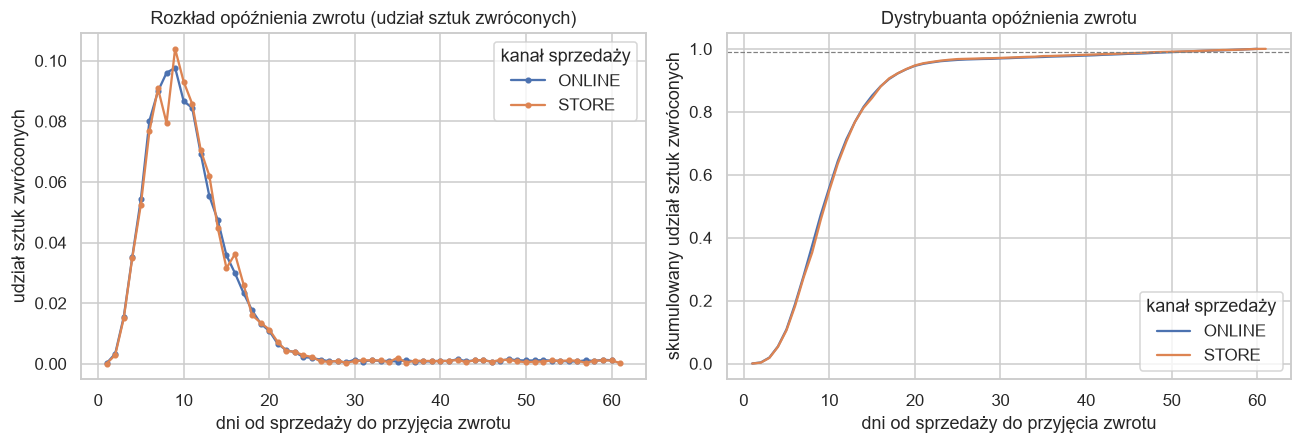

In [7]:
# Opóźnienie (w dniach) w wierszach zwrotu, ważone sztukami, dla sprzedaży w pełni obserwowanych.
FULL_OBS_END = "2026-06-01"
delay = q(f"""
SELECT k.Channel, r.ReturnReason, k.SaleDate, r.ReturnDate, r.Quantity,
       DATE_DIFF('day', k.SaleDate, r.ReturnDate) AS delay_days
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey)
WHERE k.SaleDate < DATE '{FULL_OBS_END}'
""")

def wquant(x, w, qs):
    """Kwantyle ważone sztukami zwrotu."""
    o = np.argsort(x.values)
    xs, ws = x.values[o], w.values[o]
    cw = np.cumsum(ws) / ws.sum()
    return [xs[np.searchsorted(cw, p)] for p in qs]

qs = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 1.0]
rows = []
for ch, g in list(delay.groupby("Channel")) + [("RAZEM", delay)]:
    rows.append([ch, int(g.Quantity.sum())] + wquant(g.delay_days, g.Quantity, qs))
tab = pd.DataFrame(rows, columns=["kanał", "sztuki_zwr", "P50", "P75", "P90", "P95", "P99", "P99.9", "max"])
print("Opóźnienie zwrotu w dniach (kwantyle ważone sztukami), sprzedaże sprzed", FULL_OBS_END)
display(tab)

# Udział zwrotów (sztuk) po więcej niż N dniach
for n in [7, 14, 21, 30, 45, 60]:
    row = {ch: g.loc[g.delay_days > n, "Quantity"].sum() / g.Quantity.sum() for ch, g in delay.groupby("Channel")}
    print(f"udział sztuk zwróconych po > {n:2d} dniach:", {k: f"{v:.2%}" for k, v in row.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ch, g in delay.groupby("Channel"):
    h = g.groupby("delay_days").Quantity.sum()
    axes[0].plot(h.index, h.values / h.sum(), marker=".", label=ch)
    axes[1].plot(h.index, h.cumsum().values / h.sum(), label=ch)
axes[0].set(title="Rozkład opóźnienia zwrotu (udział sztuk zwróconych)", xlabel="dni od sprzedaży do przyjęcia zwrotu", ylabel="udział sztuk zwróconych")
axes[1].set(title="Dystrybuanta opóźnienia zwrotu", xlabel="dni od sprzedaży do przyjęcia zwrotu", ylabel="skumulowany udział sztuk zwróconych")
axes[1].axhline(0.99, ls="--", c="grey", lw=0.8)
for a in axes:
    a.legend(title="kanał sprzedaży")
plt.tight_layout(); plt.show()

**Co widzę na wykresie (fakty):** rozkład ma wyraźny garb z maksimum około 9. dnia i długi, niemal płaski ogon sięgający 60 dni. Krzywe obu kanałów prawie się pokrywają. Mediana to 10 dni, P95 to 21 dni, P99 to ok. 50 dni, maksimum to 60–61 dni. Po 30 dniach przychodzi ok. 3% zwróconych sztuk, po 45 dniach ok. 1,5%.

Ogon jest dziwny: po garbie nie ma łagodnego zanikania, tylko płaska półka (ok. 0,1% sztuk na dzień przez ponad 30 dni). Sprawdzam, czy to osobna populacja (inne powody, kategorie, miesiące sprzedaży), czy tylko wydłużony koniec tego samego rozkładu. To ważne, bo decyduje, czy warto ustawić *H* na 30, czy na 60 dni.

In [8]:
delay["late"] = delay.delay_days > 30
cat_of = q("SELECT ProductKey, Category, StyleCode, Size FROM dim_product").set_index("ProductKey")
d2 = q(f"""
SELECT k.Channel, r.ReturnReason, k.SaleDate, strftime(k.SaleDate, '%Y-%m') AS ym, p.Category, r.Quantity,
       DATE_DIFF('day', k.SaleDate, r.ReturnDate) AS delay_days
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) JOIN dim_product p ON p.ProductKey = r.ProductKey
WHERE k.SaleDate < DATE '{FULL_OBS_END}'
""")
d2["late"] = d2.delay_days > 30
d2["ReturnReason"] = d2.ReturnReason.fillna("(brak)")

def late_share(df, by):
    g = df.groupby(by).apply(lambda x: pd.Series({"sztuki": x.Quantity.sum(), "udzial_po_30d": x.loc[x.late, "Quantity"].sum() / x.Quantity.sum()}), include_groups=False)
    return g

print("Udział zwrotów po 30 dniach wg powodu:")
display(late_share(d2, "ReturnReason"))
print("... wg kategorii:")
display(late_share(d2, "Category"))
print("... wg miesiąca sprzedaży:")
display(late_share(d2, "ym").T)

Udział zwrotów po 30 dniach wg powodu:


,sztuki,udzial_po_30d
ReturnReason,,
(brak),"1,420",0.0254
CHANGED_MIND,"8,531",0.0285
DAMAGED,"3,670",0.0256
OTHER,"1,988",0.0357
WRONG_SIZE,"13,923",0.0310


... wg kategorii:


,sztuki,udzial_po_30d
Category,,
Akcesoria,"1,579",0.0253
Jeansy,"9,188",0.0312
Koszule,"1,465",0.0280
Kurtki,"3,537",0.0294
Sukienki,"4,366",0.0286
Swetry,"3,153",0.0298
T-shirty,"6,244",0.0296


... wg miesiąca sprzedaży:


ym,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05
sztuki,"1,404","1,184","1,268","1,311","1,330","1,458","2,839","1,925","1,788","1,871","1,913","2,537","3,081","1,264","1,492","1,476","1,391"
udzial_po_30d,0.0349,0.0279,0.0229,0.0282,0.0278,0.0316,0.0296,0.0353,0.0308,0.0278,0.0345,0.0311,0.0302,0.0324,0.0208,0.0325,0.0201


#### 2.4 Miejsce przyjęcia zwrotu a kanał sprzedaży

**Po co:** `StoreKey` w zwrotach oznacza miejsce *przyjęcia*, nie zakupu. Jeśli się różni od kanału sprzedaży (np. towar kupiony online oddany w sklepie), wyznaczenie kanału z tabeli zwrotów dałoby błędny wskaźnik, a o tym ostrzega opis danych. Sprawdzam, jak często tak jest.

In [9]:
xt = q("""
SELECT k.Channel AS kanal_sprzedazy, r.ReturnChannel AS kanal_przyjecia, SUM(r.Quantity) AS sztuki, COUNT(*) AS wiersze
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) GROUP BY ALL ORDER BY 1, 2
""")
display(xt)

print("Sklepy stacjonarne: sklep sprzedaży vs sklep przyjęcia (sztuki zwrotu)")
display(q("""
SELECT s.StoreCode AS sklep_sprzedazy, r.ReturnStoreCode AS sklep_przyjecia, SUM(r.Quantity) AS sztuki
FROM returns_f r
JOIN (SELECT DISTINCT TransactionNo, StoreCode FROM sales_f) s USING (TransactionNo)
WHERE s.StoreCode <> 'S-ONL-01' GROUP BY ALL ORDER BY 1, 2
""").pivot(index="sklep_sprzedazy", columns="sklep_przyjecia", values="sztuki").fillna(0).astype(int))

print("Dzień tygodnia przyjęcia zwrotu (1 = poniedziałek), sztuki, osobno wg kanału przyjęcia")
display(q("""
SELECT r.ReturnChannel AS kanal_przyjecia, dayofweek(r.ReturnDate - 1) + 1 AS dzien_tyg, SUM(r.Quantity) AS sztuki
FROM returns_f r GROUP BY ALL ORDER BY 1, 2
""").pivot(index="kanal_przyjecia", columns="dzien_tyg", values="sztuki").fillna(0).astype(int))

,kanal_sprzedazy,kanal_przyjecia,sztuki,wiersze
0,ONLINE,ONLINE,"17,350",15574
1,ONLINE,STORE,"3,061",2747
2,STORE,STORE,"15,872",13998


Sklepy stacjonarne: sklep sprzedaży vs sklep przyjęcia (sztuki zwrotu)


sklep_przyjecia,S-GDA-01,S-KRK-01,S-POZ-01,S-WAW-01,S-WAW-02
sklep_sprzedazy,,,,,
S-GDA-01,2900,8,9,10,3
S-KRK-01,12,2517,6,6,10
S-POZ-01,13,11,3225,9,7
S-WAW-01,13,8,12,4346,12
S-WAW-02,7,6,5,6,2711


Dzień tygodnia przyjęcia zwrotu (1 = poniedziałek), sztuki, osobno wg kanału przyjęcia


dzien_tyg,1,2,3,4,5,6,7
kanal_przyjecia,,,,,,,
ONLINE,2496,2440,2442,2532,2472,2536,2432
STORE,5112,2814,2675,2459,2690,2736,447


**Co widzę (fakty):**
- Zakupy w sklepach stacjonarnych są zwracane zawsze w sklepach, i to prawie zawsze w tym samym sklepie, w którym je kupiono (poza przekątną tylko kilka do kilkunastu sztuk na parę sklepów).
- Zakupy online: 17 350 szt. (85%) zwrócono przez sklep internetowy, ale **3 061 szt. (15%) oddano w sklepie stacjonarnym**.
- W sklepach zwroty są przyjmowane w dni otwarcia: w poniedziałek jest skok (5 112 szt. wobec ok. 2 500-2 800 w inne dni), w niedzielę tylko 447 szt. (niedziele handlowe). To naturalna konsekwencja zamknięcia sklepów, nie anomalia.

**Wniosek/decyzja:** kanał sprzedaży trzeba brac **z paragonu**, nie z miejsca przyjęcia. Gdyby kanał wziąć z tabeli zwrotów, 15% zwrotów z sprzedaży online trafiłoby do sklepów, zaniżając wskaźnik online o ok. 2,7 pp, a zawyżając wskaźnik sklepów (ok. 3 061 dodatkowych sztuk na ok. 15 872 własnych, czyli +19%). Taka pułapka jest zapisana w opisie danych; tu mam potwierdzenie liczbowe.

#### 2.5 Braki w powodzie zwrotu i pokrycie dat zwrotów

**Po co:** powód zwrotu (`ReturnReason`) wpisuje obsługa i bywa pusty. Jeśli braki są nierównomierne (np. częściej online albo w pewnych miesiącach), analiza powodów będzie obciążona. Sprawdzam też, czy zwroty są kompletne od początku okresu: gdyby portal zaczął rejestrować zwroty dopiero później, wskaźnik zwrotów dla najwcześniejszych sprzedaży byłby sztucznie niski.

powod,(brak),CHANGED_MIND,DAMAGED,OTHER,WRONG_SIZE
Channel,,,,,
ONLINE,4.9%,25.3%,9.0%,5.9%,54.9%
STORE,4.8%,34.0%,16.5%,7.8%,36.9%


Udział brakujących powodów wg miesiąca przyjęcia (min / mediana / max po miesiącach), osobno kanał:


,min,50%,max
kanal,,,
ONLINE,0.0344,0.0512,0.0662
STORE,0.0367,0.0450,0.0568


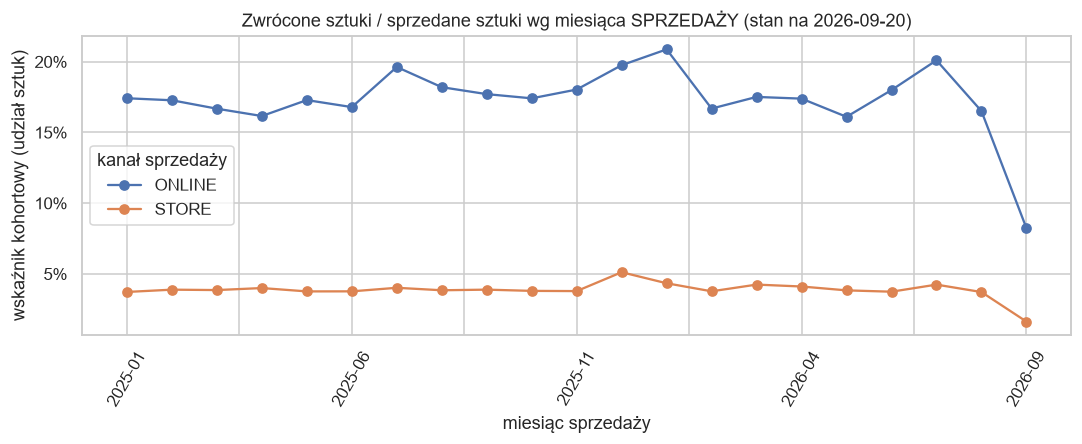

ym_sprzedazy,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
kanal,,,,,,,,,,,,,,,,,,,,,
ONLINE,0.1742,0.1727,0.1668,0.1616,0.1729,0.1679,0.1963,0.1820,0.1771,0.1741,0.1803,0.1976,0.2087,0.1669,0.1751,0.1739,0.1610,0.1800,0.2010,0.1651,0.0824
STORE,0.0372,0.0389,0.0386,0.0400,0.0376,0.0377,0.0402,0.0384,0.0389,0.0380,0.0378,0.0512,0.0434,0.0377,0.0424,0.0411,0.0384,0.0374,0.0424,0.0372,0.0163


In [10]:
rs = q("""
SELECT k.Channel, COALESCE(r.ReturnReason, '(brak)') AS powod, SUM(r.Quantity) AS sztuki
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) GROUP BY ALL ORDER BY 1, 2
""")
rs["udzial"] = rs.sztuki / rs.groupby("Channel").sztuki.transform("sum")
display(rs.pivot(index="Channel", columns="powod", values="udzial").style.format("{:.1%}"))

# Czy braki powodu zmieniają się w czasie? udział braków wg miesiąca przyjęcia zwrotu
miss = q("""
SELECT strftime(ReturnDate, '%Y-%m') AS ym, ReturnChannel AS kanal, SUM(Quantity) AS sztuki,
       SUM(CASE WHEN ReturnReason IS NULL THEN Quantity ELSE 0 END) / SUM(Quantity) AS udzial_brakow
FROM returns_f GROUP BY ALL ORDER BY 1, 2
""")
print("Udział brakujących powodów wg miesiąca przyjęcia (min / mediana / max po miesiącach), osobno kanał:")
display(miss.groupby("kanal").udzial_brakow.describe()[["min", "50%", "max"]])

# Wskaźnik kohortowy (zwroty przypisane do daty sprzedaży) wg miesiąca sprzedaży: pokrycie początku i ocenzurowanie końca
coh = q("""
SELECT strftime(k.SaleDate, '%Y-%m') AS ym_sprzedazy, k.Channel AS kanal, SUM(k.sold_qty) AS sold, COALESCE(SUM(r.ret_qty), 0) AS ret
FROM sales_key k LEFT JOIN returns_key r USING (TransactionNo, ProductKey) GROUP BY ALL ORDER BY 1, 2
""")
coh["wsk"] = coh.ret / coh.sold
piv = coh.pivot(index="ym_sprzedazy", columns="kanal", values="wsk")
fig, ax = plt.subplots(figsize=(10, 4.2))
piv.plot(ax=ax, marker="o")
ax.set(title="Zwrócone sztuki / sprzedane sztuki wg miesiąca SPRZEDAŻY (stan na 2026-09-20)", xlabel="miesiąc sprzedaży", ylabel="wskaźnik kohortowy (udział sztuk)")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.legend(title="kanał sprzedaży"); plt.xticks(rotation=60); plt.tight_layout(); plt.show()
display(piv.round(4).T)

**Co widzę (fakty):**
- Brak powodu zwrotu to ok. 4,5-5% sztuk i jest stabilny w czasie (miesięczne wartości od 3,4% do 6,6% online i od 3,7% do 5,7% w sklepach); nie widać okresu, w którym pole przestało być wypełniane.
- Zwroty są w hurtowni od początku okresu (pierwszy 2025-01-06), a wskaźnik kohortowy dla pierwszych miesięcy (online 17%, sklepy 3,7-3,9%) jest na poziomie późniejszych. Zatem **historia zwrotów wygląda na kompletną**, zgodnie z założeniem z opisu zadania.
- Wskaźnik kohortowy online waha się między ok. 16% a 21%, z podwyższeniem w lipcu 2025 (19,6%), w grudniu 2025 i styczniu 2026 (19,8% i 20,9%) oraz w lipcu 2026 (20,1%). W sklepach zwykle 3,7-4,3%, w grudniu 2025 wyraźnie więcej (5,1%).
- Ostatni miesiąc (2026-09) i końcówka sierpnia mają niski wskaźnik (8% online i 1,6% w sklepach) **wyłącznie z powodu cenzurowania**: zwroty tych sprzedaży jeszcze nie przyszły.

**Interpretacja (hipotezy robocze, nie wnioski):** lipiec i grudzień-styczeń to okresy wyprzedaży, więc podwyższenie zwrotów online może mieć związek z rabatem (H5) albo z innym składem sprzedaży w tych miesiącach. Do rozstrzygnięcia w Fazie 3 i w modelu.

**Brak w danych (do pytań):** nie wiem, czy powód zwrotu bywa pusty losowo, czy dlatego, że obsługa pomija go przy konkretnych typach zwrotów. Dla analizy opisowej powodów przyjmuję, że braki są losowe (ok. 5%).

### Dziennik pracy (Fazy 1-2)

- **Zrobiłem:** rozdzieliłem zlecenie na trzy decyzje, sprawdziłem złączenie zwrotów ze sprzedażą (100% pary, brak nadmiaru, brak zwrotów przed sprzedażą), opóźnienie (mediana 10 dni, P99 50 dni), kanał przyjęcia vs kanał sprzedaży i braki w powodzie.
- **Zaskoczyło mnie:** (1) 15% zwrotów z zakupów online jest przyjmowane w sklepach stacjonarnych, (2) ogon opóźnienia jest płaski i równomierny, a nie zanikający, (3) podwójne zwroty tego samego klucza w dniu 2025-09-24 to nie duplikat, tylko dwa zwroty po jednej sztuce, w dwóch miejscach (przy 3 sztukach sprzedanych w dwóch liniach).
- **Zdecydowałem:** poziom klucza (`TransactionNo` × `ProductKey`) dla 0,34% kluczy z dwiema liniami; kanał ze sprzedaży; *H* = 50 dni; koszt = wartość zwrotów netto.
- **Odrzuciłem:** traktowanie 2 wierszy zwrotu z 2025-09-24 jako duplikatu do usunięcia (różne `ReturnNo`, różne miejsca przyjęcia, suma 2 sztuk mieści się w 3 sprzedanych).

### Faza 1 (część b): okno zwrotu H i etykieta (decyzja z danych)

**Po co:** z rozkładu opóźnień (sekcja 2.3) muszę wybrać *H*, czyli po ilu dniach od sprzedaży uznaję etykietę „zwrócono / nie zwrócono" za zamkniętą. Zanim wybiorę, sprawdzam jedno: czy płaski ogon (zwroty po 30. dniu) jest osobną populacją, np. skupioną w kilku modelach albo rozmiarach, czy tylko równomiernym tłem.

In [11]:
# Ogon opóźnienia (>30 dni) wg modelu, rozmiaru i cen: czy jest skupiony, czy rozproszony?
tail_df = q(f"""
SELECT p.StyleCode, p.Size, p.Category, r.Quantity, DATE_DIFF('day', k.SaleDate, r.ReturnDate) AS delay_days
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) JOIN dim_product p ON p.ProductKey = r.ProductKey
WHERE k.SaleDate < DATE '{FULL_OBS_END}'
""")
tail_df["late"] = tail_df.delay_days > 30
by_style = tail_df.groupby("StyleCode").apply(lambda x: pd.Series({"sztuki": x.Quantity.sum(), "udzial_po_30d": x.loc[x.late, "Quantity"].sum() / x.Quantity.sum()}), include_groups=False)
by_size = tail_df.groupby("Size").apply(lambda x: pd.Series({"sztuki": x.Quantity.sum(), "udzial_po_30d": x.loc[x.late, "Quantity"].sum() / x.Quantity.sum()}), include_groups=False)
print("Udział zwrotów po 30 dniach wg rozmiaru:")
display(by_size.T)
print("Wg modelu (36 modeli): min / mediana / max udziału oraz rozrzut oczekiwany przy czysto losowym podziale (przybliżenie dwumianowe)")
p0 = tail_df.loc[tail_df.late, "Quantity"].sum() / tail_df.Quantity.sum()
sd_exp = np.sqrt(p0 * (1 - p0) / by_style.sztuki)
print(f"średnio {p0:.3%}; obserwowany SD między modelami = {by_style.udzial_po_30d.std():.4f}; oczekiwany SD przy losowości = {np.sqrt((sd_exp**2).mean()):.4f}")
display(by_style.udzial_po_30d.describe()[["min", "50%", "max"]].to_frame().T)

Udział zwrotów po 30 dniach wg rozmiaru:


Size,L,M,ONE,S,XL,XS
sztuki,"7,669","7,973","1,579","5,514","4,445","2,352"
udzial_po_30d,0.0305,0.0291,0.0253,0.0299,0.0263,0.0374


Wg modelu (36 modeli): min / mediana / max udziału oraz rozrzut oczekiwany przy czysto losowym podziale (przybliżenie dwumianowe)
średnio 2.966%; obserwowany SD między modelami = 0.0290; oczekiwany SD przy losowości = 0.0244


,min,50%,max
udzial_po_30d,0,0.0261,0.1290


**Co widzę (fakty):** udział zwrotów po 30. dniu jest podobny we wszystkich rozmiarach (2,5-3,7%), powodach i kategoriach (2,5-3,6%, patrz poprzedni krok), a średnio wynosi ok. 3%. Rozrzut między modelami (SD 0,029) jest tylko nieco większy niż przy czystej losowości (0,024), a skrajne wartości (od 0 do 12,9%) pochodzą z modeli, które mają w tej kohorcie niewiele zwrotów. Nie ma segmentu, który tłumaczy ogon.

**Interpretacja i decyzja:** ogon to równomierne tło (ok. 0,1% zwrotów dziennie po 30. dniu), a nie osobny problem. Moja decyzja: **H = 50 dni**. Mieści się w nim ok. 99% zwróconych sztuk (P99 = 50 dni, patrz 2.3); dłuższe okno ujęłoby jeszcze ok. 1% zwróconych sztuk, ale kosztowałoby kolejne 10 dni sprzedaży bez etykiety. Wybór nie jest obojętny, więc główne wyniki powtórzę dla H = 30 i 61 w teście odporności (Faza 7). Skutek cenzurowania: sprzedaże po 2026-08-01 nie mają pełnej etykiety i są wykluczone z uczenia i oceny (dotyczy ok. 9% kluczy).

### Faza 1 (część c): tabela robocza na poziomie klucza (paragon × produkt) z etykietą kohortową

**Po co:** do wszystkich dalszych kroków potrzebuję jednej tabeli: wiersz = klucz (`TransactionNo` × `ProductKey`, rozstrzygnięcie z 2.2), kolumny = cechy znane **w chwili sprzedaży** oraz wynik (ile sztuk wróciło w ciągu *H* dni, ile w ogóle do 2026-09-20 i z jakim powodem).

**Odstępstwo od słownika metryk (jawnie):** słownik definiuje wskaźnik zwrotów jako sztuki zwrócone w okresie / sztuki sprzedane w tym samym okresie i przekroju, czyli zwrot ma datę i sklep **przyjęcia**. To dobra definicja do pytania „ile zwrotów obsłużymy w tygodniu", ale zła do pytania „jak ryzykowny jest ten zakup": zwrot przychodzi po 10-20 dniach, a często w innym miejscu (3 061 szt. kupionych online oddano w sklepie). Stosuję więc **wskaźnik kohortowy**: zwroty przypisane do *daty i kanału sprzedaży* przez (`TransactionNo`, `ProductKey`); mianownik to sprzedane sztuki, licznik to sztuki zwrócone z tej sprzedaży. Poniżej pokazuję, jak się różnią.

**Cechy z chwili sprzedaży**, które buduję (wszystkie wynikają z samego paragonu, ceny i kalendarza; żadna nie używa informacji o zwrotach):
- produkt: model, kategoria, rozmiar, cena katalogowa, kolekcja (sezon w dniu sprzedaży: `SS`/`AW`);
- cena i rabat: stopa rabatu w pozycji (`DiscountAmount` / `Quantity × UnitPrice`);
- kalendarz: miesiąc, dzień tygodnia, wiek sezonu (dni od początku sezonu);
- zawartość tego samego paragonu: liczba pozycji i sztuk, wartość koszyka, **liczba rozmiarów tego samego modelu na paragonie** (kupno „w kilku rozmiarach na próbę" to klasyczny sygnał zwrotu).

In [12]:
H = 50  # okno zwrotu (dni), wybór uzasadniony w następnym kroku
LAST_DATE = pd.Timestamp("2026-09-20")
LABEL_CLOSED_BEFORE = (LAST_DATE - pd.Timedelta(days=H)).date()  # sprzedaże <= tej daty mają pełne okno H

dk_path = CACHE / "dk.parquet"
if not dk_path.exists():
    con.execute(f"""
    CREATE OR REPLACE TABLE dk AS
    WITH l AS (
      SELECT s.TransactionNo, s.LineNumber, s.ProductKey, s.SaleDate, s.Channel, s.StoreCode, s.Quantity, s.UnitPrice,
             s.DiscountAmount, s.GrossAmount, p.StyleCode, p.Category, p.Size, p.ListPrice
      FROM sales_f s JOIN dim_product p USING (ProductKey)),
    basket AS (
      SELECT TransactionNo, COUNT(*) AS n_lines, SUM(Quantity) AS n_units, SUM(GrossAmount) AS basket_gross,
             COUNT(DISTINCT Category) AS n_cat
      FROM l GROUP BY 1),
    same_style AS (
      SELECT TransactionNo, StyleCode, COUNT(DISTINCT ProductKey) AS n_sku_style, COUNT(DISTINCT Size) AS n_size_style,
             SUM(Quantity) AS qty_style
      FROM l GROUP BY 1, 2),
    keyed AS (
      SELECT TransactionNo, ProductKey, ANY_VALUE(SaleDate) AS SaleDate, ANY_VALUE(Channel) AS Channel,
             ANY_VALUE(StoreCode) AS StoreCode, ANY_VALUE(StyleCode) AS StyleCode, ANY_VALUE(Category) AS Category,
             ANY_VALUE(Size) AS Size, ANY_VALUE(ListPrice) AS ListPrice, COUNT(*) AS n_linii, SUM(Quantity) AS sold_qty,
             SUM(DiscountAmount) / SUM(Quantity * UnitPrice) AS disc_rate, SUM(GrossAmount) AS gross
      FROM l GROUP BY 1, 2),
    rr AS (
      SELECT r.TransactionNo, r.ProductKey,
             SUM(r.Quantity) AS ret_qty_all,
             SUM(CASE WHEN DATE_DIFF('day', k.SaleDate, r.ReturnDate) <= {H} THEN r.Quantity ELSE 0 END) AS ret_qty_h,
             SUM(CASE WHEN DATE_DIFF('day', k.SaleDate, r.ReturnDate) <= 30 THEN r.Quantity ELSE 0 END) AS ret_qty_30,
             SUM(CASE WHEN r.ReturnReason = 'WRONG_SIZE' THEN r.Quantity ELSE 0 END) AS q_wrong_size,
             SUM(CASE WHEN r.ReturnReason = 'CHANGED_MIND' THEN r.Quantity ELSE 0 END) AS q_changed_mind,
             SUM(CASE WHEN r.ReturnReason = 'DAMAGED' THEN r.Quantity ELSE 0 END) AS q_damaged,
             SUM(CASE WHEN r.ReturnReason = 'OTHER' THEN r.Quantity ELSE 0 END) AS q_other,
             SUM(CASE WHEN r.ReturnReason IS NULL THEN r.Quantity ELSE 0 END) AS q_noreason,
             SUM(r.ReturnAmount) AS ret_amount_gross
      FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) GROUP BY 1, 2)
    SELECT k.*, b.n_lines, b.n_units, b.basket_gross, b.n_cat, ss.n_sku_style, ss.n_size_style, ss.qty_style,
           d.Season, d.IsoYear, d.IsoWeek, d.DayOfWeek,
           COALESCE(rr.ret_qty_all, 0) AS ret_qty_all, COALESCE(rr.ret_qty_h, 0) AS ret_qty_h, COALESCE(rr.ret_qty_30, 0) AS ret_qty_30,
           COALESCE(rr.q_wrong_size, 0) AS q_wrong_size, COALESCE(rr.q_changed_mind, 0) AS q_changed_mind,
           COALESCE(rr.q_damaged, 0) AS q_damaged, COALESCE(rr.q_other, 0) AS q_other, COALESCE(rr.q_noreason, 0) AS q_noreason,
           COALESCE(rr.ret_amount_gross, 0) AS ret_amount_gross
    FROM keyed k
    JOIN basket b USING (TransactionNo)
    JOIN same_style ss ON ss.TransactionNo = k.TransactionNo AND ss.StyleCode = k.StyleCode
    JOIN dim_date d ON d.DateKey = CAST(strftime(k.SaleDate, '%Y%m%d') AS INTEGER)
    LEFT JOIN rr ON rr.TransactionNo = k.TransactionNo AND rr.ProductKey = k.ProductKey
    """)
    con.execute(f"COPY dk TO '{dk_path.as_posix()}' (FORMAT PARQUET)")
dk = pd.read_parquet(dk_path)
dk["SaleDate"] = pd.to_datetime(dk["SaleDate"])
dk["Month"] = dk.SaleDate.dt.to_period("M").astype(str)
dk["labeled"] = dk.SaleDate.dt.date <= LABEL_CLOSED_BEFORE
print("dk:", dk.shape, "| sztuki sprzedane:", int(dk.sold_qty.sum()), "| sztuki zwrócone (wszystkie):", int(dk.ret_qty_all.sum()))
print("Kontrola z audytem: oczekiwano 520 513 sprzedanych i 36 283 zwróconych sztuk;", "OK" if (dk.sold_qty.sum() == 520513 and dk.ret_qty_all.sum() == 36283) else "NIEZGODNOŚĆ")
print(f"Etykieta zamknięta (okno {H} dni) dla sprzedaży do {LABEL_CLOSED_BEFORE}: {dk.labeled.mean():.1%} kluczy")
display(dk.head(3))

dk: (431814, 35) | sztuki sprzedane: 520513 | sztuki zwrócone (wszystkie): 36283
Kontrola z audytem: oczekiwano 520 513 sprzedanych i 36 283 zwróconych sztuk; OK
Etykieta zamknięta (okno 50 dni) dla sprzedaży do 2026-08-01: 91.2% kluczy


,TransactionNo,ProductKey,SaleDate,Channel,StoreCode,StyleCode,Category,Size,ListPrice,n_linii,sold_qty,disc_rate,gross,n_lines,n_units,...,Season,IsoYear,IsoWeek,DayOfWeek,ret_qty_all,ret_qty_h,ret_qty_30,q_wrong_size,q_changed_mind,q_damaged,q_other,q_noreason,ret_amount_gross,Month,labeled
0,T-S-ONL-01-20250101-0009,13,2025-01-01,ONLINE,S-ONL-01,W-JKT-002,Kurtki,M,499,1,1,0,499,1,1,...,AW24,2025,1,3,0,0,0,0,0,0,0,0,0,2025-01,True
1,T-S-ONL-01-20250101-0022,2,2025-01-01,ONLINE,S-ONL-01,W-JKT-001,Kurtki,S,399,1,1,0,399,2,2,...,AW24,2025,1,3,0,0,0,0,0,0,0,0,0,2025-01,True
2,T-S-WAW-01-20250102-0043,113,2025-01-02,STORE,S-WAW-01,M-SHI-001,Koszule,M,199,1,1,0,199,2,2,...,AW24,2025,1,4,0,0,0,0,0,0,0,0,0,2025-01,True


#### Dobór H: ile zwrotów tracę przy różnych oknach i ile danych zostaje

**Po co:** *H* to kompromis. Krótkie *H* ucina prawdziwe zwroty (etykieta zaniżona, ale równomiernie we wszystkich segmentach), długie *H* odbiera ostatnie tygodnie sprzedaży (ocenzurowane).

In [13]:
rows = []
tot = dk.loc[dk.SaleDate < FULL_OBS_END]
for h in [21, 30, 45, 50, 60, 61]:
    kept = LAST_DATE - pd.Timedelta(days=h)
    n_lab = dk.loc[dk.SaleDate <= kept, "sold_qty"].sum()
    # udział zwrotów całkowitych, które mieszczą się w oknie h (na kohorcie w pełni obserwowanej)
    d_h = delay.loc[delay.delay_days <= h, "Quantity"].sum() / delay.Quantity.sum()
    rows.append([h, d_h, kept.date(), n_lab / dk.sold_qty.sum()])
hh = pd.DataFrame(rows, columns=["H (dni)", "udział zwrotów w oknie", "ostatnia sprzedaż z pełnym oknem", "udział sprzedanych szt. z pełną etykietą"])
hh["udział zwrotów w oknie"] = hh["udział zwrotów w oknie"].map("{:.2%}".format)
hh["udział sprzedanych szt. z pełną etykietą"] = hh["udział sprzedanych szt. z pełną etykietą"].map("{:.1%}".format)
print(hh.to_string(index=False))

 H (dni) udział zwrotów w oknie ostatnia sprzedaż z pełnym oknem udział sprzedanych szt. z pełną etykietą
      21                 95.33%                       2026-08-30                                    96.1%
      30                 97.03%                       2026-08-21                                    94.3%
      45                 98.51%                       2026-08-06                                    91.9%
      50                 99.01%                       2026-08-01                                    91.2%
      60                 99.99%                       2026-07-22                                    88.4%
      61                100.00%                       2026-07-21                                    88.2%


### Wskaźnik kohortowy a wskaźnik słownikowy: jak bardzo się różnią

**Po co:** pokazać zleceniodawcy (i sobie), że wybór definicji zmienia liczby. Słownikowy: sztuki przyjęte w miesiącu / sztuki sprzedane w tym samym miesiącu, kanał = miejsce przyjęcia. Kohortowy: zwroty przypisane do miesiąca i kanału sprzedaży (z kontrolą cenzurowania: pokazuję tylko miesiące z domkniętym oknem).

wsk_slownik        wsk_kohortowy        roznica_pp        
Channel      ONLINE  STORE        ONLINE  STORE     ONLINE   STORE
ym                                                                
2025-01      0.0918 0.0265        0.1721 0.0368    -8.0333 -1.0284
2025-02      0.1538 0.0469        0.1709 0.0386    -1.7032  0.8269
2025-06      0.1344 0.0424        0.1663 0.0369    -3.1917  0.5483
2025-07      0.1181 0.0398        0.1941 0.0397    -7.6046  0.0074
2025-12      0.1876 0.0654        0.1952 0.0509    -0.7586  1.4492
2026-01      0.1401 0.0396        0.2068 0.0430    -6.6720 -0.3355
2026-02      0.2501 0.0709        0.1654 0.0374     8.4667  3.3573
2026-06      0.1371 0.0426        0.1789 0.0370    -4.1847  0.5537
2026-07      0.1363 0.0445        0.1992 0.0420    -6.2886  0.2446

Zakres różnic słownik - kohortowy (pp) wg kanału, wszystkie miesiące:


,min,50%,max
Channel,,,
ONLINE,-8.0333,-2.9768,8.4667
STORE,-1.0284,0.7364,3.3573


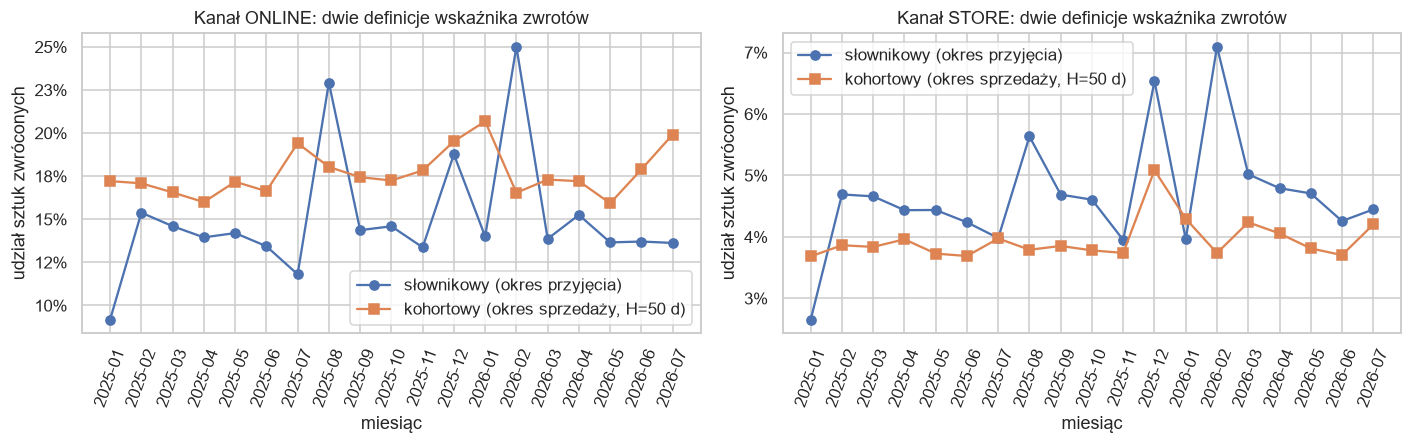

In [14]:
dic = q("""
WITH s AS (SELECT strftime(SaleDate, '%Y-%m') AS ym, Channel, SUM(Quantity) AS sold FROM sales_f GROUP BY ALL),
     r AS (SELECT strftime(ReturnDate, '%Y-%m') AS ym, ReturnChannel AS Channel, SUM(Quantity) AS ret FROM returns_f GROUP BY ALL)
SELECT s.ym, s.Channel, s.sold, COALESCE(r.ret, 0) AS ret_dict FROM s LEFT JOIN r USING (ym, Channel) ORDER BY 1, 2""")
dic["wsk_slownik"] = dic.ret_dict / dic.sold
agg_k = dk[dk.labeled & (dk.Month < "2026-08")].groupby(["Month", "Channel"]).apply(lambda x: pd.Series({"wsk_kohortowy": x.ret_qty_h.sum() / x.sold_qty.sum()}), include_groups=False).reset_index()
cmp_ = dic.merge(agg_k, left_on=["ym", "Channel"], right_on=["Month", "Channel"]).drop(columns="Month")
cmp_["roznica_pp"] = (cmp_.wsk_slownik - cmp_.wsk_kohortowy) * 100
wide = cmp_.pivot(index="ym", columns="Channel", values=["wsk_slownik", "wsk_kohortowy", "roznica_pp"])
display(wide.round(4).iloc[[0, 1, 5, 6, 11, 12, 13, -2, -1]])
print("Zakres różnic słownik - kohortowy (pp) wg kanału, wszystkie miesiące:")
display(cmp_.groupby("Channel").roznica_pp.describe()[["min", "50%", "max"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, ch in zip(axes, ["ONLINE", "STORE"]):
    g = cmp_[cmp_.Channel == ch]
    ax.plot(g.ym, g.wsk_slownik, marker="o", label="słownikowy (okres przyjęcia)")
    ax.plot(g.ym, g.wsk_kohortowy, marker="s", label=f"kohortowy (okres sprzedaży, H={H} d)")
    ax.set(title=f"Kanał {ch}: dwie definicje wskaźnika zwrotów", xlabel="miesiąc", ylabel="udział sztuk zwróconych")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0)); ax.tick_params(axis="x", rotation=70); ax.legend()
plt.tight_layout(); plt.show()

### Faza 3: eksploracja pod hipotezy

**Po co:** zobaczyć, gdzie wskaźnik zwrotów (kohortowy, okno H) się różni, zanim sformułuję formalne hipotezy i zbuduję modele. Wszędzie kanał jest osobno, bo różnica bazowa (ok. 18% vs 4%) przykryłaby wszystko inne.

**Dyscyplina danych (ważne dla uczciwości testów):** wcześniej ustalam podział w czasie wg daty sprzedaży i **eksploruję wyłącznie okres treningowy**, żeby walidacja i test pozostały „nieobejrzane":
- trening: sprzedaże od 2025-01-01 do 2026-02-09,
- strefa ochronna: 2026-02-10 … 2026-03-31 (50 dni = *H*; w dniu 2026-04-01 etykiety sprzedaży z tego okresu nie byłyby jeszcze znane, więc ich nie używam do uczenia),
- walidacja (wybór modeli): 2026-04-01 … 2026-05-31,
- test (jedna ocena końcowa): 2026-06-01 … 2026-08-01 (ostatnie sprzedaże z pełnym oknem *H*).

Wyjątek: wykres opóźnień i miesięczne wskaźniki z audytu (sekcje 2.3 i 2.5) pokazały agregaty z całego okresu; nie wpływają na wybór modeli, ale zapisuję to jako fakt.

**Uwaga o przedziałach:** przedziały Wilsona (dla proporcji) w tej sekcji liczę na sztukach, jakby były niezależne. Sztuki z jednego paragonu są zależne, więc te przedziały są lekko za wąskie. Do testów formalnych użyję poprawek klastrowych (błędy po paragonie, bootstrap).

split   pomijane   test   train    val
klucze    66,226 50,609 279,079 35,900
sztuki    79,841 61,062 336,309 43,301
Dane do eksploracji: 279,079 kluczy, 336,309 sprzedanych szt. (okres treningowy do 2026-02-09)


,Channel,sold,ret,rate,lo,hi
0,ONLINE,"75,930","13,720",18.07%,17.80%,18.34%
1,STORE,"260,379","10,368",3.98%,3.91%,4.06%


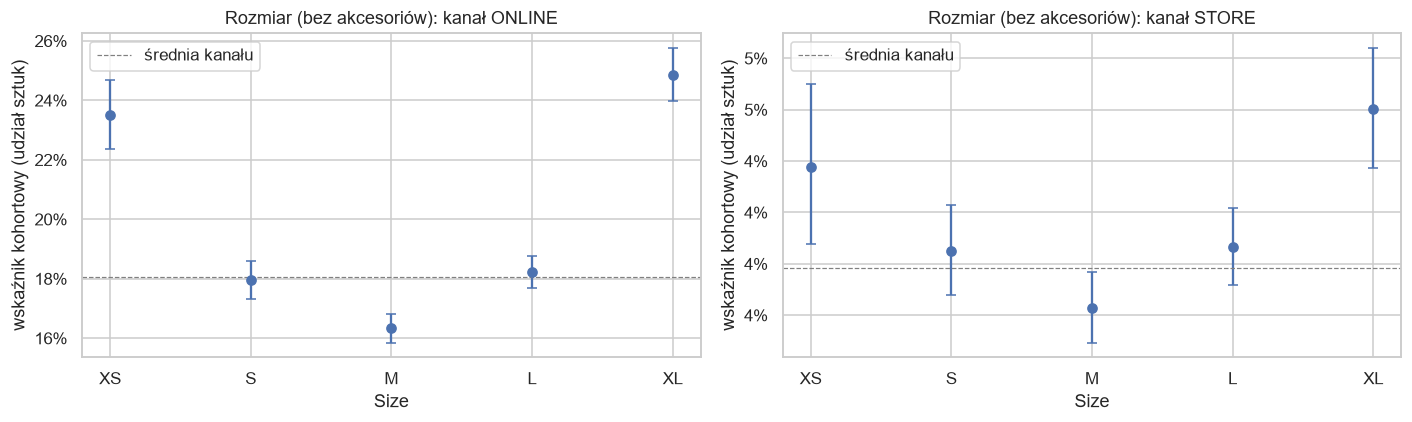

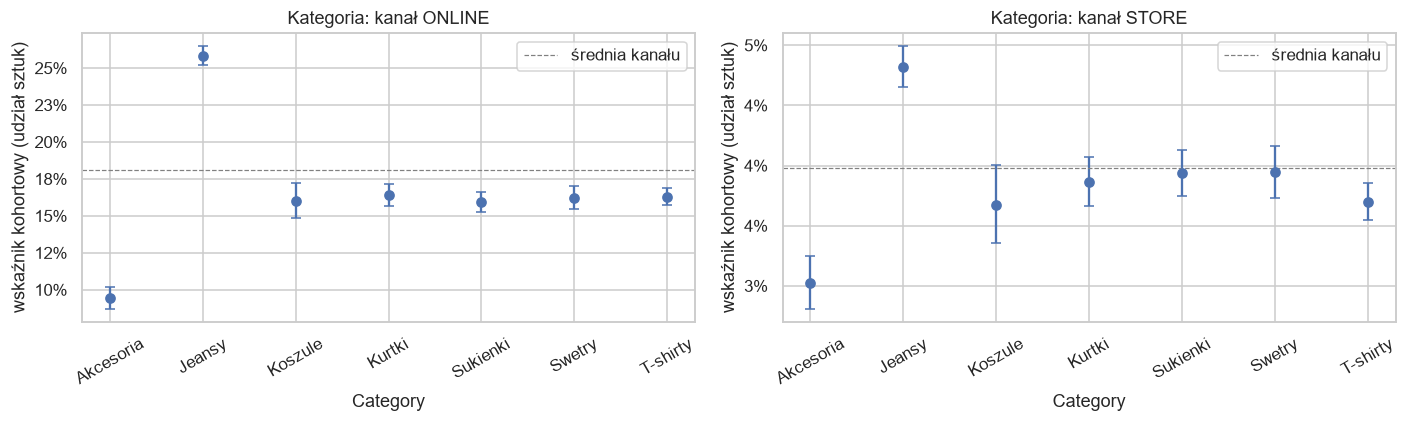

,Channel,Size,Category,sold,rate,lo,hi
0,ONLINE,L,,"19,581",0.1822,0.1768,0.1876
1,ONLINE,M,,"21,969",0.1633,0.1585,0.1683
2,ONLINE,S,,"14,074",0.1796,0.1733,0.1860
3,ONLINE,XL,,"9,045",0.2486,0.2398,0.2577
4,ONLINE,XS,,"5,167",0.2351,0.2238,0.2469
5,STORE,L,,"65,837",0.0406,0.0392,0.0422
6,STORE,M,,"75,373",0.0383,0.0369,0.0397
7,STORE,S,,"48,100",0.0405,0.0388,0.0423
8,STORE,XL,,"30,840",0.0460,0.0437,0.0484
9,STORE,XS,,"16,585",0.0438,0.0408,0.0470


In [15]:
from scipy import stats

TRAIN_END = pd.Timestamp("2026-02-10")   # trening: sprzedaż < tej daty
VAL_START, VAL_END = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-06-01")
TEST_START, TEST_END = pd.Timestamp("2026-06-01"), pd.Timestamp("2026-08-02")
dk["split"] = np.select([dk.SaleDate < TRAIN_END, (dk.SaleDate >= VAL_START) & (dk.SaleDate < VAL_END),
                         (dk.SaleDate >= TEST_START) & (dk.SaleDate < TEST_END)], ["train", "val", "test"], "pomijane")
print(dk.groupby("split").agg(klucze=("sold_qty", "size"), sztuki=("sold_qty", "sum")).T)
L = dk[dk.split == "train"].copy()  # eksploracja tylko na treningu (domknięte okno H z konstrukcji podziału)
L["disc_bin"] = pd.cut(L.disc_rate, [-0.001, 0.0001, 0.15, 0.25, 0.35, 0.45, 1.0], labels=["0%", "(0,15%]", "(15,25%]", "(25,35%]", "(35,45%]", ">45%"])
L["price_bin"] = pd.qcut(L.ListPrice, 5, duplicates="drop")
L["ret_rate"] = L.ret_qty_h / L.sold_qty

def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

def rate_table(df, by, min_n=0):
    g = df.groupby(["Channel"] + (by if isinstance(by, list) else [by]), observed=True).agg(sold=("sold_qty", "sum"), ret=("ret_qty_h", "sum")).reset_index()
    g["rate"] = g.ret / g.sold
    g["lo"], g["hi"] = wilson(g.ret, g.sold)
    return g[g.sold >= min_n]

print(f"Dane do eksploracji: {len(L):,} kluczy, {int(L.sold_qty.sum()):,} sprzedanych szt. (okres treningowy do {(TRAIN_END - pd.Timedelta(days=1)).date()})")
tot = rate_table(L.assign(all="razem"), "all")
display(tot[["Channel", "sold", "ret", "rate", "lo", "hi"]].style.format({"rate": "{:.2%}", "lo": "{:.2%}", "hi": "{:.2%}", "sold": "{:,.0f}", "ret": "{:,.0f}"}))

def plot_rate(df, by, title, order=None, rot=0, ax_pair=None):
    t = rate_table(df, by)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, ch in zip(axes, ["ONLINE", "STORE"]):
        g = t[t.Channel == ch]
        if order is not None:
            g = g.set_index(by).loc[[o for o in order if o in set(g[by])]].reset_index()
        ax.errorbar(range(len(g)), g.rate, yerr=[g.rate - g.lo, g.hi - g.rate], fmt="o", capsize=3)
        ax.set_xticks(range(len(g))); ax.set_xticklabels(g[by].astype(str), rotation=rot)
        ax.axhline(tot.loc[tot.Channel == ch, "rate"].iloc[0], ls="--", c="grey", lw=0.8, label="średnia kanału")
        ax.set(title=f"{title}: kanał {ch}", xlabel=by, ylabel="wskaźnik kohortowy (udział sztuk)")
        ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0)); ax.legend()
    plt.tight_layout(); plt.show()
    return t

t_size = plot_rate(L[L.Size != "ONE"], "Size", "Rozmiar (bez akcesoriów)", order=["XS", "S", "M", "L", "XL"])
t_cat = plot_rate(L, "Category", "Kategoria", rot=30)
display(pd.concat([t_size, t_cat], ignore_index=True)[["Channel", "Size", "Category", "sold", "rate", "lo", "hi"]].round(4).fillna(""))

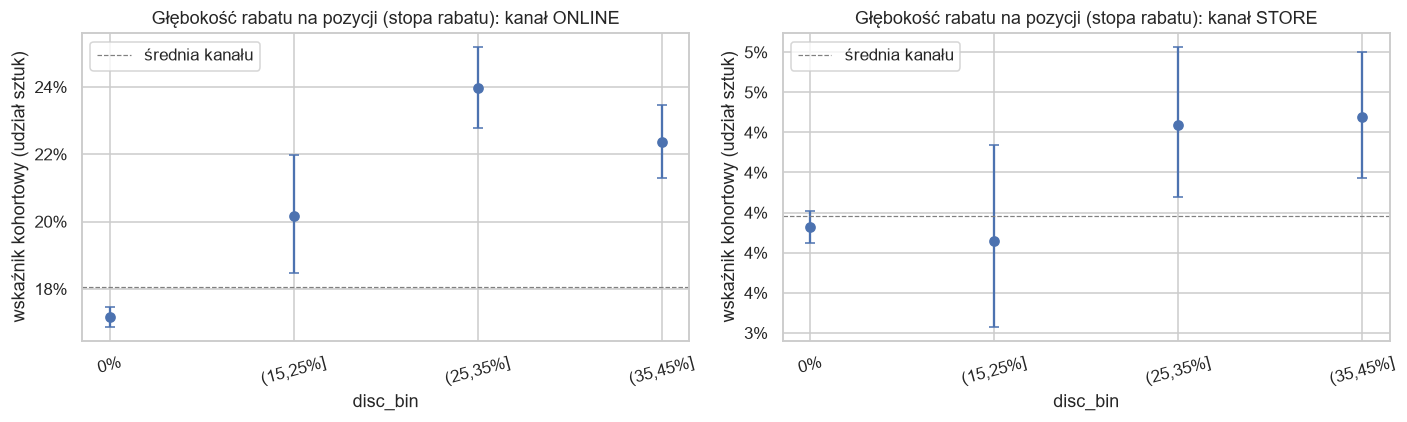

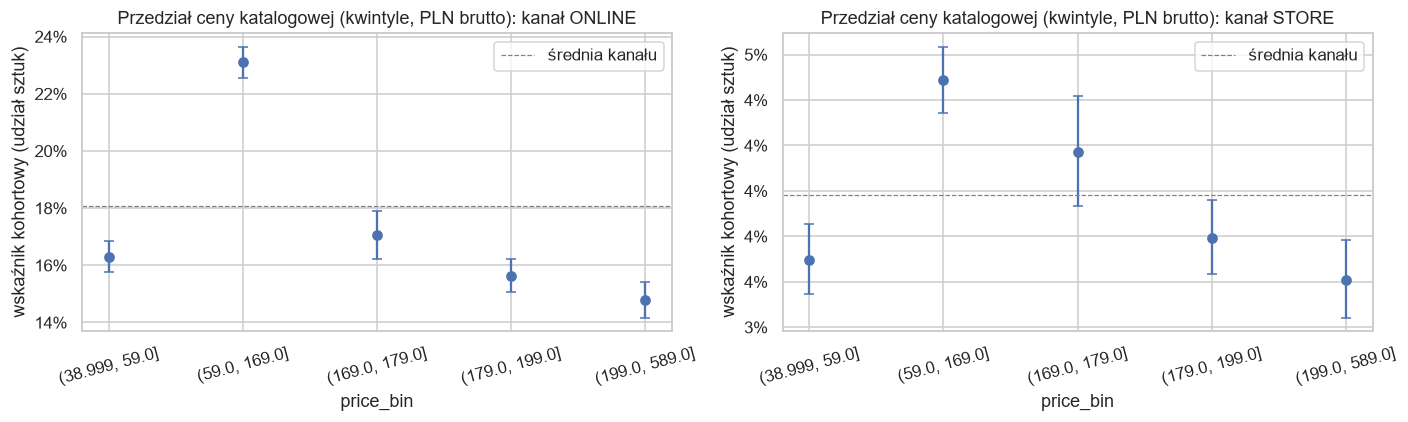

,Channel,przedzial,sold,rate,lo,hi
0,ONLINE,0%,"63,415",0.1717,0.1688,0.1746
1,ONLINE,"(15,25%]","2,028",0.2017,0.1848,0.2197
2,ONLINE,"(25,35%]","4,862",0.2396,0.2278,0.2518
3,ONLINE,"(35,45%]","5,625",0.2236,0.2129,0.2347
4,STORE,0%,"225,103",0.0393,0.0385,0.0401
5,STORE,"(15,25%]","6,999",0.0386,0.0343,0.0433
6,STORE,"(25,35%]","11,740",0.0444,0.0408,0.0483
7,STORE,"(35,45%]","16,537",0.0447,0.0417,0.0480
0,ONLINE,"(38.999, 59.0]","17,261",0.1629,0.1575,0.1685
1,ONLINE,"(59.0, 169.0]","23,276",0.2310,0.2256,0.2365


In [16]:
t_disc = plot_rate(L, "disc_bin", "Głębokość rabatu na pozycji (stopa rabatu)", rot=15)
t_price = plot_rate(L, "price_bin", "Przedział ceny katalogowej (kwintyle, PLN brutto)", rot=15)
display(pd.concat([t_disc.rename(columns={"disc_bin": "przedzial"}), t_price.rename(columns={"price_bin": "przedzial"})])[["Channel", "przedzial", "sold", "rate", "lo", "hi"]].round(4))

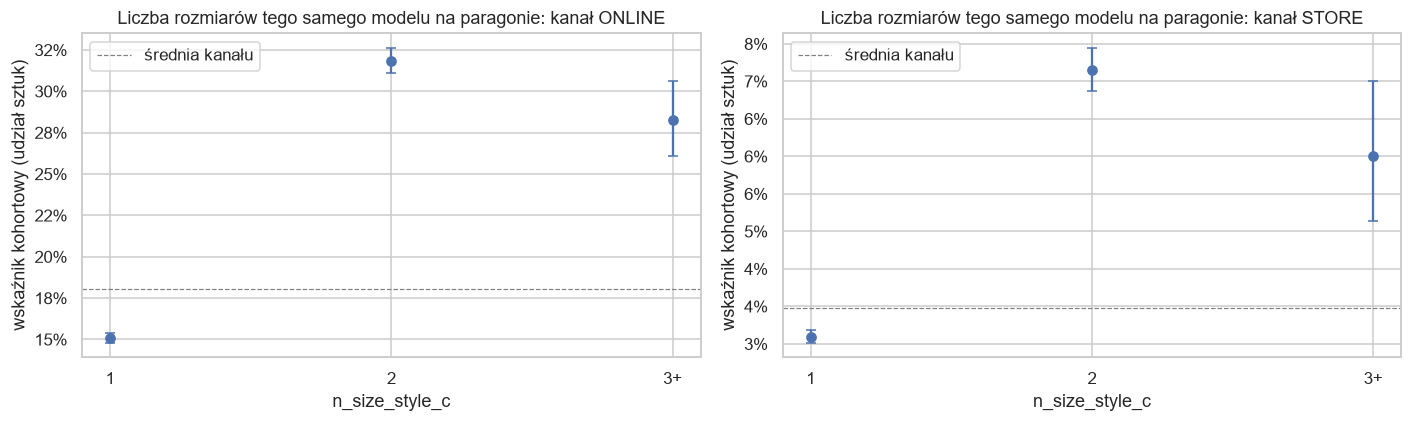

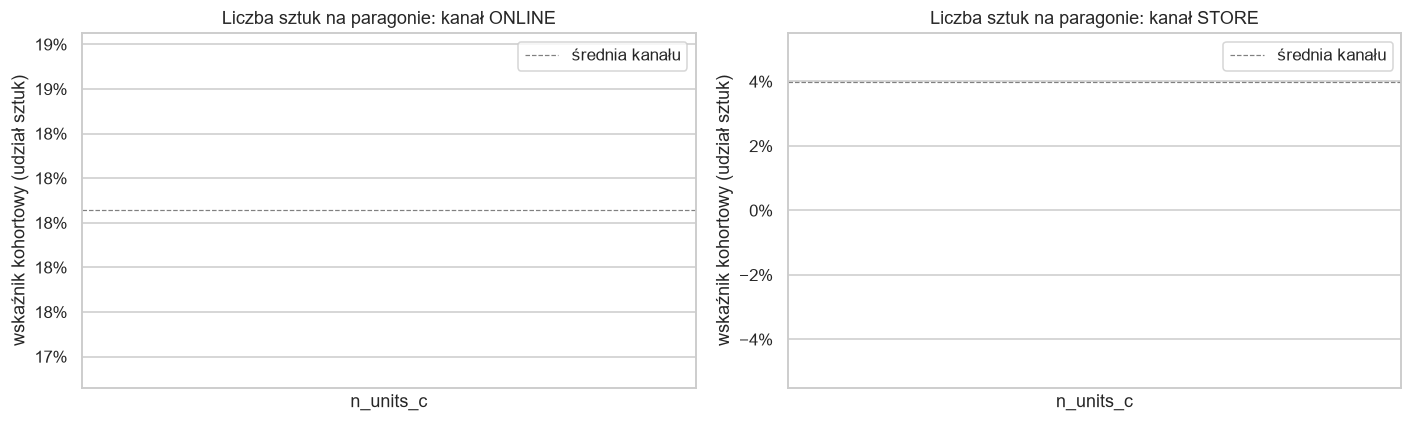

,Channel,grupa,sold,rate,lo,hi
0,ONLINE,1,"54,029",0.1511,0.1481,0.1542
1,ONLINE,2,"14,273",0.3186,0.3110,0.3263
2,ONLINE,3+,"1,534",0.2829,0.2609,0.3060
3,STORE,1,"203,929",0.0360,0.0352,0.0368
4,STORE,2,"30,291",0.0715,0.0687,0.0745
5,STORE,3+,"2,515",0.0600,0.0514,0.0700
0,ONLINE,1.0,"6,570",0.1543,0.1458,0.1633
1,ONLINE,2.0,"14,024",0.2190,0.2122,0.2259
2,ONLINE,3.0,"15,252",0.1875,0.1814,0.1938
3,ONLINE,4.0,"15,168",0.1742,0.1682,0.1803


Udział sztuk (bez akcesoriów), które mają na paragonie >1 rozmiar tego samego modelu, wg kanału:


,udzial
Channel,
ONLINE,0.2263
STORE,0.1386


In [17]:
# Zawartość paragonu: ile rozmiarów tego samego modelu kupiono naraz (kupno "na próbę"), wielkość koszyka.
L["n_size_style_c"] = L.n_size_style.clip(upper=3).astype(str).replace({"3": "3+"})
L["n_units_c"] = L.n_units.clip(upper=6).astype(str).replace({"6": "6+"})
L["n_lines_c"] = L.n_lines.clip(upper=6).astype(str).replace({"6": "6+"})
t_ns = plot_rate(L[L.Size != "ONE"], "n_size_style_c", "Liczba rozmiarów tego samego modelu na paragonie", order=["1", "2", "3+"])
t_nu = plot_rate(L, "n_units_c", "Liczba sztuk na paragonie", order=["1", "2", "3", "4", "5", "6+"])
display(pd.concat([t_ns.rename(columns={"n_size_style_c": "grupa"}), t_nu.rename(columns={"n_units_c": "grupa"})])[["Channel", "grupa", "sold", "rate", "lo", "hi"]].round(4))
print("Udział sztuk (bez akcesoriów), które mają na paragonie >1 rozmiar tego samego modelu, wg kanału:")
display(L[L.Size != "ONE"].assign(multi=lambda d: d.n_size_style > 1).groupby("Channel").apply(lambda d: d.loc[d.multi, "sold_qty"].sum() / d.sold_qty.sum(), include_groups=False).to_frame("udzial"))

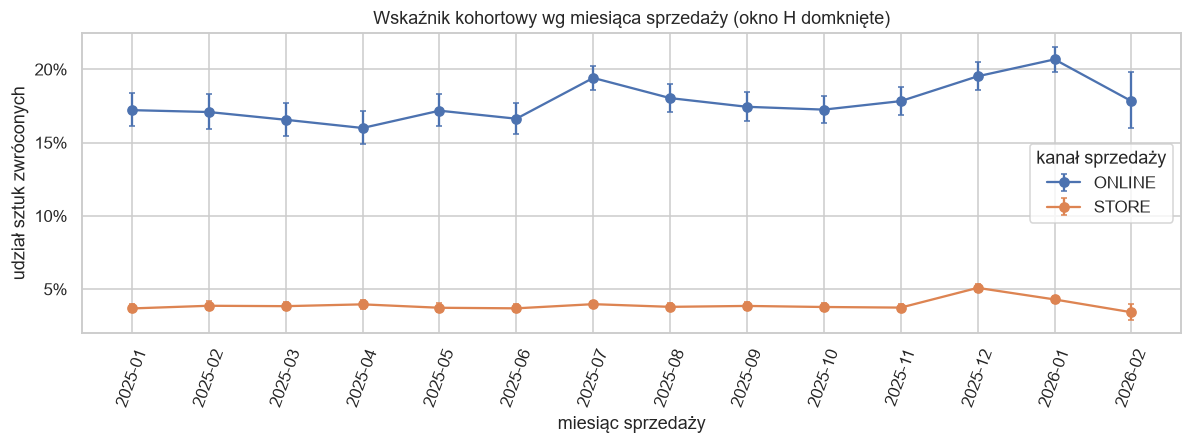

sold           rate       
Channel ONLINE   STORE ONLINE  STORE
Season                              
AW24     4,444  16,920 0.1721 0.0368
AW25    39,531 136,037 0.1862 0.0413
SS25    30,435 103,096 0.1749 0.0386
SS26     1,520   4,326 0.1783 0.0342

DayOfWeek,1,2,3,4,5,6,7
Channel,,,,,,,
ONLINE,0.1780,0.1789,0.1807,0.1771,0.1791,0.1802,0.1891
STORE,0.0379,0.0412,0.0398,0.0391,0.0388,0.0400,0.0482


Stopa rabatu (ważona wartością) wg miesiąca, ONLINE:


Month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02
disc,0,0,0,0,0,0,0.1520,0.0370,0,0,0.0600,0,0.2260,0.0600


In [18]:
# Czas: miesięczny wskaźnik kohortowy z przedziałem oraz kolekcja (sezon w dniu sprzedaży), dzień tygodnia
t_m = rate_table(L, "Month")
fig, ax = plt.subplots(figsize=(11, 4.2))
for ch in ["ONLINE", "STORE"]:
    g = t_m[t_m.Channel == ch]
    ax.errorbar(range(len(g)), g.rate, yerr=[g.rate - g.lo, g.hi - g.rate], fmt="-o", capsize=2, label=ch)
ax.set_xticks(range(len(g))); ax.set_xticklabels(g.Month, rotation=70)
ax.set(title="Wskaźnik kohortowy wg miesiąca sprzedaży (okno H domknięte)", xlabel="miesiąc sprzedaży", ylabel="udział sztuk zwróconych")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0)); ax.legend(title="kanał sprzedaży")
plt.tight_layout(); plt.show()

t_season = rate_table(L, "Season")
display(t_season.pivot(index="Season", columns="Channel", values=["sold", "rate"]).round(4))
t_dow = rate_table(L, "DayOfWeek")
display(t_dow.pivot(index="DayOfWeek", columns="Channel", values="rate").round(4).T)
# średni rabat wg miesiąca: czy wzrost zwrotów online (VII, XII-I) zbiega się z wyprzedażami?
md = L.groupby(["Channel", "Month"]).apply(lambda d: pd.Series({"disc": d.disc_rate.mul(d.sold_qty * d.ListPrice).sum() / (d.sold_qty * d.ListPrice).sum()}), include_groups=False).reset_index()
print("Stopa rabatu (ważona wartością) wg miesiąca, ONLINE:")
display(md[md.Channel == "ONLINE"].set_index("Month").disc.round(3).to_frame().T)

**Co widzę (fakty, tylko okres treningowy, przedziały Wilsona na sztukach, więc lekko za wąskie):**
- **Kanał dominuje.** Online wraca ok. 17-18% sztuk, w sklepach ok. 4%; każdy inny efekt poniżej to różnica *wokół* tych poziomów.
- **Rozmiar:** online XS (23,5%) i XL (24,9%) wracają wyraźnie częściej niż M (16,3%), L (18,2%) i S (18,0%); przedziały XS/XL nie zachodzą na M. W sklepach ten sam kształt, ale znacznie słabszy (XS 4,4%, XL 4,6% vs M 3,8%). To zgodne z H1 (interakcja kanał × rozmiar).
- **Kategoria:** online wyróżniają się **Jeansy (25,8%)** wobec ok. 16% dla pozostałych kategorii i **Akcesoria (9,4%)** poniżej. W sklepach Jeansy też są wyższe (4,8% vs 3,7-3,9%), ale różnica jest o rząd mniejsza.
- **Rabat:** wyższy wskaźnik przy rabacie (online 17,2% bez rabatu vs 22-24% przy rabacie 25-45%; sklepy 3,9% vs 4,4-4,5%). Pozycje przecenione nie są jednak losową próbką asortymentu, więc to korelacja brutto (do rozdzielenia w H5).
- **Cena:** przedział cen (59, 169] PLN wyróżnia się online (23,1%), a niższe i wyższe ceny mają 15-17%. Podejrzewam, że to nie cena jako taka, tylko skład asortymentu w tym przedziale (np. Jeansy). Sprawdzę przez porównanie wewnątrz kategorii.
- **Zawartość paragonu: najsilniejszy sygnał zakupowy.** Gdy na tym samym paragonie jest **ten sam model w dwóch rozmiarach**, wskaźnik wynosi online 31,9% (vs 15,1% przy jednym rozmiarze), w sklepach 7,2% (vs 3,6%), czyli ok. dwukrotnie więcej w obu kanałach. Taki koszyk to ok. 23% sztuk online i 14% w sklepach. Sama liczba sztuk na paragonie działa słabo (online 15% przy 1 szt., 22% przy 2 szt., potem spada do 16%), więc to konkretnie *kupno „na próbę"*, a nie wielkość koszyka.
- **Czas:** online waha się w granicach ok. 16-21% wg miesiąca sprzedaży. Wzrosty w lipcu 2025 i styczniu 2026 zbiegają się z wyprzedażą (średnia stopa rabatu online ok. 15% i 23%), ale **grudzień 2025 (ok. 19,8%) ma rabat zerowy**, więc sam rabat nie tłumaczy sezonowości (możliwe: prezenty świąteczne, ale tego danymi nie sprawdzę). Sezon kolekcji (SS/AW) i dzień tygodnia prawie nie różnicują: online 17,2-18,6% wg sezonu i 17,7-18,9% wg dnia (niedziela najwyżej), sklepy 3,4-4,1% i 3,8-4,8%.

**Czego jeszcze nie wiem:** czy efekt rabatu i ceny przeżyje kontrolę modelu i rozmiaru; czy „dwa rozmiary na paragonie" to efekt samego zachowania, czy współwystępuje z czymś innym (np. XS/XL); które modele odstają od oczekiwań kanałowych. Tym zajmuje się dalszy ciąg eksploracji i hipotezy.

#### Eksploracja: modele odstające od oczekiwań kanałowych (wykres lejkowy)

**Po co:** zleceniodawcę interesują konkretne modele. Surowy ranking modeli po wskaźniku zwrotów wprowadza w błąd, bo (a) kategoria i rozmiar zmieniają oczekiwanie (Jeansy online wracają częściej z natury), (b) małe liczebności dają skrajne wartości przez przypadek. Dlatego porównuję **zwroty obserwowane z oczekiwanymi**, gdzie oczekiwanie liczę z kanału × kategorii × rozmiaru (komórki z okresu treningowego), a rozrzut oceniam na **wykresie lejkowym** (*funnel plot*): oś pozioma to liczba oczekiwanych zwrotów (czyli „ile danych"), pionowa to stosunek obserwowane/oczekiwane, a przedziały 95% i 99,8% zwężają się w miarę przybywania danych. Punkty poza lejkiem to modele, których nie tłumaczy losowość. Jeśli *wszystkie* punkty są w lejku, nie ma czego szukać; jeśli wychodzi ich dużo więcej niż 5%, jest nadmierna dyspersja (różnice większe niż losowe).

Uwaga: ponieważ oczekiwanie liczę na tych samych danych, które oceniam, odchylenia są lekko niedoszacowane. Formalne rozstrzygnięcie (H3) oprę na **replikacji na późniejszych danych**.

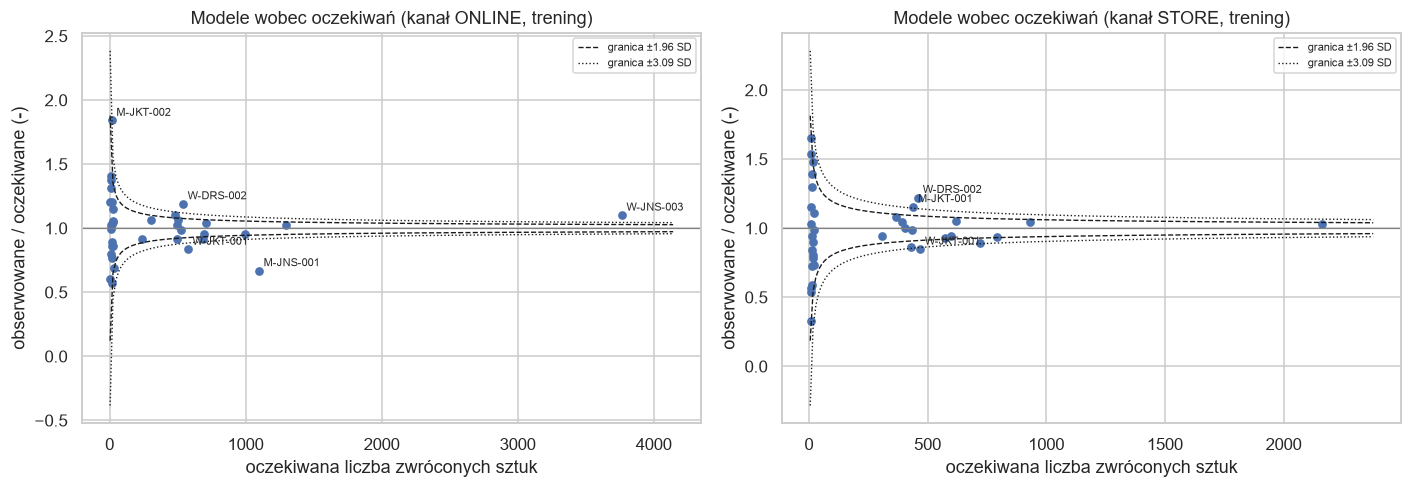

ONLINE: modeli 36; poza ±1,96 SD: 10 (oczekiwane przy samej losowości ok. 1.8); poza ±3,09 SD: 5; Pearson chi2/liczba_modeli = 9.00 (przy samej losowości ok. 1,0)
STORE: modeli 36; poza ±1,96 SD: 8 (oczekiwane przy samej losowości ok. 1.8); poza ±3,09 SD: 3; Pearson chi2/liczba_modeli = 3.13 (przy samej losowości ok. 1,0)


,Channel,StyleCode,StyleName,Category,sold,obs,exp,oe,z
9,ONLINE,M-JNS-001,Jeansy regular,Jeansy,"4,243",734,"1,098.8300",0.6700,-12.8600
28,ONLINE,W-JNS-003,Jeansy skinny,Jeansy,"14,588","4,148","3,766.2600",1.1000,7.2600
56,STORE,W-DRS-002,Sukienka koszulowa,Sukienki,"11,710",563,460.7100,1.2200,4.8600
20,ONLINE,W-DRS-002,Sukienka koszulowa,Sukienki,"3,403",643,540.3500,1.1900,4.8300
25,ONLINE,W-JKT-001,Kurtka pikowana damska,Kurtki,"3,510",481,576.4600,0.8300,-4.3600
7,ONLINE,M-JKT-002,Kurtka przejściowa,Kurtki,100,30,16.3000,1.8400,3.7200
61,STORE,W-JKT-001,Kurtka pikowana damska,Kurtki,"12,152",398,469.4000,0.8500,-3.3600
42,STORE,M-JKT-001,Kurtka miejska,Kurtki,"11,408",509,440.5400,1.1600,3.3300
57,STORE,W-DRS-003,Sukienka mini,Sukienki,"10,888",369,428.7700,0.8600,-2.9500
45,STORE,M-JNS-001,Jeansy regular,Jeansy,"14,931",644,719.2700,0.9000,-2.8800


In [19]:
# Oczekiwana liczba zwrotów modelu z komórek kanał x kategoria x rozmiar (z treningu), potem porównanie z obserwowaną.
cell = L.groupby(["Channel", "Category", "Size"], observed=True).apply(lambda d: d.ret_qty_h.sum() / d.sold_qty.sum(), include_groups=False).rename("p_cell").reset_index()
Lm = L.merge(cell, on=["Channel", "Category", "Size"])
Lm["exp"] = Lm.sold_qty * Lm.p_cell
Lm["var"] = Lm.sold_qty * Lm.p_cell * (1 - Lm.p_cell)
sm = Lm.groupby(["Channel", "StyleCode"]).agg(sold=("sold_qty", "sum"), obs=("ret_qty_h", "sum"), exp=("exp", "sum"), var=("var", "sum")).reset_index()
sm["oe"] = sm.obs / sm.exp
sm["z"] = (sm.obs - sm.exp) / np.sqrt(sm["var"])
sm = sm.merge(dim_product.drop_duplicates("StyleCode")[["StyleCode", "StyleName", "Category"]], on="StyleCode")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, ch in zip(axes, ["ONLINE", "STORE"]):
    g = sm[sm.Channel == ch]
    xs = np.linspace(g.exp.min() * 0.8, g.exp.max() * 1.1, 200)
    # w przybliżeniu normalnym: SD stosunku O/E = sqrt(var)/exp; przyjmuję średni var/exp (bliski p(1-p))
    k = (g["var"].sum() / g.exp.sum())
    for zz, ls in [(1.96, "--"), (3.09, ":")]:
        ax.plot(xs, 1 + zz * np.sqrt(k / xs), "k", ls=ls, lw=0.9, label=f"granica ±{zz} SD")
        ax.plot(xs, 1 - zz * np.sqrt(k / xs), "k", ls=ls, lw=0.9)
    ax.scatter(g.exp, g.oe, s=22)
    for _, r in g[g.z.abs() > 3.09].iterrows():
        ax.annotate(r.StyleCode, (r.exp, r.oe), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.axhline(1, c="grey", lw=0.8)
    ax.set(title=f"Modele wobec oczekiwań (kanał {ch}, trening)", xlabel="oczekiwana liczba zwróconych sztuk", ylabel="obserwowane / oczekiwane (-)")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for ch in ["ONLINE", "STORE"]:
    g = sm[sm.Channel == ch]
    chi2 = (g.z ** 2).sum()
    print(f"{ch}: modeli {len(g)}; poza ±1,96 SD: {(g.z.abs() > 1.96).sum()} (oczekiwane przy samej losowości ok. {0.05 * len(g):.1f}); poza ±3,09 SD: {(g.z.abs() > 3.09).sum()}; "
          f"Pearson chi2/liczba_modeli = {chi2 / len(g):.2f} (przy samej losowości ok. 1,0)")
display(sm.reindex(sm.z.abs().sort_values(ascending=False).index).head(10)[["Channel", "StyleCode", "StyleName", "Category", "sold", "obs", "exp", "oe", "z"]].round(2))

**Co widzę (fakty):**
- Online 10 z 36 modeli leży poza granicą ±1,96 SD (przy samej losowości spodziewałbym się ok. 2), a 5 poza ±3,09 SD. W sklepach odpowiednio 8 i 3. Statystyka chi2 na model to 9,0 online i 3,1 w sklepach (przy samej losowości ok. 1,0). Czyli rozrzut modeli jest **wyraźnie większy niż losowy**, mocniej online.
- Największe odchylenia: online `M-JNS-001` (Jeansy regular) **mniej** zwrotów, niż wynika z kategorii (O/E 0,67, z = -12,9), `W-JNS-003` (Jeansy skinny) **więcej** (1,10, z = +7,3); `W-DRS-002` (Sukienka koszulowa) więcej w **obu** kanałach (1,19 online, 1,22 w sklepach, z ok. +4,8 w każdym); `W-JKT-001` (Kurtka pikowana damska) mniej w obu (0,83 i 0,85). `M-JKT-002` online ma tylko 100 sprzedanych sztuk, więc jego O/E 1,84 to mała próba.

**Interpretacja (hipotezy, nie wnioski):**
- Dwa modele (`W-DRS-002`, `W-JKT-001`) odstają **w tę samą stronę w obu kanałach**. Kanały mają innych klientów i inne mechanizmy zwrotów, więc taka zgodność wskazuje raczej na cechę **produktu** (krój, jakość, opis) niż na przypadek. To mocniejszy sygnał niż pojedyncze odchylenie w jednym kanale.
- Odchylenia jeansów wymagają ostrożności: oczekiwanie liczę z kategorii Jeansy, a ta ma wysoki wskaźnik głównie dlatego, że `W-JNS-003` ma dużą sprzedaż online i wysoki wskaźnik. `M-JNS-001` wygląda więc na „niski" głównie względem tej średniej. Co jest „normą" dla Jeansów, zależy od tego, czy uznamy kategorię za jednorodną; rozkładam to poniżej na modele.
- Część nadmiarowej dyspersji może wynikać z zależności sztuk w jednym koszyku (kilka rozmiarów tego samego modelu), której przybliżenie dwumianowe nie uwzględnia. Dlatego wniosek o H3 oprę na **replikacji na późniejszych danych**, a nie na samym lejku.

#### Eksploracja: rabat i cena po porównaniu „tego samego z tym samym"

**Po co:** brutto rabat wygląda groźnie, ale przecenia się inne modele i rozmiary niż się sprzedaje po pełnej cenie. Porównuję więc wskaźnik pozycji przecenionych z pozycjami **tego samego modelu i rozmiaru w tym samym kanale** sprzedanymi bez rabatu (tzw. stratyfikacja: porównanie wewnątrz warstw). Wynik to stosunek obserwowanych zwrotów do oczekiwanych przy wskaźniku warstwy bez rabatu.

In [20]:
base = L[L.disc_rate <= 0.0001].groupby(["Channel", "StyleCode", "Size"]).apply(lambda d: d.ret_qty_h.sum() / d.sold_qty.sum(), include_groups=False).rename("p0").reset_index()
Ld = L.merge(base, on=["Channel", "StyleCode", "Size"], how="left").dropna(subset=["p0"])
Ld["exp0"] = Ld.sold_qty * Ld.p0
rows = []
for ch in ["ONLINE", "STORE"]:
    for lab, lo, hi in [("0%", -1, 0.0001), ("(0,25%]", 0.0001, 0.25), ("(25,35%]", 0.25, 0.35), ("(35,60%]", 0.35, 1.0)]:
        d = Ld[(Ld.Channel == ch) & (Ld.disc_rate > lo) & (Ld.disc_rate <= hi)]
        rows.append([ch, lab, int(d.sold_qty.sum()), d.ret_qty_h.sum() / d.sold_qty.sum(), d.exp0.sum() / d.sold_qty.sum(), d.ret_qty_h.sum() / d.exp0.sum()])
disc_strat = pd.DataFrame(rows, columns=["kanał", "rabat", "sztuki", "wsk_obs", "wsk_oczek_bez_rabatu_tego_samego_modelu_rozmiaru", "O/E"])
display(disc_strat.round(4))
# Ile modeli ma w ogóle sprzedaż zarówno z rabatem, jak i bez (inaczej porównanie wewnątrz warstwy nie istnieje)
print("Udział sztuk ze stawką rabatu > 0 w modelu x kanał: min / mediana / max po modelach")
print(Lm.groupby(["Channel", "StyleCode"]).apply(lambda d: d.loc[d.disc_rate > 0.0001, "sold_qty"].sum() / d.sold_qty.sum(), include_groups=False).groupby("Channel").describe()[["min", "50%", "max"]].round(3))

,kanał,rabat,sztuki,wsk_obs,wsk_oczek_bez_rabatu_tego_samego_modelu_rozmiaru,O/E
0,ONLINE,0%,63415,0.1717,0.1717,1
1,ONLINE,"(0,25%]",2028,0.2017,0.1809,1.1147
2,ONLINE,"(25,35%]",4862,0.2396,0.2251,1.0643
3,ONLINE,"(35,60%]",5625,0.2236,0.2211,1.0115
4,STORE,0%,225103,0.0393,0.0393,1
5,STORE,"(0,25%]",6999,0.0386,0.0399,0.9658
6,STORE,"(25,35%]",11740,0.0444,0.0445,0.9970
7,STORE,"(35,60%]",16537,0.0447,0.0429,1.0423


Udział sztuk ze stawką rabatu > 0 w modelu x kanał: min / mediana / max po modelach
           min    50%    max
Channel                     
ONLINE       0 0.0590 0.4320
STORE   0.0140 0.0360 0.3570


**Co widzę (fakty):** po porównaniu z tym samym modelem i rozmiarem sprzedanym bez rabatu stosunek obserwowanych do oczekiwanych zwrotów online wynosi 1,11 (rabat do 25%), 1,06 (25-35%) i 1,01 (powyżej 35%), a w sklepach 0,97, 1,00 i 1,04. Surowa różnica brutto (online 17,2% vs 22-24%, sklepy 3,9% vs 4,4-4,5%) w dużej części **znika**: pozycje przeceniane to inne modele i rozmiary niż te sprzedawane po pełnej cenie. Przecenie podlega średnio tylko 6% sztuk online i 4% w sklepach (rozrzut po modelach od 0 do 43% online).

**Interpretacja:** wstępnie przemawia to za tym, że rabat sam w sobie nie zwiększa zwrotów, a wysoki wskaźnik przecenionych pozycji to efekt składu (mix). To jeszcze nie test: przedział dla najmniejszej grupy (online, rabat do 25%, 2 028 szt.) jest szeroki, a stratyfikacja po modelu i rozmiarze nie kontroluje wszystkiego (np. kto kupuje na wyprzedaży). Formalnie sprawdzam to w H5 na danych walidacyjnych.

#### Eksploracja: powody zwrotów (opisowo)

**Po co:** powód zwrotu (`ReturnReason`) jest informacją **po zdarzeniu**, więc służy tylko analizie opisowej (nie jest cechą modelu). Patrzę, czy struktura powodów zgadza się z intuicją (rozmiar online → `WRONG_SIZE`) i jak zmienia się wewnątrz kanałów. Dotyczy zwrotów z okresu treningowego sprzedaży.

In [21]:
reasons = q("""
SELECT k.Channel, p.Size, p.Category, p.StyleCode, k.SaleDate, COALESCE(r.ReturnReason, '(brak)') AS powod, r.Quantity
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) JOIN dim_product p ON p.ProductKey = r.ProductKey
WHERE k.SaleDate < DATE '2026-02-10' AND DATE_DIFF('day', k.SaleDate, r.ReturnDate) <= 50
""")
rs_ch = reasons.groupby(["Channel", "powod"]).Quantity.sum().unstack()
display((rs_ch.div(rs_ch.sum(axis=1), axis=0)).round(3))
rs_sz = reasons[reasons.Size != "ONE"].groupby(["Channel", "Size", "powod"]).Quantity.sum().unstack()
display((rs_sz.div(rs_sz.sum(axis=1), axis=0)).round(3))
rs_cat = reasons.groupby(["Channel", "Category", "powod"]).Quantity.sum().unstack()
display((rs_cat.div(rs_cat.sum(axis=1), axis=0)).round(3))

powod,(brak),CHANGED_MIND,DAMAGED,OTHER,WRONG_SIZE
Channel,,,,,
ONLINE,0.0480,0.2480,0.0880,0.0590,0.5570
STORE,0.0500,0.3400,0.1520,0.0780,0.3800


powod         (brak)  CHANGED_MIND  DAMAGED  OTHER  WRONG_SIZE
Channel Size                                                  
ONLINE  L     0.0490        0.2430   0.0820 0.0590      0.5660
        M     0.0510        0.2370   0.0870 0.0500      0.5760
        S     0.0490        0.2410   0.0910 0.0590      0.5610
        XL    0.0470        0.2270   0.0730 0.0480      0.6050
        XS    0.0490        0.2040   0.0780 0.0570      0.6120
STORE   L     0.0450        0.3280   0.1550 0.0650      0.4070
        M     0.0510        0.3400   0.1540 0.0790      0.3750
        S     0.0470        0.3290   0.1380 0.0790      0.4080
        XL    0.0550        0.3120   0.1180 0.0720      0.4430
        XS    0.0670        0.2580   0.1530 0.0800      0.4420

powod              (brak)  CHANGED_MIND  DAMAGED  OTHER  WRONG_SIZE
Channel Category                                                   
ONLINE  Akcesoria  0.0300        0.5660   0.1930 0.1620      0.0490
        Jeansy     0.0480        0.1830   0.0710 0.0410      0.6570
        Koszule    0.0600        0.2350   0.0890 0.0510      0.5660
        Kurtki     0.0490        0.2630   0.0920 0.0620      0.5350
        Sukienki   0.0450        0.2710   0.0970 0.0640      0.5230
        Swetry     0.0520        0.2740   0.0850 0.0600      0.5290
        T-shirty   0.0500        0.2660   0.0890 0.0650      0.5300
STORE   Akcesoria  0.0450        0.5550   0.2420 0.1270      0.0310
        Jeansy     0.0570        0.1980   0.0960 0.0470      0.6020
        Koszule    0.0510        0.2910   0.1910 0.0960      0.3720
        Kurtki     0.0440        0.3850   0.1700 0.0870      0.3140
        Sukienki   0.0450        0.3790   0.1580 0.0850      0.3340
        Swetry     0.0490        0.3900   0.1750 0.0840      0.3020
        T-shirty   0.0500        0.3870   0.1630 0.0840      0.3160

**Co widzę (fakty):**
- Online dominuje `WRONG_SIZE` (55,7% powodów), potem `CHANGED_MIND` (24,8%), `DAMAGED` (8,8%), `OTHER` (5,9%), brak (4,8%). W sklepach `WRONG_SIZE` 38,0%, `CHANGED_MIND` 34,0%, `DAMAGED` 15,2%.
- Skrajne rozmiary online mają wyższy udział `WRONG_SIZE` (XS 61,2%, XL 60,5% vs M 57,6%): dodatkowe zwroty XS/XL to głównie „zły rozmiar".
- Akcesoria (bez rozmiaru) to głównie `CHANGED_MIND` (57%) i `DAMAGED` (19-24%), `WRONG_SIZE` poniżej 5%. To wyjaśnia niski wskaźnik online akcesoriów.
- **Jeansy mają w sklepach 60% `WRONG_SIZE`** (online 66%), podczas gdy inne kategorie w sklepach 30-37%. To spójne z podwyższonym wskaźnikiem jeansów także w sklepach (4,8% vs 3,7-3,9%).

**Interpretacja:** udziały to struktura *w obrębie zwrotów*, nie wskaźniki na sprzedaż; dopiero iloczyn wskaźnika i udziału mówi o skali problemu. Jeansy jawią się jako **problem rozmiarowy niezależny od kanału** (krój/tabela rozmiarów), a nie tylko skutek „nie można przymierzyć". To hipoteza do dalszej weryfikacji (modele jeansów w następnym kroku), nie zamknięty wniosek.

**Uwaga o `DAMAGED`:** udział uszkodzeń jest wyższy w sklepach (15% vs 9%), ale w przeliczeniu na sprzedaż online daje ok. 17,7% × 8,8% ≈ 1,6 szt. na 100 sprzedanych, a sklepy 3,9% × 15,2% ≈ 0,6 (dokładnie policzę w następnym kroku).

#### Eksploracja: jeansy rozłożone na modele oraz skala powodów na 100 sprzedanych sztuk

**Po co:** (1) rozstrzygnąć, czy „Jeansy" to jednorodna kategoria, czy wskaźnik zależy od konkretnych modeli (od tego zależy, jakie oczekiwanie jest uczciwe dla modelu); (2) zamienić udziały powodów na skalę problemu: ile zwrotów danego powodu przypada na 100 sprzedanych sztuk (udział w zwrotach mówi, *z czego* składają się zwroty, ale nie *ile* ich jest).

In [22]:
price_of = dim_product.drop_duplicates("StyleCode")[["StyleCode", "ListPrice"]]
jns = sm[sm.Category == "Jeansy"].merge(price_of, on="StyleCode")
jns["wsk"] = jns.obs / jns.sold
print("Jeansy: wskaźnik kohortowy wg modelu (trening); O/E względem komórek kanał x kategoria x rozmiar")
display(jns[["Channel", "StyleCode", "StyleName", "ListPrice", "sold", "wsk", "oe"]].round(3))
print("Rozrzut wskaźnika między modelami w obrębie kategorii (ONLINE): min / max po modelach")
cat_rng = sm[sm.Channel == "ONLINE"].assign(wsk=lambda d: d.obs / d.sold).groupby("Category").wsk.agg(["count", "min", "max"]).round(3)
display(cat_rng)

sold_ch = L.groupby("Channel").sold_qty.sum()
per100 = reasons.groupby(["Channel", "powod"]).Quantity.sum().unstack().div(sold_ch, axis=0) * 100
print("Zwroty na 100 sprzedanych sztuk wg powodu i kanału (trening):")
display(per100.round(2))
sold_sz = L[L.Size != "ONE"].groupby(["Channel", "Size"]).sold_qty.sum()
r_sz = reasons[reasons.Size != "ONE"].groupby(["Channel", "Size", "powod"]).Quantity.sum().unstack().div(sold_sz, axis=0) * 100
print("Zwroty na 100 sprzedanych sztuk wg powodu i rozmiaru:")
display(r_sz.round(2))

Jeansy: wskaźnik kohortowy wg modelu (trening); O/E względem komórek kanał x kategoria x rozmiar


,Channel,StyleCode,StyleName,ListPrice,sold,wsk,oe
0,ONLINE,M-JNS-001,Jeansy regular,189,"4,243",0.1730,0.6680
1,ONLINE,M-JNS-002,Jeansy slim,109,115,0.1830,0.6890
2,ONLINE,W-JNS-003,Jeansy skinny,169,"14,588",0.2840,1.1010
3,ONLINE,W-JNS-004,Jeansy mom fit,119,65,0.1540,0.5740
4,STORE,M-JNS-001,Jeansy regular,189,"14,931",0.0430,0.8950
5,STORE,M-JNS-002,Jeansy slim,109,462,0.0480,0.9890
6,STORE,W-JNS-003,Jeansy skinny,169,"44,869",0.0500,1.0330
7,STORE,W-JNS-004,Jeansy mom fit,119,200,0.0750,1.5400


Rozrzut wskaźnika między modelami w obrębie kategorii (ONLINE): min / max po modelach


,count,min,max
Category,,,
Akcesoria,6,0.0570,0.1240
Jeansy,4,0.1540,0.2840
Koszule,4,0.1410,0.2150
Kurtki,6,0.1370,0.3000
Sukienki,6,0.1350,0.1890
Swetry,5,0.1230,0.2330
T-shirty,5,0.1550,0.2000


Zwroty na 100 sprzedanych sztuk wg powodu i kanału (trening):


powod,(brak),CHANGED_MIND,DAMAGED,OTHER,WRONG_SIZE
Channel,,,,,
ONLINE,0.8700,4.4900,1.5900,1.0700,10.0600
STORE,0.2000,1.3500,0.6100,0.3100,1.5100


Zwroty na 100 sprzedanych sztuk wg powodu i rozmiaru:


powod         (brak)  CHANGED_MIND  DAMAGED  OTHER  WRONG_SIZE
Channel Size                                                  
ONLINE  L     0.8900        4.4300   1.5000 1.0800     10.3200
        M     0.8300        3.8600   1.4200 0.8100      9.4100
        S     0.8700        4.3200   1.6300 1.0600     10.0700
        XL    1.1700        5.6500   1.8100 1.1900     15.0400
        XS    1.1400        4.8000   1.8400 1.3400     14.4000
STORE   L     0.1800        1.3300   0.6300 0.2600      1.6600
        M     0.2000        1.3000   0.5900 0.3000      1.4400
        S     0.1900        1.3300   0.5600 0.3200      1.6500
        XL    0.2500        1.4400   0.5400 0.3300      2.0400
        XS    0.3000        1.1300   0.6700 0.3500      1.9400

### Faza 4: hipotezy i plan walidacji (zapisane PRZED budową modeli i testami formalnymi)

Eksploracja (Faza 3) pokazała kilka wzorców. Żeby formalne testy nie były „sprawdzeniem tego, co już widziałem na tych samych danych", stosuję **podział ról danych**:

| Dane | Okres sprzedaży | Rola |
| --- | --- | --- |
| trening | do 2026-02-09 | eksploracja, dopasowanie modeli, oczekiwane wartości dla modeli |
| strefa ochronna | 2026-02-10 … 2026-03-31 | niewykorzystywana do oceny; etykiety sprzedaży z tego okresu zamknęły się dopiero w kwietniu (okno H = 50 dni) |
| walidacja | 2026-04-01 … 2026-05-31 | **testy potwierdzające hipotez** oraz wybór modeli i hiperparametrów |
| test | 2026-06-01 … 2026-08-01 | jedna końcowa ocena wybranych modeli (nie służy do strojenia ani do testów hipotez) |
| ocenzurowane | od 2026-08-02 | okno H niezamknięte, wykluczone z uczenia i oceny |

Wszystkie hipotezy poniżej są **dwustronne, poziom istotności 5%**, a przedziały to 95%. Testy liczę na poziomie klucza (paragon × produkt) ważonego sztukami, z błędami standardowymi **klastrowanymi po paragonie** (sztuki z jednego paragonu nie są niezależne). Pokażę wszystkie wykonane testy (także te, które nie wyszły). Liczba hipotez potwierdzających jest mała (6), więc nie stosuję poprawki na wielokrotne testowanie między hipotezami, ale w H4 (36 modeli) kontroluję odsetek fałszywych odkryć (FDR, procedura Benjaminiego-Hochberga).

| ID | Hipoteza (kierunek) | Miara | Dane do testu | Próg decyzji (ustalony teraz) |
| --- | --- | --- | --- | --- |
| H1 | Online skrajne rozmiary (XS, XL) wracają częściej niż M, w sklepach różnica jest słabsza (interakcja kanał × rozmiar) | iloraz szans (OR) XS/M i XL/M w każdym kanale oraz iloraz ilorazów (sklep/online), regresja logistyczna z kontrolą kategorii | walidacja (bez akcesoriów) | **Potwierdzona**, gdy online OR(XS/M) i OR(XL/M) mają dolną granicę przedziału > 1 i wartość > 1,3, a oba ilorazy ilorazów (sklep/online) < 1. **Częściowo**, gdy spełniony jest tylko pierwszy warunek. Inaczej odrzucona. |
| H2 | Cechy znane w chwili sprzedaży (cena, rabat, kalendarz, zawartość paragonu) niosą informację o ryzyku **ponad** kanał, kategorię i rozmiar | przyrost ROC-AUC (w obrębie kanału) modelu z tymi cechami względem modelu bez nich, regresja logistyczna | walidacja, powtórzone na teście na końcu | **Potwierdzona**, gdy w danym kanale przyrost ROC-AUC ≥ 0,01 i dolna granica przedziału bootstrap (klastry = paragony) > 0. |
| H3 | Modele (model × kanał) odbiegają od oczekiwań z kanału, kategorii i rozmiaru bardziej, niż wynika z losowości | replikacja: korelacja log(O/E) modelu policzonego na treningu z log(O/E) na walidacji i teście łącznie (ważona liczebnością); dodatkowo statystyka chi2 jak w lejku | trening → walidacja + test (nowe paragony) | **Potwierdzona**, gdy korelacja ≥ 0,4 i dolna granica przedziału bootstrap (po modelach) > 0. Losowe odchylenia nie powtarzają się w nowych danych, więc przy samej losowości korelacja ≈ 0. |
| H4 | Struktura powodów zwrotu niektórych modeli zmienia się w czasie (wzrost udziału `DAMAGED`) | zmiana udziału `DAMAGED` wśród zwrotów z podanym powodem: sprzedaż od 2026-02-10 do 2026-08-01 vs wcześniejsza; test dwóch proporcji (kanały razem), 36 modeli, FDR 5% | cały okres z domkniętym oknem H (to pytanie o monitoring, nie o predykcję; nie wpływa na modele) | **Potwierdzona**, gdy co najmniej jeden model ma wzrost ≥ 5 pp i p skorygowane (FDR) < 0,05. |
| H5 | Rabat zwiększa ryzyko zwrotu | OR rabatu (stopa rabatu > 0 vs 0): surowy (kanał) oraz po kontroli modelu, rozmiaru i kalendarza (miesiąc) | walidacja | **Rabat zwiększa ryzyko** (efekt przyczynowy w sensie „po kontroli"), gdy skorygowany OR ma dolną granicę > 1,05. **Efekt składu**, gdy surowy OR > 1,2, a skorygowany przedział zawiera 1. Inaczej niejednoznaczne. |
| H6 (dodana po eksploracji) | Kupno **tego samego modelu w ≥ 2 rozmiarach na jednym paragonie** („na próbę") zwiększa ryzyko zwrotu | OR zmiennej `multi_size` po kontroli modelu, rozmiaru i rabatu, osobno w kanałach | walidacja | **Potwierdzona**, gdy w obu kanałach dolna granica przedziału OR > 1,5. |

**Co to znaczy „po kontroli":** do regresji dodaję zmienne, które mogłyby tłumaczyć związek (model, rozmiar, miesiąc), tak aby porównywać podobne z podobnymi. To jedyne, co mogę zrobić na danych obserwacyjnych; nie jest to dowód przyczynowości, bo nie widzę klienta ani eksperymentu.

**Plan walidacji modeli (decyzja B: ryzyko zwrotu pozycji w chwili zakupu):**
- Etykieta: sztuki zwrócone w ciągu H = 50 dni od sprzedaży; jednostką jest **sztuka** (klucz rozwijam na wiersze „zwrócone" i „niezwrócone" z wagami, żeby zwroty częściowe nie wymagały arbitralnej reguły).
- Cały paragon zawsze w jednym zbiorze, bo podział jest wg daty sprzedaży, a paragon ma jedną datę. Strefa ochronna z tabeli powyżej.
- Cechy (wszystkie dostępne w chwili sprzedaży): kanał; model, kategoria, rozmiar; cena katalogowa i stopa rabatu; miesiąc, dzień tygodnia, sezon (SS/AW) i dzień sezonu; zawartość paragonu (liczba pozycji, sztuk, kategorii, wartość koszyka, liczba rozmiarów i SKU tego samego modelu, liczba sztuk w kluczu); **historia modelu as-of** (wskaźnik zwrotów modelu liczony wyłącznie z kohort sprzedanych co najmniej H + 1 dni wcześniej, czyli z domkniętymi oknami). **Nie używam:** `ReturnReason`, kanału przyjęcia zwrotu, wskaźników z całego okresu.
- Metryki (osobno dla każdego kanału; źródło: definicje standardowe, wskaźnik zwrotów wg odstępstwa kohortowego opisanego wyżej): ROC-AUC (prawdopodobieństwo, że losowa zwrócona sztuka ma wyższy wynik niż losowa niezwrócona; 0,5 = brak informacji), PR-AUC (pole pod krzywą precyzja-czułość, tu porównywane z udziałem zwrotów w kanale, czyli wartością „losową"), Brier score (średni kwadrat błędu prawdopodobieństwa, mniejszy = lepiej; liczę też wynik względny wobec B0), kalibracja (czy przewidziane 20% oznacza faktycznie 20%), lift w górnych 10% (ile razy gęściej niż średnio zwracają się sztuki z najwyższych 10% wyniku).
- Niepewność: bootstrap klastrowy po paragonach (losowanie całych paragonów ze zwracaniem), 100 powtórzeń; różnice modeli liczone na tych samych próbach bootstrapowych.
- Porównanie: B0 (jeden wskaźnik na kanał), B1 (kanał × kategoria) i B1b (kanał × kategoria × rozmiar) jako baseline'y, potem M1 (regresja logistyczna), M2 (model gradientowy). Złożony model musi mieć zmierzoną przewagę nad najlepszym baseline'em.
- Decyzja A (oferta) i C (koszt): osobne metody (M3 z kurczeniem; prognoza zagregowana), opisane przy ich użyciu.

## Transform

### Cechy dostępne w chwili sprzedaży i historia modelu as-of

**Po co:** zbudować jedną tabelę cech dla modeli. Szczególną uwagę poświęcam **historii modelu**: wskaźnik zwrotów modelu jest prawdopodobnie użyteczną cechą, ale policzony z całego okresu byłby przeciekiem (zawierałby zwroty z przyszłości względem sprzedaży). Dlatego dla sprzedaży w dniu *d* używam wyłącznie kohort sprzedanych do dnia *d - (H + 1)*, których okno zwrotu już się zamknęło. Wskaźnik jest ściągany (kurczony) w stronę średniej kanału, tym silniej, im mniej danych historycznych (100 „wirtualnych" sztuk prior).

In [23]:
d = dk.copy()
d["month"] = d.SaleDate.dt.month
d["season_type"] = d.Season.str[:2]
d["is_online"] = (d.Channel == "ONLINE").astype(int)
# Dzień sezonu: SS startuje 1 lutego, AW 1 sierpnia (styczeń należy do AW z poprzedniego roku).
yr, mo = d.SaleDate.dt.year, d.SaleDate.dt.month
start = pd.to_datetime({"year": np.where(mo == 1, yr - 1, yr), "month": np.where((mo >= 2) & (mo <= 7), 2, 8), "day": 1})
d["season_day"] = (d.SaleDate - start).dt.days
d["multi_size"] = (d.n_size_style > 1).astype(int)
d["disc_any"] = (d.disc_rate > 0.0001).astype(int)
d["log_price"] = np.log(d.ListPrice)
d["log_basket"] = np.log(d.basket_gross)

LAG = H + 1  # informacja o sprzedaży z dnia s jest kompletna (okno H zamknięte) od dnia s + H + 1

def asof_hist(df, group_cols, prior_col=None, kappa=100.0, name="hist"):
    """Skurczony wskaźnik zwrotów grupy z kohort o zamkniętym oknie H (tylko przeszłość względem daty sprzedaży)."""
    daily = df.groupby(group_cols + ["SaleDate"], observed=True)[["sold_qty", "ret_qty_h"]].sum().reset_index()
    daily["avail"] = daily.SaleDate + pd.Timedelta(days=LAG)
    daily = daily.sort_values(group_cols + ["avail"])
    daily[["cum_sold", "cum_ret"]] = daily.groupby(group_cols, observed=True)[["sold_qty", "ret_qty_h"]].cumsum()
    left = df[group_cols + ["SaleDate"]].reset_index().sort_values("SaleDate")
    right = daily[group_cols + ["avail", "cum_sold", "cum_ret"]].sort_values("avail")
    left["SaleDate"] = left.SaleDate.astype("datetime64[ns]")  # merge_asof wymaga identycznej rozdzielczości czasu
    right["avail"] = right.avail.astype("datetime64[ns]")
    m = pd.merge_asof(left, right, left_on="SaleDate", right_on="avail", by=group_cols, direction="backward").set_index("index").sort_index()
    cs, cr = m.cum_sold.fillna(0), m.cum_ret.fillna(0)
    prior = df[prior_col] if prior_col else (cr.sum() / max(cs.sum(), 1))
    return (cr + kappa * prior) / (cs + kappa), cs

# prior: średni wskaźnik kanału z domkniętych kohort do dnia sprzedaży (kappa=0 daje goły wskaźnik; NaN, gdy brak historii)
d["hist_ch"], d["hist_ch_n"] = asof_hist(d, ["Channel"], kappa=0.0)
d.loc[d.hist_ch_n == 0, "hist_ch"] = np.nan
d["hist_style"], d["hist_style_n"] = asof_hist(d, ["Channel", "StyleCode"], prior_col="hist_ch", kappa=100.0)
d["hist_cell"], d["hist_cell_n"] = asof_hist(d, ["Channel", "StyleCode", "Size"], prior_col="hist_style", kappa=100.0)
d["hist_style_n"] = d.hist_style_n.astype(float)

# Kontrola przecieku: historia dla sprzedaży z danego dnia nie może zawierać kohort młodszych niż LAG dni (test na jednym modelu).
chk = d[(d.Channel == "ONLINE") & (d.StyleCode == "W-JNS-003")].sort_values("SaleDate")
probe_date = pd.Timestamp("2026-03-15")
manual = chk[chk.SaleDate <= probe_date - pd.Timedelta(days=LAG)]
print("Kontrola as-of dla W-JNS-003 online, dzień sprzedaży", probe_date.date(), ": sztuki w historii (ręcznie) =", int(manual.sold_qty.sum()),
      "| w kolumnie hist_style_n =", int(chk[chk.SaleDate == probe_date].hist_style_n.iloc[0]))
print("Wiersze bez historii (początek okresu, pierwsze", LAG, "dni):", int((d.hist_ch_n == 0).sum()), "kluczy")

FEATS = {
    "kanał": ["is_online"],
    "produkt": ["Category", "Size"],
    "model": ["StyleCode"],
    "cena i rabat": ["log_price", "disc_rate"],
    "kalendarz": ["month", "DayOfWeek", "season_type", "season_day"],
    "paragon": ["n_lines", "n_units", "n_cat", "log_basket", "n_size_style", "n_sku_style", "qty_style", "sold_qty", "multi_size"],
    "historia modelu (as-of)": ["hist_style", "hist_cell"],
}
CAT_COLS = ["Category", "Size", "StyleCode", "season_type"]
for c in CAT_COLS:
    d[c] = d[c].astype("category")
SPL = {s: d[d.split == s].reset_index(drop=True) for s in ["train", "val", "test"]}
print({s: (len(v), int(v.sold_qty.sum())) for s, v in SPL.items()})
print("Zwrócone sztuki (okno H) w splitach:", {s: int(v.ret_qty_h.sum()) for s, v in SPL.items()})

Kontrola as-of dla W-JNS-003 online, dzień sprzedaży 2026-03-15 : sztuki w historii (ręcznie) = 12981 | w kolumnie hist_style_n = 12981
Wiersze bez historii (początek okresu, pierwsze 51 dni): 28695 kluczy


{'train': (279079, 336309), 'val': (35900, 43301), 'test': (50609, 61062)}
Zwrócone sztuki (okno H) w splitach: {'train': 24088, 'val': 2838, 'test': 4446}


### Infrastruktura oceny modeli

**Po co:** wszystkie modele i baseline'y oceniam tą samą funkcją, na tych samych danych i z tym samym bootstrapem. Klucz (paragon × produkt) rozwijam na dwa wiersze z wagami: „zwrócone" (waga = sztuki zwrócone w H dniach) i „niezwrócone" (waga = pozostałe sztuki), co jest równoważne ocenie na poziomie sztuk. Bootstrap klastrowy losuje całe paragony; wagi bootstrapu to liczba wylosowań paragonu, dzięki czemu różnice modeli liczę na tych samych próbach.

In [24]:
from sklearn.metrics import average_precision_score, roc_auc_score

def expand(df):
    """Dwa wiersze na klucz: y=1 (sztuki zwrócone w H) i y=0 (pozostałe), z wagami = sztuki."""
    pos = pd.DataFrame({"i": np.arange(len(df)), "y": 1, "w": df.ret_qty_h.to_numpy(float)})
    neg = pd.DataFrame({"i": np.arange(len(df)), "y": 0, "w": (df.sold_qty - df.ret_qty_h).to_numpy(float)})
    e = pd.concat([pos, neg], ignore_index=True)
    return e[e.w > 0].reset_index(drop=True)

class EvalSet:
    """Zbiór oceny: rozwinięte klucze, indeks paragonu i kanał; metryki z wagami bootstrapowymi."""
    def __init__(self, df, seed=SEED):
        self.df = df
        self.e = expand(df)
        self.ch = df.Channel.to_numpy()[self.e.i]
        tr_codes, tr_uni = pd.factorize(df.TransactionNo)
        self.tr = tr_codes[self.e.i]
        self.n_tr = len(tr_uni)
        self.key_tr = tr_codes
        self.rng = np.random.default_rng(seed)
        self.cache = {}
        self.jit = np.random.default_rng(seed + 1).random(len(df)) * 1e-9  # losowe rozstrzyganie remisów w rankingu (lift)

    def boot_counts(self, B):
        return [self.rng.multinomial(self.n_tr, np.full(self.n_tr, 1.0 / self.n_tr)) for _ in range(B)]

    def metrics(self, p_key, channel, cnt=None):
        m = self.ch == channel
        y, w, p = self.e.y.to_numpy()[m], self.e.w.to_numpy()[m], np.asarray(p_key)[self.e.i.to_numpy()[m]]
        if cnt is not None:
            w = w * cnt[self.tr[m]]
        out = {"prev": np.average(y, weights=w)}
        out["roc"] = roc_auc_score(y, p, sample_weight=w) if len(np.unique(p)) > 1 else 0.5
        out["pr"] = average_precision_score(y, p, sample_weight=w)
        out["brier"] = np.average((y - p) ** 2, weights=w)
        # lift górnych 10% sztuk wg wyniku (rozstrzyganie remisów losowo, stałe ziarno)
        km = self.df.Channel.to_numpy() == channel
        ks = self.df.sold_qty.to_numpy(float)[km]
        kr = self.df.ret_qty_h.to_numpy(float)[km]
        if cnt is not None:
            c = cnt[self.key_tr[km]]
            ks, kr = ks * c, kr * c
        order = np.argsort(-(np.asarray(p_key)[km] + self.jit[km]))
        cum = np.cumsum(ks[order])
        top = cum <= 0.10 * cum[-1]
        out["lift10"] = (kr[order][top].sum() / ks[order][top].sum()) / (kr.sum() / ks.sum())
        out["bss"] = 1 - out["brier"] / (out["prev"] * (1 - out["prev"]))
        return out

    def boot(self, name, p, channel, cnts):
        """Metryki dla wszystkich prób bootstrapowych (z pamięcią podręczną, żeby różnice sparowane nie liczyły ponownie)."""
        key = (name, channel, len(cnts))
        if key not in self.cache:
            self.cache[key] = pd.DataFrame([self.metrics(p, channel, c) for c in cnts])
        return self.cache[key]

    def table(self, preds, B=0, cnts=None):
        """preds: słownik nazwa -> wektor p na kluczach. Zwraca punktowe metryki (i przedziały bootstrap, gdy B>0)."""
        rows = []
        cnts = cnts if cnts is not None else (self.boot_counts(B) if B else [])
        for name, p in preds.items():
            for ch in ["ONLINE", "STORE"]:
                r = {"model": name, "kanał": ch, **self.metrics(p, ch)}
                if B:
                    bs = self.boot(name, p, ch, cnts)
                    for k in ["roc", "pr", "brier", "lift10"]:
                        r[k + "_lo"], r[k + "_hi"] = bs[k].quantile([0.025, 0.975])
                rows.append(r)
        return pd.DataFrame(rows), cnts

EV = {s: EvalSet(SPL[s]) for s in ["val", "test"]}
print({s: (EV[s].n_tr, len(EV[s].e)) for s in EV}, "(liczba paragonów, liczba wierszy po rozwinięciu)")

{'val': (17372, 36085), 'test': (24461, 50929)} (liczba paragonów, liczba wierszy po rozwinięciu)


## Analyze

### Faza 5: baseline'y B0, B1, B1b

**Po co:** zanim zbuduję model, muszę wiedzieć, ile informacji dają same proste tabele. **B0** to jeden wskaźnik na kanał (trening), **B1** to kanał × kategoria, **B1b** to kanał × kategoria × rozmiar. W obrębie kanału B0 jest stałą, więc ROC-AUC = 0,5 z definicji: to punkt odniesienia „zero informacji". Wszystkie oceniam na walidacji i na teście.

In [25]:
def table_rate(train, keys):
    t = train.groupby(keys, observed=True).apply(lambda x: x.ret_qty_h.sum() / x.sold_qty.sum(), include_groups=False).rename("p").reset_index()
    return t

def base_pred(train, df, keys):
    t = table_rate(train, keys)
    p = df[keys].merge(t, on=keys, how="left").p
    # komórki bez historii w treningu: wskaźnik kanału
    fallback = df[["Channel"]].merge(table_rate(train, ["Channel"]), on="Channel", how="left").p
    return p.fillna(fallback).to_numpy()

BASE = {
    "B0 kanał": ["Channel"],
    "B1 kanał x kategoria": ["Channel", "Category"],
    "B1b kanał x kategoria x rozmiar": ["Channel", "Category", "Size"],
}
P_base = {s: {n: base_pred(SPL["train"], SPL[s], k) for n, k in BASE.items()} for s in ["val", "test"]}
res_base, BOOT = {}, {}
for s in ["val", "test"]:
    BOOT[s] = EV[s].boot_counts(100)  # te same próby bootstrapowe dla wszystkich modeli (różnice liczone parami)
    res_base[s], _ = EV[s].table(P_base[s], B=100, cnts=BOOT[s])
    res_base[s]["split"] = s
show_cols = ["split", "model", "kanał", "prev", "roc", "roc_lo", "roc_hi", "pr", "pr_lo", "pr_hi", "brier", "bss", "lift10"]
display(pd.concat(res_base.values())[show_cols].round(4).reset_index(drop=True))

,split,model,kanał,prev,roc,roc_lo,roc_hi,pr,pr_lo,pr_hi,brier,bss,lift10
0,val,B0 kanał,ONLINE,0.1656,0.5000,0.5000,0.5000,0.1656,0.1567,0.1734,0.1384,-0.0016,0.9614
1,val,B0 kanał,STORE,0.0393,0.5000,0.5000,0.5000,0.0393,0.0373,0.0418,0.0378,-0,0.9261
2,val,B1 kanał x kategoria,ONLINE,0.1656,0.5482,0.5324,0.5681,0.1894,0.1752,0.2016,0.1375,0.0052,1.3514
3,val,B1 kanał x kategoria,STORE,0.0393,0.5069,0.4891,0.5228,0.0400,0.0372,0.0430,0.0378,0,0.9857
4,val,B1b kanał x kategoria x rozmiar,ONLINE,0.1656,0.5775,0.5620,0.5948,0.2099,0.1922,0.2275,0.1367,0.0108,1.5279
5,val,B1b kanał x kategoria x rozmiar,STORE,0.0393,0.5124,0.4959,0.5271,0.0405,0.0373,0.0438,0.0378,-0.0004,1.0743
6,test,B0 kanał,ONLINE,0.1920,0.5000,0.5000,0.5000,0.1920,0.1850,0.1978,0.1552,-0.0008,1.0812
7,test,B0 kanał,STORE,0.0398,0.5000,0.5000,0.5000,0.0398,0.0379,0.0418,0.0382,-0,1.0202
8,test,B1 kanał x kategoria,ONLINE,0.1920,0.5543,0.5433,0.5674,0.2218,0.2112,0.2305,0.1535,0.0104,1.3535
9,test,B1 kanał x kategoria,STORE,0.0398,0.5334,0.5195,0.5460,0.0437,0.0407,0.0464,0.0382,0.0006,1.2884


**Co widzę (fakty):** (uzupełnię po wykonaniu)

### Testy hipotez H1, H5 i H6 (regresja logistyczna na danych walidacyjnych)

**Po co:** sprawdzić trzy hipotezy z tabeli w Fazie 4 regułami ustalonymi wcześniej. Model: regresja logistyczna na poziomie klucza (paragon × produkt), odpowiedź = udział zwróconych sztuk (okno H) z wagami = sprzedane sztuki, co jest równoważne regresji na pojedynczych sztukach. **Iloraz szans (OR)** mówi, ile razy szanse zwrotu są większe w danej grupie niż w grupie odniesienia przy pozostałych zmiennych bez zmian (OR = 1: brak różnicy). Przedziały 95% z błędami standardowymi klastrowanymi po paragonie.

Poziom odniesienia: rozmiar M. W H1 kontroluję kategorię; w H5 i H6 model, rozmiar, miesiąc i rabat. Wszystko na walidacji (nowe dane względem eksploracji); dla porównania podaję też estymaty z treningu (eksploracyjne, wąskie przedziały) jako sprawdzenie zgodności.

In [26]:
import statsmodels.api as sm_api
import statsmodels.formula.api as smf

def prep(df):
    x = df.copy()
    for c in ["Category", "Size", "StyleCode", "season_type"]:
        x[c] = x[c].astype(str)
    x["share"] = x.ret_qty_h / x.sold_qty
    x["trg"] = pd.factorize(x.TransactionNo)[0]
    x["is_store"] = 1 - x.is_online
    x["month_s"] = x.month.astype(str)
    return x

def glm_cl(formula, data):
    """GLM dwumianowy (logit), wagi = sprzedane sztuki, błędy klastrowane po paragonie."""
    return smf.glm(formula, data=data, family=sm_api.families.Binomial(), freq_weights=data.sold_qty.to_numpy()).fit(cov_type="cluster", cov_kwds={"groups": data.trg.to_numpy()})

def lincom(res, weights):
    """OR i przedział 95% dla kombinacji liniowej parametrów: {nazwa: współczynnik}."""
    names = list(res.params.index)
    v = np.zeros(len(names))
    for k, w in weights.items():
        v[names.index(k)] = w
    est = float(v @ res.params.to_numpy())
    se = float(np.sqrt(v @ res.cov_params().to_numpy() @ v))
    return np.exp(est), np.exp(est - 1.96 * se), np.exp(est + 1.96 * se)

SZ = "C(Size, Treatment('M'))"
def h1_table(data):
    x = prep(data[data.Size != "ONE"])
    res = glm_cl(f"share ~ {SZ} * is_store + C(Category, Treatment('T-shirty')) * is_store", x)
    rows = []
    for sz in ["XS", "S", "L", "XL"]:
        b = f"{SZ}[T.{sz}]"
        o, lo, hi = lincom(res, {b: 1})
        s, slo, shi = lincom(res, {b: 1, f"{b}:is_store": 1})
        r, rlo, rhi = lincom(res, {f"{b}:is_store": 1})
        rows.append([sz, o, lo, hi, s, slo, shi, r, rlo, rhi])
    return pd.DataFrame(rows, columns=["rozmiar vs M", "OR online", "lo", "hi", "OR sklep", "lo ", "hi ", "iloraz sklep/online", "lo  ", "hi  "]), len(x)

h1_val, n1 = h1_table(SPL["val"])
print(f"H1, WALIDACJA ({n1:,} kluczy, bez akcesoriów): OR rozmiaru względem M, z przedziałami 95% (klastry = paragony)")
display(h1_val.round(3))
h1_tr, n1t = h1_table(SPL["train"])
print(f"H1, TRENING (eksploracyjnie, {n1t:,} kluczy):")
display(h1_tr.round(3))

H1, WALIDACJA (33,325 kluczy, bez akcesoriów): OR rozmiaru względem M, z przedziałami 95% (klastry = paragony)


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


,rozmiar vs M,OR online,lo,hi,OR sklep,lo,hi,iloraz sklep/online,lo,hi
0,XS,1.8250,1.4200,2.3460,0.8310,0.6340,1.0900,0.4550,0.3150,0.6590
1,S,1.2470,1.0310,1.5090,1.0130,0.8440,1.2160,0.8120,0.6240,1.0580
2,L,1.1550,0.9740,1.3710,1.1160,0.9540,1.3070,0.9660,0.7660,1.2190
3,XL,1.7390,1.4210,2.1280,1.0470,0.8560,1.2820,0.6020,0.4530,0.8020


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


H1, TRENING (eksploracyjnie, 254,622 kluczy):


,rozmiar vs M,OR online,lo,hi,OR sklep,lo,hi,iloraz sklep/online,lo,hi
0,XS,1.5810,1.4560,1.7180,1.1490,1.0470,1.2600,0.7260,0.6420,0.8220
1,S,1.1230,1.0550,1.1950,1.0600,0.9930,1.1320,0.9440,0.8620,1.0330
2,L,1.1390,1.0760,1.2050,1.0640,1.0020,1.1300,0.9340,0.8600,1.0150
3,XL,1.7010,1.5920,1.8170,1.2100,1.1240,1.3030,0.7120,0.6440,0.7860


In [27]:
def h56_table(data, label):
    x = prep(data)
    rows = []
    for ch, cc in [("ONLINE", x.is_online == 1), ("STORE", x.is_online == 0)]:
        xc = x[cc]
        raw = glm_cl("share ~ disc_any", xc)
        adj = glm_cl("share ~ disc_any + C(StyleCode) + C(Size) + C(month_s)", xc)
        for nm, r in [("surowy", raw), ("po kontroli (model, rozmiar, miesiąc)", adj)]:
            o, lo, hi = lincom(r, {"disc_any": 1})
            rows.append([label, ch, nm, int(xc.disc_any.sum()), int(xc.sold_qty.sum()), o, lo, hi])
        # ciągła stopa rabatu: OR na każde 10 pp
        adj2 = glm_cl("share ~ I(disc_rate*10) + C(StyleCode) + C(Size) + C(month_s)", xc)
        o, lo, hi = lincom(adj2, {"I(disc_rate * 10)": 1})
        rows.append([label, ch, "po kontroli, na każde 10 pp rabatu", int(xc.disc_any.sum()), int(xc.sold_qty.sum()), o, lo, hi])
    return pd.DataFrame(rows, columns=["dane", "kanał", "model", "klucze z rabatem", "sztuki", "OR rabatu", "lo", "hi"])

h5_val = h56_table(SPL["val"], "walidacja")
h5_tr = h56_table(SPL["train"], "trening (eksploracyjnie)")
print("H5: rabat (disc_any = stopa rabatu > 0) a ryzyko zwrotu")
display(pd.concat([h5_val, h5_tr]).round(3).reset_index(drop=True))

C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:262: RuntimeWarning: divide by zero encountered in divide
  return (2 * p - 1) / v**2
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:616: RuntimeWarning: invalid value encountered in multiply
  tmp = score_factor * tmp
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:659: Runt

C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:262: RuntimeWarning: divide by zero encountered in divide
  return (2 * p - 1) / v**2
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:616: RuntimeWarning: invalid value encountered in multiply
  tmp = score_factor * tmp
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:659: Runt

C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\families\links.py:203: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


... (7 outputs left out)

C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


H5: rabat (disc_any = stopa rabatu > 0) a ryzyko zwrotu


,dane,kanał,model,klucze z rabatem,sztuki,OR rabatu,lo,hi
0,walidacja,ONLINE,surowy,24,8984,0.5200,0.1530,1.7720
1,walidacja,ONLINE,"po kontroli (model, rozmiar, miesiąc)",24,8984,0,NaN,NaN
2,walidacja,ONLINE,"po kontroli, na każde 10 pp rabatu",24,8984,inf,NaN,NaN
3,walidacja,STORE,surowy,83,34317,0.9670,0.2860,3.2740
4,walidacja,STORE,"po kontroli (model, rozmiar, miesiąc)",83,34317,0,NaN,NaN
5,walidacja,STORE,"po kontroli, na każde 10 pp rabatu",83,34317,inf,NaN,NaN
6,trening (eksploracyjnie),ONLINE,surowy,10531,75930,1.4110,1.3400,1.4860
7,trening (eksploracyjnie),ONLINE,"po kontroli (model, rozmiar, miesiąc)",10531,75930,1.0640,0.9940,1.1390
8,trening (eksploracyjnie),ONLINE,"po kontroli, na każde 10 pp rabatu",10531,75930,1.0130,0.9930,1.0320
9,trening (eksploracyjnie),STORE,surowy,29245,260379,1.1100,1.0430,1.1820


In [28]:
def h6_table(data, label):
    x = prep(data[data.Size != "ONE"])
    rows = []
    for ch, cc in [("ONLINE", x.is_online == 1), ("STORE", x.is_online == 0)]:
        xc = x[cc]
        raw = glm_cl("share ~ multi_size", xc)
        adj = glm_cl("share ~ multi_size + C(StyleCode) + C(Size) + disc_any + C(month_s)", xc)
        for nm, r in [("surowy", raw), ("po kontroli (model, rozmiar, rabat, miesiąc)", adj)]:
            o, lo, hi = lincom(r, {"multi_size": 1})
            rows.append([label, ch, nm, int(xc.multi_size.sum()), int(xc.sold_qty.sum()), o, lo, hi])
    return pd.DataFrame(rows, columns=["dane", "kanał", "model", "klucze multi_size", "sztuki", "OR multi_size", "lo", "hi"])

h6_val = h6_table(SPL["val"], "walidacja")
h6_tr = h6_table(SPL["train"], "trening (eksploracyjnie)")
print("H6: ten sam model w >= 2 rozmiarach na paragonie")
display(pd.concat([h6_val, h6_tr]).round(3).reset_index(drop=True))

C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(
C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


C:\Projects\infoshare-data-science-setup\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


H6: ten sam model w >= 2 rozmiarach na paragonie


,dane,kanał,model,klucze multi_size,sztuki,OR multi_size,lo,hi
0,walidacja,ONLINE,surowy,1490,8365,2.8310,2.4710,3.2430
1,walidacja,ONLINE,"po kontroli (model, rozmiar, rabat, miesiąc)",1490,8365,2.7260,2.3680,3.1380
2,walidacja,STORE,surowy,3529,31769,2.0660,1.7840,2.3930
3,walidacja,STORE,"po kontroli (model, rozmiar, rabat, miesiąc)",3529,31769,2.1290,1.8320,2.4750
4,trening (eksploracyjnie),ONLINE,surowy,14239,69836,2.5840,2.4740,2.7000
5,trening (eksploracyjnie),ONLINE,"po kontroli (model, rozmiar, rabat, miesiąc)",14239,69836,2.4120,2.3020,2.5260
6,trening (eksploracyjnie),STORE,surowy,28108,236735,2.0360,1.9300,2.1480
7,trening (eksploracyjnie),STORE,"po kontroli (model, rozmiar, rabat, miesiąc)",28108,236735,2.0070,1.8970,2.1240


(WYNIK_H156)

### Test H3: czy odchylenia modeli powtarzają się na nowych danych?

**Po co:** w lejku (Faza 3) część odchyleń mogła być przypadkiem lub skutkiem zależności sztuk w koszykach. Prawdziwa cecha modelu (krój, jakość) musi **powtarzać się na paragonach, których model nie widział**. Dlatego porównuję odchylenie O/E (obserwowane do oczekiwanych zwrotów) policzone na treningu z odchyleniem na walidacji i teście łącznie, **używając tych samych oczekiwań z treningu** (komórki kanał × kategoria × rozmiar). Miara: korelacja log(O/E) po modelach (36 modeli × 2 kanały), ważona liczebnością, z przedziałem bootstrap po modelach (oba kanały modelu razem). Reguła z Fazy 4: potwierdzona, gdy korelacja ≥ 0,4 i dolna granica przedziału > 0.

H3: korelacja ważona log(O/E) trening vs walidacja+test: 0.601 [0.187; 0.792] (bootstrap po modelach, 2000); Spearman bez wag: 0.164
  ONLINE: korelacja ważona 0.671; poza ±1,96 SD w danych późniejszych (oczekiwania z treningu): 7 z 36; chi2/model = 4.30
  STORE: korelacja ważona 0.471; poza ±1,96 SD w danych późniejszych (oczekiwania z treningu): 6 z 36; chi2/model = 2.66


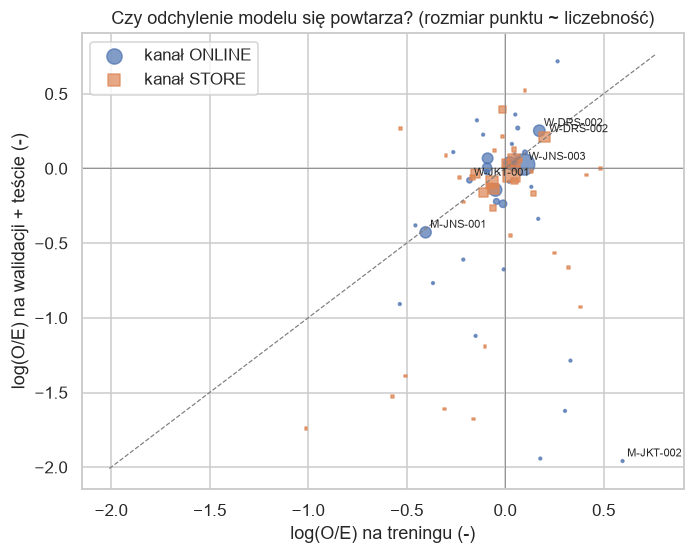

,Channel,StyleCode,StyleName,sold,oe,z,sold_l,obs_l,exp_l,z_l,oe_l
9,ONLINE,M-JNS-001,Jeansy regular,"4,243",0.6700,-12.8600,"1,237",208,319.2100,-7.2700,0.6500
28,ONLINE,W-JNS-003,Jeansy skinny,"14,588",1.1000,7.2600,"4,500","1,197","1,164.7800",1.1000,1.0300
56,STORE,W-DRS-002,Sukienka koszulowa,"11,710",1.2200,4.8600,"7,190",350,282.8900,4.0700,1.2400
20,ONLINE,W-DRS-002,Sukienka koszulowa,"3,403",1.1900,4.8300,"2,103",432,335.3300,5.7700,1.2900
25,ONLINE,W-JKT-001,Kurtka pikowana damska,"3,510",0.8300,-4.3600,444,67,72.5700,-0.7200,0.9200
7,ONLINE,M-JKT-002,Kurtka przejściowa,100,1.8400,3.7200,20,0,3.0500,-1.9000,0
61,STORE,W-JKT-001,Kurtka pikowana damska,"12,152",0.8500,-3.3600,"1,652",60,63.7900,-0.4800,0.9400
42,STORE,M-JKT-001,Kurtka miejska,"11,408",1.1600,3.3300,"1,471",48,56.8400,-1.2000,0.8400


In [29]:
later = pd.concat([SPL["val"], SPL["test"]]).astype({"Category": str, "Size": str, "StyleCode": str})
Lt = later.merge(cell, on=["Channel", "Category", "Size"], how="left")
Lt["exp"] = Lt.sold_qty * Lt.p_cell
Lt["v"] = Lt.sold_qty * Lt.p_cell * (1 - Lt.p_cell)
sm_l = Lt.groupby(["Channel", "StyleCode"]).agg(sold_l=("sold_qty", "sum"), obs_l=("ret_qty_h", "sum"), exp_l=("exp", "sum"), var_l=("v", "sum")).reset_index()
cmp3 = sm.merge(sm_l, on=["Channel", "StyleCode"])
cmp3["lo_tr"] = np.log((cmp3.obs + 0.5) / (cmp3.exp + 0.5))
cmp3["lo_l"] = np.log((cmp3.obs_l + 0.5) / (cmp3.exp_l + 0.5))
cmp3["z_l"] = (cmp3.obs_l - cmp3.exp_l) / np.sqrt(cmp3.var_l)
cmp3["w"] = np.minimum(cmp3.exp, cmp3.exp_l)

def wcorr(a, b, w):
    ma, mb = np.average(a, weights=w), np.average(b, weights=w)
    cov = np.average((a - ma) * (b - mb), weights=w)
    return cov / np.sqrt(np.average((a - ma) ** 2, weights=w) * np.average((b - mb) ** 2, weights=w))

rho = wcorr(cmp3.lo_tr, cmp3.lo_l, cmp3.w)
styles = cmp3.StyleCode.unique()
rng3 = np.random.default_rng(SEED)
bs = []
for _ in range(2000):
    pick = rng3.choice(styles, len(styles))
    bsamp = pd.concat([cmp3[cmp3.StyleCode == s] for s in pick])
    bs.append(wcorr(bsamp.lo_tr, bsamp.lo_l, bsamp.w))
rho_lo, rho_hi = np.quantile(bs, [0.025, 0.975])
rho_sp = stats.spearmanr(cmp3.lo_tr, cmp3.lo_l)[0]
print(f"H3: korelacja ważona log(O/E) trening vs walidacja+test: {rho:.3f} [{rho_lo:.3f}; {rho_hi:.3f}] (bootstrap po modelach, 2000); Spearman bez wag: {rho_sp:.3f}")
for ch in ["ONLINE", "STORE"]:
    g = cmp3[cmp3.Channel == ch]
    print(f"  {ch}: korelacja ważona {wcorr(g.lo_tr, g.lo_l, g.w):.3f}; poza ±1,96 SD w danych późniejszych (oczekiwania z treningu): {(g.z_l.abs() > 1.96).sum()} z {len(g)}; chi2/model = {(g.z_l ** 2).mean():.2f}")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
for ch, mk in [("ONLINE", "o"), ("STORE", "s")]:
    g = cmp3[cmp3.Channel == ch]
    ax.scatter(g.lo_tr, g.lo_l, s=np.clip(g.w, 20, 1500) / 6, marker=mk, alpha=0.7, label=f"kanał {ch}")
for _, r in cmp3.reindex(cmp3.z.abs().sort_values(ascending=False).index).head(6).iterrows():
    ax.annotate(r.StyleCode, (r.lo_tr, r.lo_l), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = [min(cmp3.lo_tr.min(), cmp3.lo_l.min()) - 0.05, max(cmp3.lo_tr.max(), cmp3.lo_l.max()) + 0.05]
ax.plot(lim, lim, c="grey", lw=0.8, ls="--"); ax.axhline(0, c="grey", lw=0.5); ax.axvline(0, c="grey", lw=0.5)
ax.set(title="Czy odchylenie modelu się powtarza? (rozmiar punktu ~ liczebność)", xlabel="log(O/E) na treningu (-)", ylabel="log(O/E) na walidacji + teście (-)")
ax.legend(); plt.tight_layout(); plt.show()
display(cmp3.reindex(cmp3.z.abs().sort_values(ascending=False).index).head(8)[["Channel", "StyleCode", "StyleName", "sold", "oe", "z", "sold_l", "obs_l", "exp_l", "z_l"]].assign(oe_l=lambda d: d.obs_l / d.exp_l).round(2))

(WYNIK_H3)

### Test H4: zmiany struktury powodów zwrotu w czasie (monitoring jakości)

**Po co:** wzrost udziału uszkodzeń (`DAMAGED`) w zwrotach danego modelu to sygnał problemu jakości (partia, dostawca), który nie wynika z rozmiaru ani kanału. Porównuję udział `DAMAGED` wśród zwrotów z podanym powodem dla sprzedaży **od 2026-02-10 do 2026-08-01** z wcześniejszą (od 2025-01-01) w każdym z 36 modeli (kanały razem, jak w Fazie 4), testem dwóch proporcji; 36 testów, więc kontroluję FDR (Benjamini-Hochberg). Zastrzeżenie: powód wpisuje obsługa przy przyjęciu, więc zmiana może też oznaczać zmianę praktyki wpisywania.

H4: udział DAMAGED wśród zwrotów z powodem; 36 modeli; przy samej losowości oczekiwane poniżej 1.8 modeli z p < 0,05
Modele z p < 0,05 (bez korekty): 7; z p_FDR < 0,05: 3; z p_FDR < 0,05 i wzrostem >= 5 pp: 2


,StyleCode,StyleName,n_wczesniej,n_pozniej,sh_w,sh_p,delta_pp,p,p_fdr
13,M-SHI-001,Koszula oxford,898,513,0.1470,0.5224,37.5424,0,0
32,W-KNT-003,Sweter z golfem,37,15,0.0541,0.4000,34.5946,0.0017,0.0271
34,W-TSH-001,T-shirt basic damski,"2,175",919,0.1117,0.1513,3.9527,0.0023,0.0271
5,A-WLT-001,Portfel skórzany,10,6,0.2000,0.8333,63.3333,0.0134,0.1208
0,A-BAG-001,Torebka shopper,489,197,0.2658,0.1878,-7.8031,0.0312,0.2122
23,W-DRS-005,Sukienka wieczorowa,31,25,0.1613,0,-16.1290,0.0354,0.2122
25,W-JKT-001,Kurtka pikowana damska,842,213,0.1401,0.0892,-5.0941,0.0482,0.2477
21,W-DRS-003,Sukienka mini,784,460,0.1186,0.1565,3.7899,0.0571,0.2536


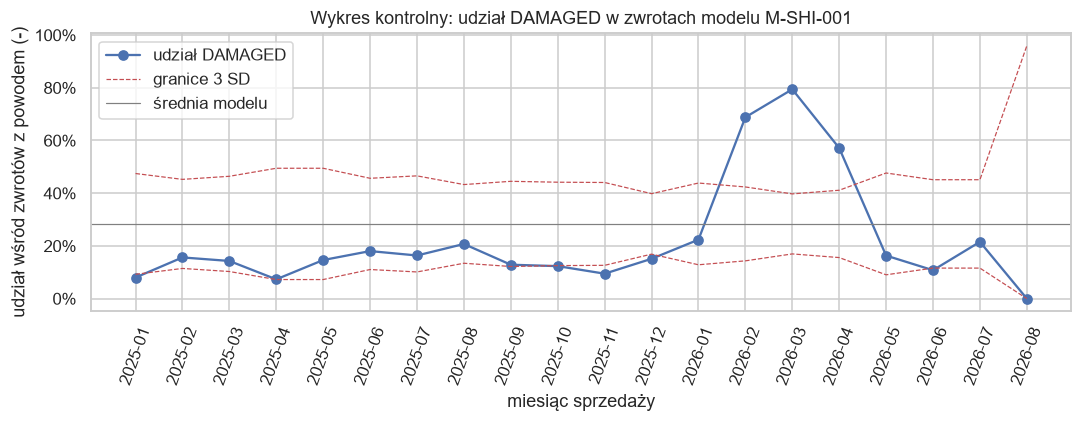

In [30]:
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest

rsn = q(f"""
SELECT p.StyleCode, p.StyleName, k.Channel, k.SaleDate, strftime(k.SaleDate, '%Y-%m') AS ym_sprz, r.ReturnReason AS powod, SUM(r.Quantity) AS sztuki
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) JOIN dim_product p ON p.ProductKey = r.ProductKey
WHERE k.SaleDate <= DATE '{LABEL_CLOSED_BEFORE}' AND DATE_DIFF('day', k.SaleDate, r.ReturnDate) <= {H} AND r.ReturnReason IS NOT NULL
GROUP BY ALL
""")
rsn["SaleDate"] = pd.to_datetime(rsn.SaleDate)
rsn["okres"] = np.where(rsn.SaleDate >= pd.Timestamp("2026-02-10"), "pozniej", "wczesniej")
a = rsn.assign(dmg=np.where(rsn.powod == "DAMAGED", rsn.sztuki, 0)).groupby(["StyleCode", "StyleName", "okres"]).agg(dmg=("dmg", "sum"), n=("sztuki", "sum")).unstack("okres")
a.columns = [f"{x}_{y}" for x, y in a.columns]
a = a.reset_index()
a["sh_w"], a["sh_p"] = a.dmg_wczesniej / a.n_wczesniej, a.dmg_pozniej / a.n_pozniej
a["delta_pp"] = (a.sh_p - a.sh_w) * 100
a["p"] = [proportions_ztest([r.dmg_pozniej, r.dmg_wczesniej], [r.n_pozniej, r.n_wczesniej])[1] for r in a.itertuples()]
a["p_fdr"] = multipletests(a.p, method="fdr_bh")[1]
print(f"H4: udział DAMAGED wśród zwrotów z powodem; {len(a)} modeli; przy samej losowości oczekiwane poniżej {0.05 * len(a):.1f} modeli z p < 0,05")
print(f"Modele z p < 0,05 (bez korekty): {(a.p < 0.05).sum()}; z p_FDR < 0,05: {(a.p_fdr < 0.05).sum()}; z p_FDR < 0,05 i wzrostem >= 5 pp: {((a.p_fdr < 0.05) & (a.delta_pp >= 5)).sum()}")
display(a.sort_values("p").head(8)[["StyleCode", "StyleName", "n_wczesniej", "n_pozniej", "sh_w", "sh_p", "delta_pp", "p", "p_fdr"]].round(4))

# Wykres kontrolny (p-chart) udziału DAMAGED wg miesiąca sprzedaży dla modelu o najniższym p
top = a.sort_values("p").iloc[0].StyleCode
mm = rsn[rsn.StyleCode == top].assign(dmg=lambda d: np.where(d.powod == "DAMAGED", d.sztuki, 0)).groupby("ym_sprz").agg(dmg=("dmg", "sum"), n=("sztuki", "sum")).reset_index()
mm["sh"] = mm.dmg / mm.n
pbar = mm.dmg.sum() / mm.n.sum()
mm["ucl"] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / mm.n)
mm["lcl"] = np.maximum(pbar - 3 * np.sqrt(pbar * (1 - pbar) / mm.n), 0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mm.ym_sprz, mm.sh, "o-", label="udział DAMAGED")
ax.plot(mm.ym_sprz, mm.ucl, "r--", lw=0.8, label="granice 3 SD"); ax.plot(mm.ym_sprz, mm.lcl, "r--", lw=0.8)
ax.axhline(pbar, c="grey", lw=0.8, label="średnia modelu")
ax.set(title=f"Wykres kontrolny: udział DAMAGED w zwrotach modelu {top}", xlabel="miesiąc sprzedaży", ylabel="udział wśród zwrotów z powodem (-)")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0)); ax.tick_params(axis="x", rotation=70); ax.legend()
plt.tight_layout(); plt.show()

(WYNIK_H4)

## Faza 6: metody (iteracyjnie, z ablacją)

### M1: regresja logistyczna z regularyzacją

**Po co:** model interpretowalny na poziomie sztuki, który pokazuje, ile informacji niosą kolejne grupy cech. Dopasowuję go **osobno w każdym kanale**, co jest równoważne pełnym interakcjom kanał × (rozmiar, kategoria, cena, rabat, paragon, ...) i pozwala ocenić jakość wewnątrz kanału. **Regularyzacja L2** (kara za duże współczynniki) ogranicza przeuczenie; siłę kary (parametr *C*, większe = słabsza kara) wybieram na walidacji. Cechy liczbowe standaryzuję wg treningu.

**Ablacja przyrostowa:** zaczynam od produktu (kategoria, rozmiar) i dodaję po jednej grupie cech: cena i rabat → kalendarz → zawartość paragonu → model → historia modelu as-of. Różnica jakości po dodaniu grupy pokazuje jej wkład.

In [31]:
from sklearn.linear_model import LogisticRegression

IDX = {s: np.flatnonzero((d.split == s).to_numpy()) for s in ["train", "val", "test"]}
CH = d.Channel.to_numpy()
GROUPS = ["produkt", "cena i rabat", "kalendarz", "paragon", "model", "historia modelu (as-of)"]

def dum(cols):
    parts = []
    for c in cols:
        cats = sorted(d[c].astype(str).unique())
        parts.append(pd.get_dummies(pd.Categorical(d[c].astype(str), categories=cats), prefix=c, dtype=float).set_axis(d.index))
    return pd.concat(parts, axis=1)

XG, NUMCOLS = {}, {}
XG["produkt"] = dum(["Category", "Size"])
XG["model"] = dum(["StyleCode"])
XG["cena i rabat"] = d[["log_price", "disc_rate"]].astype(float); NUMCOLS["cena i rabat"] = ["log_price", "disc_rate"]
cal = dum(["month", "DayOfWeek", "season_type"]); cal["season_day"] = d.season_day.astype(float)
XG["kalendarz"] = cal; NUMCOLS["kalendarz"] = ["season_day"]
bsk = d[["n_lines", "n_units", "n_cat", "log_basket", "n_sku_style", "qty_style", "sold_qty", "multi_size"]].astype(float)
bsk = pd.concat([bsk, pd.get_dummies(d.n_size_style.clip(upper=3).astype(str), prefix="n_size_style", dtype=float)], axis=1)
XG["paragon"] = bsk; NUMCOLS["paragon"] = ["n_lines", "n_units", "n_cat", "log_basket", "n_sku_style", "qty_style", "sold_qty"]
h = d[["hist_style", "hist_cell"]].copy()
h["hist_brak"] = h.hist_style.isna().astype(float)
for c in ["hist_style", "hist_cell"]:
    h[c] = h[c].fillna(h.loc[IDX["train"], c].mean())
XG["historia modelu (as-of)"] = h; NUMCOLS["historia modelu (as-of)"] = ["hist_style", "hist_cell"]
# standaryzacja liczbowych kolumn wg treningu
for g, cols in NUMCOLS.items():
    mu, sd = XG[g].loc[IDX["train"], cols].mean(), XG[g].loc[IDX["train"], cols].std().replace(0, 1)
    XG[g][cols] = (XG[g][cols] - mu) / sd

def get_X(groups, idx):
    return pd.concat([XG[g].iloc[idx] for g in groups], axis=1).to_numpy(np.float32)

def fit_logit(groups, channel, C, train_idx):
    tri = train_idx[CH[train_idx] == channel]
    e = expand(d.iloc[tri])
    X = get_X(groups, tri)[e.i.to_numpy()]
    m = LogisticRegression(C=C, max_iter=300, tol=1e-4)
    m.fit(X, e.y.to_numpy(), sample_weight=e.w.to_numpy())
    return m

def predict_logit(models, groups, idx):
    p = np.full(len(idx), np.nan)
    for ch, m in models.items():
        mask = CH[idx] == ch
        p[mask] = m.predict_proba(get_X(groups, idx[mask]))[:, 1]
    return p

# Dobór siły regularyzacji na walidacji (kara log-loss ważona sztukami) dla pełnego zestawu cech, osobno w kanałach
def wlogloss(y, p, w):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -np.average(y * np.log(p) + (1 - y) * np.log(1 - p), weights=w)

best_C = {}
tune = []
for ch in ["ONLINE", "STORE"]:
    vi = IDX["val"][CH[IDX["val"]] == ch]
    ev = expand(d.iloc[vi])
    for C in [0.01, 0.1, 1.0]:
        m = fit_logit(GROUPS, ch, C, IDX["train"])
        p = m.predict_proba(get_X(GROUPS, vi))[:, 1][ev.i.to_numpy()]
        tune.append([ch, C, wlogloss(ev.y.to_numpy(), p, ev.w.to_numpy())])
tune = pd.DataFrame(tune, columns=["kanał", "C", "log-loss (walidacja)"])
best_C = tune.loc[tune.groupby("kanał")["log-loss (walidacja)"].idxmin()].set_index("kanał").C.to_dict()
display(tune.round(5))
print("Wybrane C:", best_C)

,kanał,C,log-loss (walidacja)
0,ONLINE,0.0100,0.4292
1,ONLINE,0.1000,0.4294
2,ONLINE,1,0.4295
3,STORE,0.0100,0.1641
4,STORE,0.1000,0.1642
5,STORE,1,0.1643


Wybrane C: {'ONLINE': 0.01, 'STORE': 0.01}


In [32]:
# Ablacja przyrostowa M1 na walidacji (punktowo; przedziały dla modeli finalnych niżej).
abl_rows, P_m1_val = [], {}
for k in range(1, len(GROUPS) + 1):
    gs = GROUPS[:k]
    models = {ch: fit_logit(gs, ch, best_C[ch], IDX["train"]) for ch in ["ONLINE", "STORE"]}
    p = predict_logit(models, gs, IDX["val"])
    P_m1_val[k] = p
    t, _ = EV["val"].table({f"M1 do: {gs[-1]}": p})
    t["kroki"] = k
    abl_rows.append(t)
abl_m1 = pd.concat(abl_rows)
b1b = EV["val"].table({"B1b": P_base["val"]["B1b kanał x kategoria x rozmiar"]})[0]
display(pd.concat([b1b.assign(kroki=0), abl_m1])[["kroki", "model", "kanał", "roc", "pr", "brier", "bss", "lift10"]].round(4).reset_index(drop=True))

,kroki,model,kanał,roc,pr,brier,bss,lift10
0,0,B1b,ONLINE,0.5775,0.2099,0.1367,0.0108,1.5279
1,0,B1b,STORE,0.5124,0.0405,0.0378,-0.0004,1.0743
2,1,M1 do: produkt,ONLINE,0.5771,0.2096,0.1366,0.0115,1.5279
3,1,M1 do: produkt,STORE,0.5127,0.0403,0.0378,-0.0003,1.0076
4,2,M1 do: cena i rabat,ONLINE,0.5822,0.2165,0.1364,0.0128,1.5128
5,2,M1 do: cena i rabat,STORE,0.5195,0.0409,0.0378,-0,0.9928
6,3,M1 do: kalendarz,ONLINE,0.5772,0.2132,0.1364,0.0127,1.4523
7,3,M1 do: kalendarz,STORE,0.5185,0.0405,0.0378,0,0.9854
8,4,M1 do: paragon,ONLINE,0.6433,0.2670,0.1323,0.0424,2.0506
9,4,M1 do: paragon,STORE,0.5582,0.0570,0.0376,0.0045,1.9337


(WYNIK_M1ABL)

### M2: model gradientowy (LightGBM)

**Po co:** sprawdzić, czy model z nieliniowościami i interakcjami (np. rozmiar × model × kanał × zawartość paragonu) daje wymierną przewagę nad regresją logistyczną i tabelami. **LightGBM** buduje sekwencję płytkich drzew, z których każde poprawia błędy poprzednich. Jeden model dla obu kanałów (kanał jest cechą), parametry zachowawcze (małe drzewa, duże minimum obserwacji w liściu, regularyzacja), liczbę drzew wybieram na walidacji (wczesne zatrzymanie). Ablacja jak wyżej, dodatkowo „usuń jedną grupę" od pełnego zestawu.

In [33]:
import lightgbm as lgb

LGB_PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=15, min_data_in_leaf=300, feature_fraction=0.8, bagging_fraction=0.8,
                  bagging_freq=1, lambda_l2=20.0, cat_smooth=50, min_data_per_group=300, verbose=-1, seed=SEED, num_threads=4)

def lgb_cols(groups):
    return [c for g in ["kanał"] + list(groups) for c in FEATS[g]]

def lgb_set(idx, cols, reference=None):
    e = expand(d.iloc[idx])
    X = d.iloc[idx][cols].iloc[e.i.to_numpy()].reset_index(drop=True)
    return lgb.Dataset(X, label=e.y.to_numpy(), weight=e.w.to_numpy(), reference=reference, free_raw_data=False)

def fit_lgb(groups, train_idx, val_idx=None, rounds=None, params=None):
    cols = lgb_cols(groups)
    dtr = lgb_set(train_idx, cols)
    prm = {**LGB_PARAMS, **(params or {})}
    if rounds is None:
        dva = lgb_set(val_idx, cols, reference=dtr)
        m = lgb.train(prm, dtr, num_boost_round=1200, valid_sets=[dva], callbacks=[lgb.early_stopping(60, verbose=False)])
    else:
        m = lgb.train(prm, dtr, num_boost_round=rounds)
    m.cols = cols
    return m

def pred_lgb(m, idx):
    return m.predict(d.iloc[idx][m.cols], num_iteration=m.best_iteration if m.best_iteration else None)

GROUPS_L = ["produkt", "model", "cena i rabat", "kalendarz", "paragon", "historia modelu (as-of)"]
rows, P_m2_val, best_it = [], {}, {}
for k in range(1, len(GROUPS_L) + 1):
    gs = GROUPS_L[:k]
    m = fit_lgb(gs, IDX["train"], IDX["val"])
    p = pred_lgb(m, IDX["val"])
    P_m2_val[k], best_it[k] = p, m.best_iteration
    t, _ = EV["val"].table({f"M2 do: {gs[-1]}": p}); t["kroki"] = k; t["drzewa"] = m.best_iteration
    rows.append(t)
abl_m2 = pd.concat(rows)
display(abl_m2[["kroki", "model", "kanał", "drzewa", "roc", "pr", "brier", "bss", "lift10"]].round(4).reset_index(drop=True))

# Usuń jedną grupę od pełnego zestawu (M2)
full = GROUPS_L
rows = []
for g in full[:]:
    gs = [x for x in full if x != g]
    m = fit_lgb(gs, IDX["train"], IDX["val"])
    t, _ = EV["val"].table({f"M2 bez: {g}": pred_lgb(m, IDX["val"])}); rows.append(t)
drop2 = pd.concat(rows)
display(drop2[["model", "kanał", "roc", "pr", "brier", "bss", "lift10"]].round(4).reset_index(drop=True))

,kroki,model,kanał,drzewa,roc,pr,brier,bss,lift10
0,1,M2 do: produkt,ONLINE,173,0.5771,0.2091,0.1367,0.0107,1.5279
1,1,M2 do: produkt,STORE,173,0.5186,0.0405,0.0378,-0.0011,1.0002
2,2,M2 do: model,ONLINE,70,0.5902,0.2183,0.1362,0.0144,1.5279
3,2,M2 do: model,STORE,70,0.5305,0.0421,0.0378,-0.0001,0.9928
4,3,M2 do: cena i rabat,ONLINE,69,0.5894,0.2177,0.1362,0.0146,1.5262
5,3,M2 do: cena i rabat,STORE,69,0.5321,0.0422,0.0378,0.0001,1.0376
6,4,M2 do: kalendarz,ONLINE,75,0.5904,0.2203,0.1362,0.0146,1.5733
7,4,M2 do: kalendarz,STORE,75,0.5295,0.0423,0.0378,0.0002,1.0005
8,5,M2 do: paragon,ONLINE,118,0.6617,0.2899,0.1302,0.0581,2.2658
9,5,M2 do: paragon,STORE,118,0.5679,0.0647,0.0375,0.0074,1.9337


,model,kanał,roc,pr,brier,bss,lift10
0,M2 bez: produkt,ONLINE,0.6515,0.2870,0.1306,0.0550,2.2322
1,M2 bez: produkt,STORE,0.5668,0.0638,0.0375,0.0073,1.9263
2,M2 bez: model,ONLINE,0.6579,0.2889,0.1304,0.0563,2.2255
3,M2 bez: model,STORE,0.5720,0.0644,0.0375,0.0073,1.9634
4,M2 bez: cena i rabat,ONLINE,0.6598,0.2883,0.1304,0.0565,2.2389
5,M2 bez: cena i rabat,STORE,0.5705,0.0635,0.0375,0.0073,1.9121
6,M2 bez: kalendarz,ONLINE,0.6618,0.2895,0.1304,0.0566,2.2591
7,M2 bez: kalendarz,STORE,0.5700,0.0632,0.0375,0.0072,1.9485
8,M2 bez: paragon,ONLINE,0.5908,0.2191,0.1363,0.0139,1.5414
9,M2 bez: paragon,STORE,0.5310,0.0422,0.0378,0.0002,1.0595


(WYNIK_M2ABL)

### Porównanie na walidacji i teście (z przedziałami) oraz H2

**Po co:** zestawić baseline'y i modele finalne tym samym miarami, z przedziałami bootstrap klastrowego po paragonach (te same próby dla wszystkich), osobno w kanałach. Test oceniam raz, modelami **zamrożonymi na treningu**, oraz wariantem **ponownie dopasowanym** na wszystkich sprzedażach, dla których w dniu 2026-06-01 etykieta była już znana (sprzedaż do 2026-04-11), czyli tak jak byłoby w praktyce przy cyklicznym douczaniu. Konfigurację (zestaw cech, C, liczba drzew) wybrałem wyłącznie na walidacji.

**H2 (cechy zakupu ponad kanał, kategorię i rozmiar):** przyrost jakości M1 „produkt + cena i rabat + kalendarz + paragon" względem M1 „tylko produkt", reguła z Fazy 4: przyrost ROC-AUC ≥ 0,01 z dolną granicą > 0 w danym kanale.

In [34]:
REFIT_END = pd.Timestamp("2026-06-01") - pd.Timedelta(days=H)  # sprzedaż przed tą datą ma zamknięte okno w dniu startu testu
refit_idx = np.flatnonzero((d.SaleDate < REFIT_END).to_numpy())
print(f"Dopasowanie ponowne: {len(refit_idx):,} kluczy ze sprzedaży do {(REFIT_END - pd.Timedelta(days=1)).date()} (trening + strefa ochronna + początek walidacji)")

G_M1_FULL, G_M1_PURCH = GROUPS, GROUPS[:4]
M1 = {ch: fit_logit(G_M1_FULL, ch, best_C[ch], IDX["train"]) for ch in ["ONLINE", "STORE"]}
M1p = {ch: fit_logit(G_M1_PURCH, ch, best_C[ch], IDX["train"]) for ch in ["ONLINE", "STORE"]}
M1a = {ch: fit_logit(GROUPS[:1], ch, best_C[ch], IDX["train"]) for ch in ["ONLINE", "STORE"]}
M1r = {ch: fit_logit(G_M1_FULL, ch, best_C[ch], refit_idx) for ch in ["ONLINE", "STORE"]}
M2 = fit_lgb(GROUPS_L, IDX["train"], IDX["val"])
M2r = fit_lgb(GROUPS_L, refit_idx, rounds=M2.best_iteration)
print("M2: liczba drzew (walidacja):", M2.best_iteration)

PRED = {}
for s in ["val", "test"]:
    PRED[s] = {
        "B0 kanał": P_base[s]["B0 kanał"], "B1 kanał x kategoria": P_base[s]["B1 kanał x kategoria"],
        "B1b kanał x kategoria x rozmiar": P_base[s]["B1b kanał x kategoria x rozmiar"],
        "M1 logit (pełny)": predict_logit(M1, G_M1_FULL, IDX[s]), "M2 LightGBM (pełny)": pred_lgb(M2, IDX[s]),
        "M1 logit (pełny), douczony": predict_logit(M1r, G_M1_FULL, IDX[s]), "M2 LightGBM, douczony": pred_lgb(M2r, IDX[s]),
        "M1 tylko produkt": predict_logit(M1a, GROUPS[:1], IDX[s]), "M1 produkt + zakup (bez modelu i historii)": predict_logit(M1p, G_M1_PURCH, IDX[s]),
    }
RES = {}
for s in ["val", "test"]:
    RES[s], _ = EV[s].table(PRED[s], B=100, cnts=BOOT[s])
    RES[s]["split"] = s
allres = pd.concat(RES.values(), ignore_index=True)
cols = ["split", "model", "kanał", "roc", "roc_lo", "roc_hi", "pr", "pr_lo", "pr_hi", "brier", "bss", "lift10", "lift10_lo", "lift10_hi"]
for ch in ["ONLINE", "STORE"]:
    print(f"=== kanał {ch} ===")
    display(allres[allres["kanał"] == ch][cols].round(4).reset_index(drop=True))

Dopasowanie ponowne: 313,785 kluczy ze sprzedaży do 2026-04-11 (trening + strefa ochronna + początek walidacji)


M2: liczba drzew (walidacja): 103


=== kanał ONLINE ===


,split,model,kanał,roc,roc_lo,roc_hi,pr,pr_lo,pr_hi,brier,bss,lift10,lift10_lo,lift10_hi
0,val,B0 kanał,ONLINE,0.5000,0.5000,0.5000,0.1656,0.1567,0.1734,0.1384,-0.0016,0.9614,0.7809,1.1232
1,val,B1 kanał x kategoria,ONLINE,0.5482,0.5324,0.5681,0.1894,0.1752,0.2016,0.1375,0.0052,1.3514,1.1940,1.5262
2,val,B1b kanał x kategoria x rozmiar,ONLINE,0.5775,0.5620,0.5948,0.2099,0.1922,0.2275,0.1367,0.0108,1.5279,1.3244,1.7125
3,val,M1 logit (pełny),ONLINE,0.6478,0.6301,0.6660,0.2670,0.2497,0.2867,0.1324,0.0422,2.0305,1.8536,2.2243
4,val,M2 LightGBM (pełny),ONLINE,0.6601,0.6438,0.6791,0.2890,0.2702,0.3113,0.1304,0.0564,2.2523,2.0740,2.4577
5,val,"M1 logit (pełny), douczony",ONLINE,0.6489,0.6309,0.6665,0.2680,0.2510,0.2875,0.1322,0.0431,2.0708,1.9018,2.2583
6,val,"M2 LightGBM, douczony",ONLINE,0.6634,0.6482,0.6815,0.2917,0.2738,0.3129,0.1302,0.0581,2.2523,2.0821,2.4681
7,val,M1 tylko produkt,ONLINE,0.5771,0.5599,0.5958,0.2096,0.1916,0.2254,0.1366,0.0115,1.5279,1.3244,1.7125
8,val,M1 produkt + zakup (bez modelu i historii),ONLINE,0.6433,0.6265,0.6642,0.2670,0.2497,0.2865,0.1323,0.0424,2.0506,1.8743,2.2345
9,test,B0 kanał,ONLINE,0.5000,0.5000,0.5000,0.1920,0.1850,0.1978,0.1552,-0.0008,1.0812,0.9357,1.1967


=== kanał STORE ===


,split,model,kanał,roc,roc_lo,roc_hi,pr,pr_lo,pr_hi,brier,bss,lift10,lift10_lo,lift10_hi
0,val,B0 kanał,STORE,0.5000,0.5000,0.5000,0.0393,0.0373,0.0418,0.0378,-0,0.9261,0.8197,1.0915
1,val,B1 kanał x kategoria,STORE,0.5069,0.4891,0.5228,0.0400,0.0372,0.0430,0.0378,0,0.9857,0.8151,1.1126
2,val,B1b kanał x kategoria x rozmiar,STORE,0.5124,0.4959,0.5271,0.0405,0.0373,0.0438,0.0378,-0.0004,1.0743,0.8920,1.2508
3,val,M1 logit (pełny),STORE,0.5633,0.5456,0.5817,0.0569,0.0516,0.0639,0.0376,0.0045,1.9565,1.7227,2.1588
4,val,M2 LightGBM (pełny),STORE,0.5715,0.5521,0.5847,0.0625,0.0565,0.0692,0.0375,0.0072,1.9041,1.7233,2.0816
5,val,"M1 logit (pełny), douczony",STORE,0.5825,0.5642,0.6023,0.0593,0.0544,0.0664,0.0376,0.0054,1.9634,1.7429,2.1471
6,val,"M2 LightGBM, douczony",STORE,0.6014,0.5831,0.6171,0.0725,0.0646,0.0806,0.0374,0.0106,2.2449,2.0716,2.4426
7,val,M1 tylko produkt,STORE,0.5127,0.4963,0.5295,0.0403,0.0374,0.0437,0.0378,-0.0003,1.0076,0.8230,1.1388
8,val,M1 produkt + zakup (bez modelu i historii),STORE,0.5582,0.5391,0.5764,0.0570,0.0516,0.0632,0.0376,0.0045,1.9337,1.7029,2.1484
9,test,B0 kanał,STORE,0.5000,0.5000,0.5000,0.0398,0.0379,0.0418,0.0382,-0,1.0202,0.8566,1.1818


In [35]:
# Różnice sparowane (te same próby bootstrapowe) względem najlepszego baseline'u B1b i H2: produkt + zakup vs sam produkt
def paired(s, a, b, ch, metric):
    ba, bb = EV[s].boot(a, PRED[s][a], ch, BOOT[s]), EV[s].boot(b, PRED[s][b], ch, BOOT[s])
    pt = EV[s].metrics(PRED[s][a], ch)[metric] - EV[s].metrics(PRED[s][b], ch)[metric]
    return pt, *np.quantile((ba[metric] - bb[metric]).to_numpy(), [0.025, 0.975])

rows = []
for s in ["val", "test"]:
    for ch in ["ONLINE", "STORE"]:
        for a, b, lab in [("M1 logit (pełny)", "B1b kanał x kategoria x rozmiar", "M1 pełny - B1b"), ("M2 LightGBM (pełny)", "B1b kanał x kategoria x rozmiar", "M2 pełny - B1b"),
                          ("M2 LightGBM (pełny)", "M1 logit (pełny)", "M2 - M1"), ("M1 produkt + zakup (bez modelu i historii)", "M1 tylko produkt", "H2: produkt+zakup - sam produkt")]:
            for metric in ["roc", "pr", "brier"]:
                pt, lo, hi = paired(s, a, b, ch, metric)
                rows.append([s, ch, lab, metric, pt, lo, hi])
diff = pd.DataFrame(rows, columns=["split", "kanał", "różnica", "metryka", "wartość", "lo", "hi"])
display(diff.round(4))

,split,kanał,różnica,metryka,wartość,lo,hi
0,val,ONLINE,M1 pełny - B1b,roc,0.0703,0.0532,0.0876
1,val,ONLINE,M1 pełny - B1b,pr,0.0571,0.0449,0.0716
2,val,ONLINE,M1 pełny - B1b,brier,-0.0043,-0.0058,-0.0031
3,val,ONLINE,M2 pełny - B1b,roc,0.0825,0.0645,0.0984
4,val,ONLINE,M2 pełny - B1b,pr,0.0790,0.0653,0.0960
5,val,ONLINE,M2 pełny - B1b,brier,-0.0063,-0.0079,-0.0049
6,val,ONLINE,M2 - M1,roc,0.0123,0.0057,0.0174
7,val,ONLINE,M2 - M1,pr,0.0220,0.0127,0.0345
8,val,ONLINE,M2 - M1,brier,-0.0020,-0.0029,-0.0012
9,val,ONLINE,H2: produkt+zakup - sam produkt,roc,0.0661,0.0486,0.0849


(WYNIK_PORÓWNANIE)

## Faza 7: diagnostyka i odporność

### Kalibracja i lift

**Po co:** **kalibracja** odpowiada na pytanie, czy przewidziane prawdopodobieństwo jest wiarygodne (sztuki z wynikiem 20% faktycznie wracają w ok. 20% przypadków). Sam ranking (ROC-AUC) tego nie sprawdza, a przy planowaniu działań (np. „ilu klientów zapytać o rozmiar") liczy się też poziom. **Lift w górnych 10%** mówi, o ile gęściej zwracają się sztuki z najwyższych 10% wyniku niż średnia kanału: tylko wtedy ma sens akcja, która obejmuje wybraną część zakupów.

Dane: test (modele zamrożone na treningu), kanały osobno. Kolumny: przeciętny wynik modelu w koszyku (decylu) i faktyczny wskaźnik.

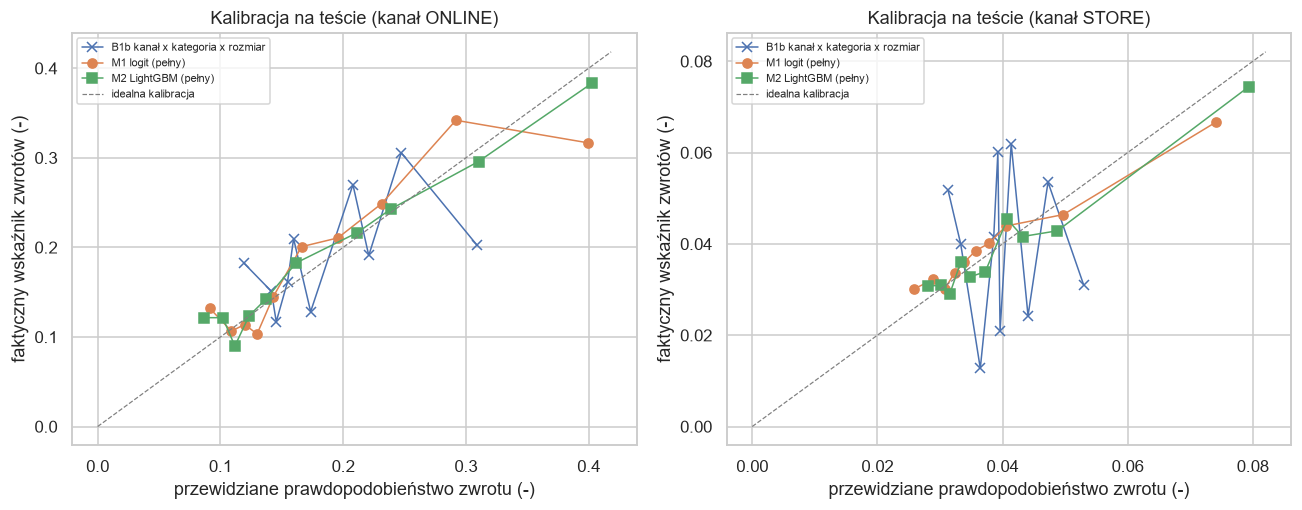

,model,kanał,Brier surowy,Brier po rekalibracji,ROC surowy,ROC po rekalibracji
0,M1 logit (pełny),ONLINE,0.1494,0.1487,0.6421,0.6433
1,M1 logit (pełny),STORE,0.0381,0.0382,0.5697,0.5665
2,M2 LightGBM (pełny),ONLINE,0.1474,0.1477,0.6530,0.6525
3,M2 LightGBM (pełny),STORE,0.0379,0.0380,0.5767,0.5751


Decyle wyniku M2 na teście, kanał ONLINE (decyl 1 = najwyższe ryzyko wg modelu)


dec,1,2,3,4,5,6,7,8,9,10
sold,"1,325","1,325","1,325","1,326","1,325","1,325","1,326","1,325","1,325","1,326"
ret,507,393,322,287,242,188,164,118,162,161
wsk,0.3830,0.2970,0.2430,0.2160,0.1830,0.1420,0.1240,0.0890,0.1220,0.1210
lift,1.9930,1.5450,1.2660,1.1280,0.9510,0.7390,0.6440,0.4640,0.6370,0.6330


Decyle wyniku M2 na teście, kanał STORE (decyl 1 = najwyższe ryzyko wg modelu)


dec,1,2,3,4,5,6,7,8,9,10
sold,"4,780","4,780","4,782","4,781","4,781","4,781","4,781","4,781","4,781","4,781"
ret,356,205,199,217,163,156,172,139,148,147
wsk,0.0740,0.0430,0.0420,0.0450,0.0340,0.0330,0.0360,0.0290,0.0310,0.0310
lift,1.8720,1.0780,1.0460,1.1410,0.8570,0.8200,0.9040,0.7310,0.7780,0.7730


In [36]:
from sklearn.isotonic import IsotonicRegression

def reliab(s, name, ch, bins=10):
    ev = EV[s]
    m = ev.ch == ch
    y, w = ev.e.y.to_numpy()[m], ev.e.w.to_numpy()[m]
    p = np.asarray(PRED[s][name])[ev.e.i.to_numpy()[m]]
    o = np.argsort(p, kind="stable")
    cum = np.cumsum(w[o]) / w.sum()
    b = np.minimum((cum * bins).astype(int), bins - 1)
    df_ = pd.DataFrame({"b": b, "p": p[o] * w[o], "y": y[o] * w[o], "w": w[o]}).groupby("b").sum()
    return df_.p / df_.w, df_.y / df_.w

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, ch in zip(axes, ["ONLINE", "STORE"]):
    for name, mk in [("B1b kanał x kategoria x rozmiar", "x"), ("M1 logit (pełny)", "o"), ("M2 LightGBM (pełny)", "s")]:
        px, py = reliab("test", name, ch)
        ax.plot(px, py, marker=mk, label=name, lw=1)
    lim = [0, max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lim, lim, c="grey", ls="--", lw=0.8, label="idealna kalibracja")
    ax.set(title=f"Kalibracja na teście (kanał {ch})", xlabel="przewidziane prawdopodobieństwo zwrotu (-)", ylabel="faktyczny wskaźnik zwrotów (-)")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Rekalibracja izotoniczna na walidacji (regresja monotoniczna) i jej efekt na teście
rows = []
for name in ["M1 logit (pełny)", "M2 LightGBM (pełny)"]:
    for ch in ["ONLINE", "STORE"]:
        mv, mt = (SPL["val"].Channel == ch).to_numpy(), (SPL["test"].Channel == ch).to_numpy()
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(PRED["val"][name][mv], (SPL["val"].ret_qty_h / SPL["val"].sold_qty).to_numpy()[mv], sample_weight=SPL["val"].sold_qty.to_numpy()[mv])
        p_new = np.array(PRED["test"][name], dtype=float)
        p_new[mt] = iso.predict(PRED["test"][name][mt])
        b0 = EV["test"].metrics(PRED["test"][name], ch)
        b1 = EV["test"].metrics(p_new, ch)
        rows.append([name, ch, b0["brier"], b1["brier"], b0["roc"], b1["roc"]])
display(pd.DataFrame(rows, columns=["model", "kanał", "Brier surowy", "Brier po rekalibracji", "ROC surowy", "ROC po rekalibracji"]).round(5))

# Lift: wskaźnik zwrotów w decylach wyniku (test), M2 i M1
def decile_table(s, name, ch):
    df_ = SPL[s]; mk = (df_.Channel == ch).to_numpy()
    x = pd.DataFrame({"p": np.asarray(PRED[s][name])[mk] + EV[s].jit[mk], "sold": df_.sold_qty.to_numpy()[mk], "ret": df_.ret_qty_h.to_numpy()[mk]}).sort_values("p", ascending=False)
    x["dec"] = np.minimum((x.sold.cumsum() / x.sold.sum() * 10).astype(int), 9) + 1
    g = x.groupby("dec").agg(sold=("sold", "sum"), ret=("ret", "sum"))
    g["wsk"] = g.ret / g.sold
    g["lift"] = g.wsk / (g.ret.sum() / g.sold.sum())
    return g
for ch in ["ONLINE", "STORE"]:
    print(f"Decyle wyniku M2 na teście, kanał {ch} (decyl 1 = najwyższe ryzyko wg modelu)")
    display(decile_table("test", "M2 LightGBM (pełny)", ch).T.round(3))

(WYNIK_KALIB)

### Stabilność w czasie i błędy wg modeli, rozmiarów

**Po co:** jeden wynik na całym teście może ukrywać pogorszenie w czasie. Pokazuję jakość miesiąc po miesiącu (kwiecień-maj: walidacja, czerwiec-lipiec: test) dla B1b, M1 i M2, oraz rozbicie błędu kalibracji (obserwowane wobec przewidywanych) na rozmiary i modele.

miesiąc sprzedaży                       2026-04  2026-05  2026-06  2026-07  2026-08
kanał  model                                                                       
ONLINE B1b kanał x kategoria x rozmiar   0.5740   0.5820   0.5520   0.5970   0.6360
       M1 logit (pełny)                  0.6570   0.6390   0.6150   0.6530   0.6540
       M2 LightGBM (pełny)               0.6700   0.6500   0.6260   0.6630   0.6680
STORE  B1b kanał x kategoria x rozmiar   0.4900   0.5360   0.5420   0.5250   0.5120
       M1 logit (pełny)                  0.5520   0.5710   0.5820   0.5590   0.5300
       M2 LightGBM (pełny)               0.5550   0.5880   0.5890   0.5670   0.5150

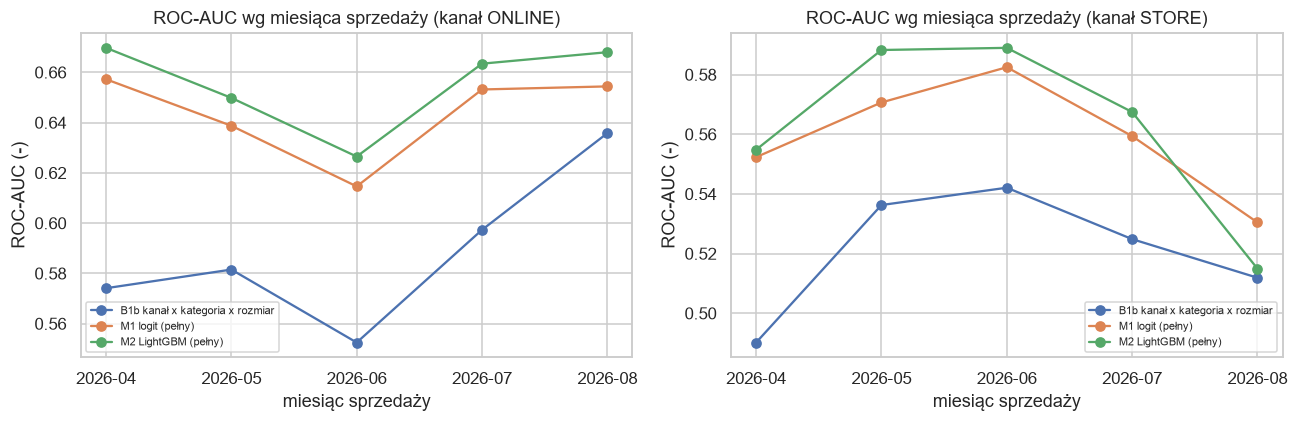

Channel    ONLINE                                              STORE                                            
Size            L        M     ONE        S       XL       XS      L        M     ONE        S       XL       XS
sold        3,497    4,066     553    2,502    1,760      875 12,669   14,535   2,358    9,045    6,034    3,168
obs           678      672      61      473      462      198    465      595      76      358      236      172
pred     645.6040 687.0330 43.3330 456.5300 446.7310 219.6960    524 567.1580 69.3280 370.8720 275.3990 140.7460
obs/pred   1.0500   0.9780  1.4080   1.0360   1.0340   0.9010 0.8870   1.0490  1.0960   0.9650   0.8570   1.2220

Modele x kanał na teście: obs/pred w przedziale [0.00; 4.82]; |z| > 3: 0 z 72


,Channel,StyleCode,sold,obs,pred,obs/pred,z
19,ONLINE,W-DRS-001,985,171,137.4980,1.2440,2.8570
0,ONLINE,A-BAG-001,368,41,27.7980,1.4750,2.5040
8,ONLINE,M-JKT-003,5,3,0.6230,4.8170,2.3770
50,STORE,M-SHI-002,96,0,4.4600,0,-2.1120
25,ONLINE,W-JKT-001,169,29,19.9900,1.4510,2.0150
60,STORE,W-DRS-006,98,0,3.7160,0,-1.9280


In [37]:
def month_metrics(name):
    rows = []
    for s in ["val", "test"]:
        ev = EV[s]
        mon = SPL[s].SaleDate.dt.strftime("%Y-%m").to_numpy()[ev.e.i.to_numpy()]
        for ch in ["ONLINE", "STORE"]:
            for mo in sorted(set(mon)):
                m = (ev.ch == ch) & (mon == mo)
                y, w = ev.e.y.to_numpy()[m], ev.e.w.to_numpy()[m]
                p = np.asarray(PRED[s][name])[ev.e.i.to_numpy()[m]]
                rows.append([name, ch, mo, w.sum(), np.average(y, weights=w), roc_auc_score(y, p, sample_weight=w) if len(np.unique(p)) > 1 else 0.5, np.average((y - p) ** 2, weights=w)])
    return pd.DataFrame(rows, columns=["model", "kanał", "miesiąc sprzedaży", "sztuki", "wskaźnik", "ROC", "Brier"])
mm_ = pd.concat([month_metrics(n) for n in ["B1b kanał x kategoria x rozmiar", "M1 logit (pełny)", "M2 LightGBM (pełny)"]])
piv = mm_.pivot_table(index=["kanał", "model"], columns="miesiąc sprzedaży", values="ROC")
display(piv.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, ch in zip(axes, ["ONLINE", "STORE"]):
    for n in ["B1b kanał x kategoria x rozmiar", "M1 logit (pełny)", "M2 LightGBM (pełny)"]:
        g = mm_[(mm_["kanał"] == ch) & (mm_.model == n)]
        ax.plot(g["miesiąc sprzedaży"], g.ROC, "o-", label=n)
    ax.set(title=f"ROC-AUC wg miesiąca sprzedaży (kanał {ch})", xlabel="miesiąc sprzedaży", ylabel="ROC-AUC (-)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Błąd kalibracji wg rozmiaru i wg modeli (test, M2): obserwowane vs przewidziane sztuki zwrócone
T = SPL["test"].assign(pred=np.asarray(PRED["test"]["M2 LightGBM (pełny)"]) * SPL["test"].sold_qty, Size=SPL["test"].Size.astype(str), StyleCode=SPL["test"].StyleCode.astype(str))
bysize = T.groupby(["Channel", "Size"]).agg(sold=("sold_qty", "sum"), obs=("ret_qty_h", "sum"), pred=("pred", "sum"))
bysize["obs/pred"] = bysize.obs / bysize.pred
display(bysize.round(3).T)
bystyle = T.groupby(["Channel", "StyleCode"]).agg(sold=("sold_qty", "sum"), obs=("ret_qty_h", "sum"), pred=("pred", "sum")).reset_index()
bystyle["obs/pred"] = bystyle.obs / bystyle.pred
bystyle["z"] = (bystyle.obs - bystyle.pred) / np.sqrt(bystyle.pred.clip(lower=1))
print(f"Modele x kanał na teście: obs/pred w przedziale [{bystyle['obs/pred'].min():.2f}; {bystyle['obs/pred'].max():.2f}]; |z| > 3: {(bystyle.z.abs() > 3).sum()} z {len(bystyle)}")
display(bystyle.reindex(bystyle.z.abs().sort_values(ascending=False).index).head(6).round(3))

(WYNIK_STAB)

### Wkład grup cech i wyjaśnienia modelu (ważność permutacyjna, SHAP)

**Po co:** zobaczyć, *na czym* opiera się M2 i czy to ma sens biznesowy. **Ważność permutacyjna grupy**: losowo mieszam kolumny jednej grupy cech naraz (wiersze walidacji) i mierzę spadek ROC-AUC w kanale; im większy spadek, tym więcej model „bierze" z tej grupy. Mieszam całe grupy, a nie pojedyncze kolumny, bo cechy są silnie skorelowane (np. liczba sztuk i wartość koszyka), a mieszanie jednej z nich zaniżałoby jej wagę. **SHAP** rozkłada przewidywanie na wkłady cech (tu natywnie z LightGBM); zastrzeżenie: przy skorelowanych cechach wkład dzieli się między nie dość dowolnie, więc SHAP opisuje, co robi *model*, a nie co *powoduje* zwroty.

,grupa cech,spadek ROC online,spadek ROC sklepy
0,produkt,0.0179,-0.0004
1,model,0.0109,0.0119
2,cena i rabat,0,0.0001
3,kalendarz,-0.0010,0.0009
4,paragon,0.0838,0.0524
5,historia modelu (as-of),0.0162,0.0069


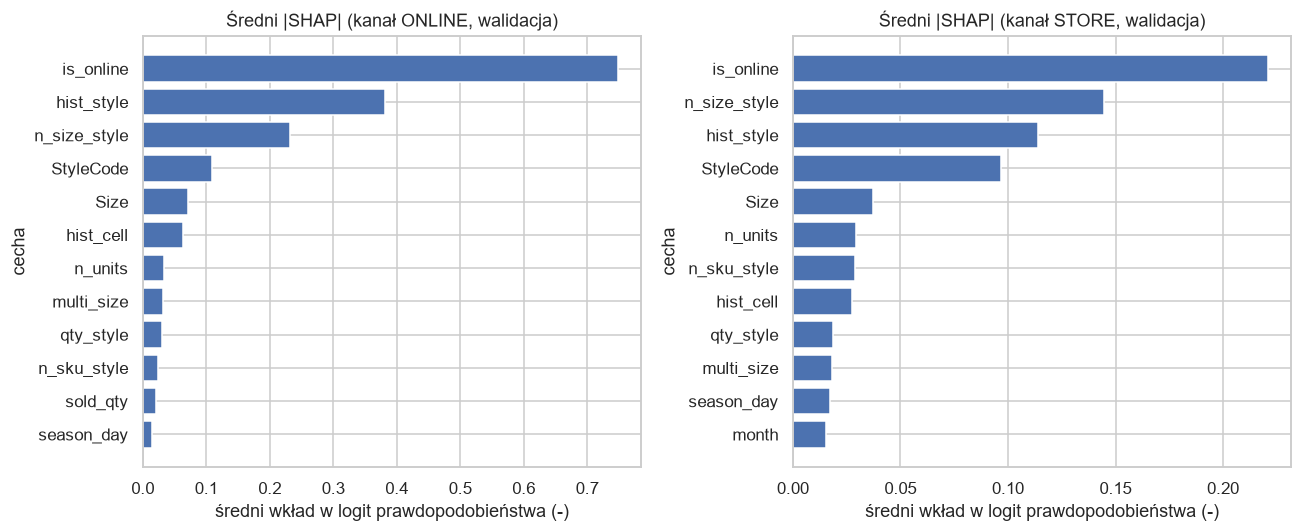

,ONLINE,STORE
is_online,0.7478,0.2208
hist_style,0.3813,0.1141
n_size_style,0.2320,0.1449
StyleCode,0.1092,0.0966
Size,0.0715,0.0373
hist_cell,0.0633,0.0275
n_units,0.0335,0.0295
multi_size,0.0314,0.0183
qty_style,0.0307,0.0188
n_sku_style,0.0233,0.0291


In [38]:
rng_p = np.random.default_rng(SEED)
Xv = d.iloc[IDX["val"]][M2.cols].reset_index(drop=True)
p0 = pred_lgb(M2, IDX["val"])
base_roc = {ch: EV["val"].metrics(p0, ch)["roc"] for ch in ["ONLINE", "STORE"]}
rows = []
for g in GROUPS_L:
    cols_g = [c for c in FEATS[g] if c in M2.cols]
    drops = {"ONLINE": [], "STORE": []}
    for _ in range(3):
        Xp = Xv.copy()
        perm = rng_p.permutation(len(Xp))
        for c in cols_g:
            Xp[c] = Xv[c].iloc[perm].reset_index(drop=True)  # te same wiersze dla całej grupy: zachowuję zależności wewnątrz grupy
        pp = M2.predict(Xp, num_iteration=M2.best_iteration)
        for ch in drops:
            drops[ch].append(base_roc[ch] - EV["val"].metrics(pp, ch)["roc"])
    rows.append([g, np.mean(drops["ONLINE"]), np.mean(drops["STORE"])])
perm_df = pd.DataFrame(rows, columns=["grupa cech", "spadek ROC online", "spadek ROC sklepy"])
display(perm_df.round(4))

# SHAP (pred_contrib): średni |wkład| na losowej próbie 12 tys. kluczy walidacji w kanale
shap_rows = []
for ch in ["ONLINE", "STORE"]:
    ii = np.flatnonzero((SPL["val"].Channel == ch).to_numpy())
    ii = rng_p.choice(ii, min(12000, len(ii)), replace=False)
    sv = M2.predict(Xv.iloc[ii], pred_contrib=True, num_iteration=M2.best_iteration)[:, :-1]
    s = pd.Series(np.abs(sv).mean(axis=0), index=M2.cols, name=ch)
    shap_rows.append(s)
shap_df = pd.concat(shap_rows, axis=1).sort_values("ONLINE", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, ch in zip(axes, ["ONLINE", "STORE"]):
    g = shap_df[ch].sort_values().tail(12)
    ax.barh(g.index, g.values)
    ax.set(title=f"Średni |SHAP| (kanał {ch}, walidacja)", xlabel="średni wkład w logit prawdopodobieństwa (-)", ylabel="cecha")
plt.tight_layout(); plt.show()
display(shap_df.round(4).head(12))

(WYNIK_SHAP)

### Test przecieku i odporność na wybór H

**Po co:** (1) pokazać, jak wygląda przeciek i że mój pipeline go nie ma: dodaję do M2 **zabronioną** cechę, czyli wskaźnik zwrotów modelu × rozmiaru × kanału liczony z całego okresu (w tym z przyszłości względem sprzedaży). Jeśli to zawyża wynik na walidacji, to pokazuje skalę ryzyka, a legalna historia as-of nie powinna się tak zachowywać. (2) Sprawdzić, czy wnioski o jakości zależą od okna zwrotu H = 50: powtarzam B1b i M1 dla H = 30 oraz H = 61 (pełne okno, tylko walidacja).

In [39]:
# (1) przeciek: wskaźnik z całego okresu (z kohort o domkniętym oknie) jako cecha
full_rate = d[d.labeled].groupby(["Channel", "StyleCode", "Size"], observed=True).apply(lambda x: x.ret_qty_h.sum() / x.sold_qty.sum(), include_groups=False).rename("leak_rate").reset_index()
d_leak = d.merge(full_rate, on=["Channel", "StyleCode", "Size"], how="left")
d_leak["leak_rate"] = d_leak.leak_rate.fillna(d_leak.groupby("Channel").leak_rate.transform("mean"))
d_bak = d
try:
    d = d_leak
    FEATS["PRZECIEK (wskaźnik z całego okresu)"] = ["leak_rate"]
    m_leak = fit_lgb(GROUPS_L + ["PRZECIEK (wskaźnik z całego okresu)"], IDX["train"], IDX["val"])
    p_leak = pred_lgb(m_leak, IDX["val"])
finally:
    d = d_bak
    FEATS.pop("PRZECIEK (wskaźnik z całego okresu)", None)
t_leak, _ = EV["val"].table({"M2 pełny (bez przecieku)": PRED["val"]["M2 LightGBM (pełny)"], "M2 + cecha z przyszłością": p_leak})
display(t_leak[["model", "kanał", "roc", "pr", "brier", "bss", "lift10"]].round(4))

,model,kanał,roc,pr,brier,bss,lift10
0,M2 pełny (bez przecieku),ONLINE,0.6601,0.2890,0.1304,0.0564,2.2523
1,M2 pełny (bez przecieku),STORE,0.5715,0.0625,0.0375,0.0072,1.9041
2,M2 + cecha z przyszłością,ONLINE,0.6628,0.2901,0.1302,0.0581,2.2523
3,M2 + cecha z przyszłością,STORE,0.5870,0.0667,0.0375,0.0081,1.9491


In [40]:
# (2) odporność na H: etykieta = zwroty w ciągu 30 dni lub pełne okno (61 dni) ; ten sam podział; M1 pełny i B1b
rows = []
ret_backup = d.ret_qty_h.copy()
try:
    for lab, col in [("H=30", "ret_qty_30"), ("H=50 (główne)", "ret_qty_h"), ("H=61", "ret_qty_all")]:
        d["ret_qty_h"] = ret_backup if col == "ret_qty_h" else d[col]
        SPLx = {s: d.iloc[IDX[s]].reset_index(drop=True) for s in ["val"]}
        evx = EvalSet(SPLx["val"])
        trn = d.iloc[IDX["train"]]
        pb = base_pred(trn, SPLx["val"], ["Channel", "Category", "Size"])
        mods = {ch: fit_logit(GROUPS, ch, best_C[ch], IDX["train"]) for ch in ["ONLINE", "STORE"]}
        pm = predict_logit(mods, GROUPS, IDX["val"])
        for nm, p in [("B1b", pb), ("M1 pełny", pm)]:
            for ch in ["ONLINE", "STORE"]:
                r = evx.metrics(p, ch)
                rows.append([lab, nm, ch, r["prev"], r["roc"], r["pr"], r["bss"], r["lift10"]])
finally:
    d["ret_qty_h"] = ret_backup
rob = pd.DataFrame(rows, columns=["okno", "model", "kanał", "wskaźnik", "ROC", "PR", "BSS", "lift10"])
display(rob.round(4))

,okno,model,kanał,wskaźnik,ROC,PR,BSS,lift10
0,H=30,B1b,ONLINE,0.1633,0.5755,0.2066,0.0109,1.4935
1,H=30,B1b,STORE,0.0386,0.5106,0.0396,-0.0004,1.0803
2,H=30,M1 pełny,ONLINE,0.1633,0.6477,0.2638,0.0417,2.0323
3,H=30,M1 pełny,STORE,0.0386,0.5646,0.0564,0.0046,1.9420
4,H=50 (główne),B1b,ONLINE,0.1656,0.5775,0.2099,0.0108,1.5279
5,H=50 (główne),B1b,STORE,0.0393,0.5124,0.0405,-0.0004,1.0743
6,H=50 (główne),M1 pełny,ONLINE,0.1656,0.6478,0.2670,0.0422,2.0305
7,H=50 (główne),M1 pełny,STORE,0.0393,0.5633,0.0569,0.0045,1.9565
8,H=61,B1b,ONLINE,0.1674,0.5759,0.2113,0.0105,1.5250
9,H=61,B1b,STORE,0.0397,0.5121,0.0408,-0.0004,1.0787


(WYNIK_PRZECIEK)

### M3: tabela model × rozmiar × kanał z kurczeniem (empiryczne Bayesa)

**Po co:** to narzędzie do decyzji A (poprawa oferty). Komórka model × rozmiar × kanał ma zwykle od kilkudziesięciu do kilku tysięcy sprzedanych sztuk, więc surowy wskaźnik (np. 3 zwroty z 7) jest niewiarygodny. **Kurczenie** (shrinkage) łączy dwie informacje: wskaźnik własny komórki i wartość oczekiwaną *E* z kanału, kategorii i rozmiaru. Im mniej danych w komórce, tym mocniej wynik jest „ściągany" ku *E*. Formalnie: zwroty w komórce modeluję rozkładem beta-dwumianowym z priorem Beta(κ·E, κ·(1−E)); parametr κ (ile „wirtualnych sztuk" waży prior) estymuję z danych metodą największej wiarygodności osobno w kanałach (to właśnie jest „empiryczne Bayesa"). Wynik: wskaźnik a posteriori z 90% przedziałem wiarygodności i prawdopodobieństwo, że prawdziwy wskaźnik komórki przekracza *E*.

**Zastrzeżenia:** (1) sztuki z jednego paragonu są zależne, więc zależność wewnątrz koszyków wchodzi do estymaty κ jako dodatkowa „dyspersja" (czyni przedziały ostrożniejszymi), ale nie jest modelowana wprost; (2) *E* liczę z tych samych danych (kanał × kategoria × rozmiar), więc dla małych kategorii jest lekko przesunięte ku komórkom; (3) „nadmiar" to różnica względem **typowej komórki tej kategorii i rozmiaru w tym kanale**, a nie względem „idealnego" modelu.

**Walidacja w czasie (reguła z Fazy 4):** dopasowuję M3 na treningu i sprawdzam na późniejszych danych (walidacja + test): (a) czy przewidywany wskaźnik trafia lepiej niż surowy wskaźnik komórki i niż samo *E* (log-loss na sztukę), (b) czy 90% przedziały predykcyjne (beta-dwumianowe dla liczby sprzedanej później) mają pokrycie bliskie 90%.

In [41]:
from scipy.special import betaln
from scipy.stats import beta as beta_dist, betabinom

def cell_counts(df):
    df = df.astype({"Category": str, "Size": str, "StyleCode": str})
    return df.groupby(["Channel", "StyleCode", "Category", "Size"]).agg(n=("sold_qty", "sum"), y=("ret_qty_h", "sum")).reset_index()

def expected_rate(df):
    df = df.astype({"Category": str, "Size": str})
    g = df.groupby(["Channel", "Category", "Size"]).agg(n=("sold_qty", "sum"), y=("ret_qty_h", "sum")).reset_index()
    g["E"] = g.y / g.n
    return g[["Channel", "Category", "Size", "E"]]

def fit_kappa(y, n, E):
    """Największa wiarygodność beta-dwumianowa dla wspólnego kappa (siatka logarytmiczna)."""
    grid = np.exp(np.linspace(np.log(2), np.log(2e4), 160))
    ll = [np.sum(betaln(y + k * E, n - y + k * (1 - E)) - betaln(k * E, k * (1 - E))) for k in grid]
    return grid[int(np.argmax(ll))], grid, np.array(ll)

def fit_m3(df):
    c = cell_counts(df).merge(expected_rate(df), on=["Channel", "Category", "Size"])
    kap = {}
    for ch in ["ONLINE", "STORE"]:
        g = c[c.Channel == ch]
        kap[ch] = fit_kappa(g.y.to_numpy(), g.n.to_numpy(), g.E.to_numpy())[0]
    c["kappa"] = c.Channel.map(kap)
    c["a"], c["b"] = c.kappa * c.E + c.y, c.kappa * (1 - c.E) + c.n - c.y
    c["post"] = c.a / (c.a + c.b)
    c["lo90"], c["hi90"] = beta_dist.ppf(0.05, c.a, c.b), beta_dist.ppf(0.95, c.a, c.b)
    c["p_above"] = 1 - beta_dist.cdf(c.E, c.a, c.b)
    c["raw"] = c.y / c.n
    return c, kap

m3_tr, kap_tr = fit_m3(SPL["train"])
print("κ (liczba wirtualnych sztuk priora) na treningu:", {k: round(v, 1) for k, v in kap_tr.items()}, "| komórek:", len(m3_tr), "| mediana sztuk w komórce:", int(m3_tr.n.median()))

# Walidacja na późniejszych danych (walidacja + test razem)
later_c = cell_counts(pd.concat([SPL["val"], SPL["test"]])).rename(columns={"n": "n_l", "y": "y_l"})
v = m3_tr.merge(later_c, on=["Channel", "StyleCode", "Category", "Size"])
v["raw_p"] = np.where(v.n >= 20, v.raw, v.E).clip(0.002, 0.998)  # surowy wskaźnik (komórki mniejsze niż 20 sztuk dostają E, żeby nie liczyć logarytmu z zera)
def ll(p, y, n):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return -(y * np.log(p) + (n - y) * np.log(1 - p)).sum() / n.sum()
rows = []
for ch in ["ONLINE", "STORE"]:
    g = v[v.Channel == ch]
    rows.append([ch, len(g), ll(g.E.to_numpy(), g.y_l.to_numpy(), g.n_l.to_numpy()), ll(g.raw_p.to_numpy(), g.y_l.to_numpy(), g.n_l.to_numpy()), ll(g.post.to_numpy(), g.y_l.to_numpy(), g.n_l.to_numpy())])
val3 = pd.DataFrame(rows, columns=["kanał", "komórek", "log-loss: samo E (B1b)", "log-loss: surowy wskaźnik komórki", "log-loss: M3 (kurczenie)"])
display(val3.round(5))
# pokrycie 90% przedziału predykcyjnego dla liczby zwrotów w późniejszych danych (komórki z >= 30 sztuk później)
cov = []
for ch in ["ONLINE", "STORE"]:
    g = v[(v.Channel == ch) & (v.n_l >= 30)]
    lo_, hi_ = betabinom.ppf(0.05, g.n_l.astype(int), g.a, g.b), betabinom.ppf(0.95, g.n_l.astype(int), g.a, g.b)
    cov.append([ch, len(g), np.mean((g.y_l >= lo_) & (g.y_l <= hi_))])
display(pd.DataFrame(cov, columns=["kanał", "komórek (>=30 szt. później)", "pokrycie 90% przedziału predykcyjnego"]).round(3))

# Które komórki wyróżnione na treningu (P(powyżej E) >= 0,95 i wskaźnik a posteriori >= 1,2 E) nadal są powyżej E później?
fl = v[(v.p_above >= 0.95) & (v.post >= 1.2 * v.E)]
print(f"Wyróżnione na treningu: {len(fl)} komórek; z nich później powyżej E: {(fl.y_l / fl.n_l > fl.E).mean():.0%} (przy samej losowości ok. 50%); wyróżnione ważone sprzedażą późniejszą: obs/E = {fl.y_l.sum() / (fl.n_l * fl.E).sum():.2f}")
nfl = v[~v.index.isin(fl.index)]
print(f"Niewyróżnione: obs/E później = {nfl.y_l.sum() / (nfl.n_l * nfl.E).sum():.2f}")

κ (liczba wirtualnych sztuk priora) na treningu: {'ONLINE': np.float64(245.0), 'STORE': np.float64(3950.3)} | komórek: 312 | mediana sztuk w komórce: 136


,kanał,komórek,log-loss: samo E (B1b),log-loss: surowy wskaźnik komórki,log-loss: M3 (kurczenie)
0,ONLINE,151,0.4661,0.4651,0.4647
1,STORE,156,0.1666,0.1666,0.1665


,kanał,komórek (>=30 szt. później),pokrycie 90% przedziału predykcyjnego
0,ONLINE,70,0.8570
1,STORE,97,0.8560


Wyróżnione na treningu: 0 komórek; z nich później powyżej E: nan% (przy samej losowości ok. 50%); wyróżnione ważone sprzedażą późniejszą: obs/E = nan
Niewyróżnione: obs/E później = 0.99


C:\Users\ev45i\AppData\Local\Temp\ipykernel_46168\2464201949.py:60: RuntimeWarning: invalid value encountered in scalar divide
  print(f"Wyróżnione na treningu: {len(fl)} komórek; z nich później powyżej E: {(fl.y_l / fl.n_l > fl.E).mean():.0%} (przy samej losowości ok. 50%); wyróżnione ważone sprzedażą późniejszą: obs/E = {fl.y_l.sum() / (fl.n_l * fl.E).sum():.2f}")


(WYNIK_M3)

#### M3 na pełnych danych z domkniętym oknem: tabela dla zleceniodawcy

**Po co:** do decyzji o ofercie używam wszystkich sprzedaży z domkniętym oknem H (do 2026-08-01), bo to najwięcej danych na komórkę; walidacja w czasie wyżej pokazała, na ile można wierzyć takiej tabeli. Wyróżniam komórki, które **i** statystycznie (prawdopodobieństwo przekroczenia *E* ≥ 95%) **i** praktycznie (wskaźnik a posteriori ≥ 1,2 *E*) wychodzą ponad oczekiwanie. Podaję też strukturę powodów zwrotów w komórce i regułę proponowanego działania (heurystyka: dominujący powód ponad średnią kanału).

In [42]:
LB = dk[dk.labeled]
m3, kap = fit_m3(LB)
print("κ na pełnych danych:", {k: round(v, 1) for k, v in kap.items()}, "| komórek:", len(m3))
span_q = (pd.Timestamp("2026-08-02") - pd.Timestamp("2025-01-01")).days / 91.3
m3["nad_szt"] = m3.n * (m3.post - m3.E)
m3["nad_kw"] = m3.nad_szt / span_q  # nadwyżka sztuk zwróconych na kwartał (średnio w okresie danych)
m3["ratio"] = m3.post / m3.E
m3["flag"] = (m3.p_above >= 0.95) & (m3.ratio >= 1.2)
m3["flag_low"] = ((1 - m3.p_above) >= 0.95) & (m3.ratio <= 1 / 1.2)
print(f"Komórek wyróżnionych 'ponad oczekiwanie': {m3.flag.sum()} ({m3[m3.flag].n.sum() / m3.n.sum():.1%} sprzedanych sztuk); 'poniżej oczekiwania': {m3.flag_low.sum()}")

rs_cell = q(f"""
SELECT k.Channel, p.StyleCode, p.Size, COALESCE(r.ReturnReason, 'BRAK') AS powod, SUM(r.Quantity) AS sztuki
FROM returns_f r JOIN sales_key k USING (TransactionNo, ProductKey) JOIN dim_product p ON p.ProductKey = r.ProductKey
WHERE k.SaleDate <= DATE '{LABEL_CLOSED_BEFORE}' AND DATE_DIFF('day', k.SaleDate, r.ReturnDate) <= {H}
GROUP BY ALL
""")
rs_w = rs_cell.pivot_table(index=["Channel", "StyleCode", "Size"], columns="powod", values="sztuki", aggfunc="sum", fill_value=0)
rs_sh = rs_w.div(rs_w.sum(axis=1), axis=0).add_prefix("udz_").reset_index()
ch_avg = rs_cell.groupby(["Channel", "powod"]).sztuki.sum().unstack()
ch_avg = ch_avg.div(ch_avg.sum(axis=1), axis=0)
m3 = m3.merge(rs_sh, on=["Channel", "StyleCode", "Size"], how="left")
def action(r):
    ca = ch_avg.loc[r.Channel]
    if r.udz_WRONG_SIZE - ca["WRONG_SIZE"] > 0.05:
        return "tabela rozmiarów / opis kroju"
    if r.udz_DAMAGED - ca["DAMAGED"] > 0.05:
        return "jakość, dostawca, pakowanie"
    return "opis, zdjęcia, oczekiwania klienta"
m3["dzialanie"] = m3.apply(action, axis=1)
names = dim_product.drop_duplicates("StyleCode").set_index("StyleCode").StyleName
m3["Nazwa"] = m3.StyleCode.map(names)
top = m3[m3.flag].sort_values("nad_kw", ascending=False).head(15)
display(top[["Channel", "StyleCode", "Nazwa", "Size", "n", "raw", "E", "post", "lo90", "hi90", "ratio", "p_above", "nad_kw", "udz_WRONG_SIZE", "udz_DAMAGED", "dzialanie"]].round(3))
m3.to_parquet(CACHE / "m3_cells.parquet")

κ na pełnych danych: {'ONLINE': np.float64(231.2), 'STORE': np.float64(2790.5)} | komórek: 312
Komórek wyróżnionych 'ponad oczekiwanie': 1 (1.4% sprzedanych sztuk); 'poniżej oczekiwania': 5


,Channel,StyleCode,Nazwa,Size,n,raw,E,post,lo90,hi90,ratio,p_above,nad_kw,udz_WRONG_SIZE,udz_DAMAGED,dzialanie
233,STORE,W-DRS-002,Sukienka koszulowa,M,"6,409",0.0500,0.0380,0.0470,0.0430,0.0500,1.2200,1,8.5060,0.2640,0.1680,"opis, zdjęcia, oczekiwania klienta"


(WYNIK_M3FULL)

In [43]:
# Poziom modelu x kanał (suma komórek): nadwyżka względem oczekiwań i przedział z symulacji posteriora
rng_m = np.random.default_rng(SEED)
rows = []
for (ch, sty), g in m3.groupby(["Channel", "StyleCode"]):
    sims = np.array([rng_m.beta(g.a, g.b) for _ in range(1000)])  # losowe wskaźniki komórek z posteriora (1000 powtórzeń)
    exc = (sims * g.n.to_numpy()).sum(axis=1)
    exp_ = (g.E * g.n).sum()
    rows.append([ch, sty, names[sty], g.n.sum(), (g.y.sum()) / g.n.sum(), exp_ / g.n.sum(), np.mean(exc) / exp_, *np.quantile(exc / exp_, [0.05, 0.95]), (exc > exp_).mean()])
ms = pd.DataFrame(rows, columns=["Channel", "StyleCode", "Nazwa", "n", "raw", "E", "O_E_post", "lo90", "hi90", "P(>E)"])
ms["nad_kw"] = (ms.O_E_post - 1) * ms.E * ms.n / span_q
print("Modele x kanał: największe nadwyżki zwrotów względem oczekiwań (sztuk na kwartał) i największe niedobory")
display(ms.sort_values("nad_kw", ascending=False).head(8).round(3))
display(ms.sort_values("nad_kw").head(5).round(3))
print(f"Modeli x kanał, dla których 90% przedział O/E nie zawiera 1: {((ms.lo90 > 1) | (ms.hi90 < 1)).sum()} z {len(ms)}")

Modele x kanał: największe nadwyżki zwrotów względem oczekiwań (sztuk na kwartał) i największe niedobory


,Channel,StyleCode,Nazwa,n,raw,E,O_E_post,lo90,hi90,P(>E),nad_kw
28,ONLINE,W-JNS-003,Jeansy skinny,"20,159",0.2790,0.2530,1.0950,1.0760,1.1150,1,76.6970
20,ONLINE,W-DRS-002,Sukienka koszulowa,"5,840",0.1960,0.1670,1.1430,1.0940,1.1880,1,21.9810
56,STORE,W-DRS-002,Sukienka koszulowa,"20,113",0.0480,0.0390,1.1410,1.0970,1.1890,1,17.5620
34,ONLINE,W-TSH-001,T-shirt basic damski,"11,037",0.1670,0.1600,1.0380,1.0030,1.0710,0.9630,10.7220
64,STORE,W-JNS-003,Jeansy skinny,"63,589",0.0480,0.0470,1.0210,0.9940,1.0490,0.9070,10.0380
70,STORE,W-TSH-001,T-shirt basic damski,"36,703",0.0390,0.0370,1.0380,1,1.0770,0.9490,8.2030
26,ONLINE,W-JKT-002,Parka damska,"3,600",0.1810,0.1620,1.0870,1.0310,1.1450,0.9970,8.0600
30,ONLINE,W-KNT-001,Sweter oversize,"5,464",0.1690,0.1590,1.0520,1.0040,1.1030,0.9620,7.1850


,Channel,StyleCode,Nazwa,n,raw,E,O_E_post,lo90,hi90,P(>E),nad_kw
9,ONLINE,M-JNS-001,Jeansy regular,"5,934",0.1710,0.2530,0.7320,0.7040,0.7630,0,-63.4430
25,ONLINE,W-JKT-001,Kurtka pikowana damska,"4,329",0.1370,0.1620,0.8770,0.8310,0.9260,0,-13.6480
16,ONLINE,M-TSH-001,T-shirt basic,"9,310",0.1500,0.1600,0.9440,0.9090,0.9800,0.0040,-13.2790
19,ONLINE,W-DRS-001,Sukienka midi,"6,570",0.1540,0.1680,0.9280,0.8870,0.9700,0.0030,-12.4950
21,ONLINE,W-DRS-003,Sukienka mini,"4,726",0.1500,0.1670,0.9230,0.8770,0.9690,0.0060,-9.6030


Modeli x kanał, dla których 90% przedział O/E nie zawiera 1: 19 z 72


### Decyzja C: koszt zwrotów w następnym kwartale

**Po co:** zleceniodawca pyta, ile zwroty będą kosztować w następnym kwartale. Tu obowiązuje **definicja słownikowa** (zwrot liczony w dniu *przyjęcia*, bo wtedy powstaje koszt), a nie kohortowa. Miara kosztu: **wartość zwrotów netto** = `SUM(ReturnAmount) / 1,23` (definicja ze słownika metryk Nordvik; przyjmuję ją za „koszt", bo danych o kosztach obsługi i odpisach nie mam, to pytanie do zleceniodawcy). „Następny kwartał" rozumiem jako kwartał kalendarzowy **IV 2026 (1 października - 31 grudnia)**; dane kończą się 2026-09-20.

**Metody (porównuję na przeszłych kwartałach, nie zakładam z góry):**
- **C0, poziom bez sezonowości:** średnia dzienna wartość zwrotów z ostatnich 13 tygodni × liczba dni prognozy. Prosty punkt odniesienia.
- **C1, ten sam okres rok wcześniej × wzrost:** wartość zwrotów w odpowiadających dniach sprzedaży rok wcześniej (przesunięcie o 364 dni, czyli te same dni tygodnia), pomnożona przez wskaźnik wzrostu rok do roku z ostatnich *N* tygodni (suma ostatnich *N* tygodni / suma odpowiadających tygodni rok wcześniej). Uwzględnia sezonowość (wyprzedaże, święta), ale zakłada, że relacja do ubiegłego roku się utrzymuje.
- Wariant C1 z *N* = 8 i *N* = 13 tygodni (kompromis: krótkie okno szybciej reaguje, ale jest bardziej zaszumione).

**Walidacja:** rolling origin: dla kolejnych dni odcięcia *T* (co tydzień) prognozuję kolejne 91 dni i porównuję z faktem. Dostępne jest tylko kilka nakładających się prób (dane od 2025-01-06, więc „rok wcześniej" istnieje dla 2026), więc błąd traktuję orientacyjnie, nie jak precyzyjną estymatę.

In [44]:
dr = q("""SELECT ReturnDate AS d, SUM(ReturnAmount) / 1.23 AS net, SUM(Quantity) AS qty FROM returns_f GROUP BY 1 ORDER BY 1""")
ds = q("""SELECT SaleDate AS d, SUM(NetAmount) AS net FROM sales_f GROUP BY 1 ORDER BY 1""")
idx_all = pd.date_range("2025-01-01", "2026-09-20")
R = dr.assign(d=pd.to_datetime(dr.d)).set_index("d").net.reindex(idx_all, fill_value=0.0)
S = ds.assign(d=pd.to_datetime(ds.d)).set_index("d").net.reindex(idx_all, fill_value=0.0)
R0 = pd.Timestamp("2025-01-06")  # pierwszy zwrot w danych (od tej daty seria zwrotów jest kompletna)

def forecast_c(T, N=13, horizon=91, method="C1"):
    """Prognoza łącznej wartości zwrotów netto w dniach T+1..T+horizon (T = ostatni dzień danych)."""
    days = pd.date_range(T + pd.Timedelta(days=1), periods=horizon)
    if method == "C0":
        return R[T - pd.Timedelta(days=90):T].mean() * horizon
    base = R.reindex(days - pd.Timedelta(days=364)).to_numpy()
    cur = R[T - pd.Timedelta(days=7 * N - 1):T]
    prev = R.reindex(cur.index - pd.Timedelta(days=364))
    g = cur.sum() / prev.sum()
    return np.nansum(base) * g

# Rolling origin: T od 2026-04-05 (okno wzrostu N=13 ma wtedy rok wcześniej dane zwrotów) do T+91 <= 2026-09-20
rows = []
for T in pd.date_range("2026-04-05", "2026-06-21", freq="7D"):
    act = R[T + pd.Timedelta(days=1):T + pd.Timedelta(days=91)].sum()
    for lab, kw in [("C0 poziom 13 tyg.", dict(method="C0")), ("C1 rok wcześniej, N=8", dict(N=8)), ("C1 rok wcześniej, N=13", dict(N=13))]:
        f = forecast_c(T, **kw)
        rows.append([T.date(), lab, act, f, f / act - 1])
bt = pd.DataFrame(rows, columns=["T", "metoda", "fakt", "prognoza", "błąd względny"])
btp = bt.pivot(index="T", columns="metoda", values="błąd względny")
display((btp * 100).round(1))
summ = bt.groupby("metoda")["błąd względny"].agg(MAE_pct=lambda s: s.abs().mean() * 100, bias_pct=lambda s: s.mean() * 100, max_abs_pct=lambda s: s.abs().max() * 100)
display(summ.round(1))

metoda,C0 poziom 13 tyg.,"C1 rok wcześniej, N=13","C1 rok wcześniej, N=8"
T,,,
2026-04-05,42.9000,25.1000,2.4000
2026-04-12,41.6000,16.5000,0.4000
2026-04-19,39.8000,18.7000,3.8000
2026-04-26,28.6000,11,0.6000
2026-05-03,13.4000,6.8000,7.8000
2026-05-10,2.4000,5.4000,10.6000
2026-05-17,-4.5000,5.2000,12.4000
2026-05-24,-9.3000,3.4000,6.9000
2026-05-31,-10.6000,8,7.7000


,MAE_pct,bias_pct,max_abs_pct
metoda,,,
C0 poziom 13 tyg.,20.3000,7.8000,42.9000
"C1 rok wcześniej, N=13",10.8000,10.8000,25.1000
"C1 rok wcześniej, N=8",5.7000,5.7000,12.4000


(WYNIK_C_BT)

Dni bazowe (rok wcześniej) w danych: 92 z 92 | baza: suma wartości zwrotów netto w odpowiadających dniach rok wcześniej [PLN]: 997,511
Wzrost rok do roku wartości zwrotów: ostatnie 13 tyg. 1.063, ostatnie 26 tyg. 1.108; wzrost sprzedaży netto (26 tyg.): 1.096


Prognoza IV kw. 2026 (wartość zwrotów netto): C1(N=13) = 1,060,196 PLN; C1(N=26) = 1,105,098 PLN; przedział 90% z bootstrapu (26 tyg.): [1,034,502; 1,143,349] PLN
Dla porównania: IV kw. 2025 (fakt): 1,003,758 PLN; III kw. 2026 do 09-20 (81 dni): 710,519 PLN


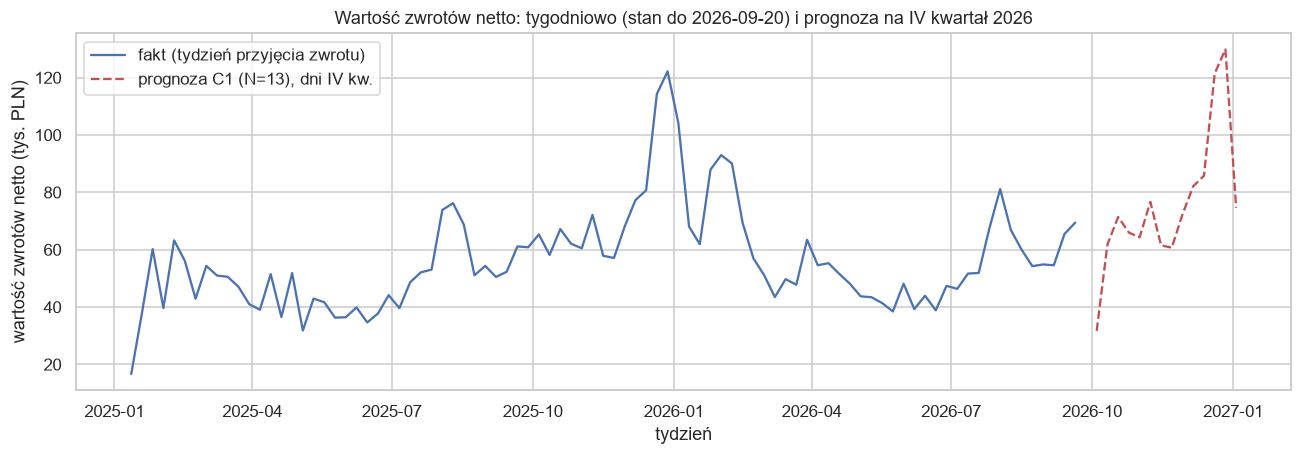

In [45]:
# Prognoza na IV kwartał 2026 (T = 2026-09-20), metoda wybrana na podstawie walidacji (domyślnie C1, N=13; zob. interpretację powyżej)
T0 = pd.Timestamp("2026-09-20")
q4 = pd.date_range("2026-10-01", "2026-12-31")
base_q4 = R.reindex(q4 - pd.Timedelta(days=364))
print("Dni bazowe (rok wcześniej) w danych:", int(base_q4.notna().sum()), "z", len(q4), "| baza: suma wartości zwrotów netto w odpowiadających dniach rok wcześniej [PLN]:", f"{base_q4.sum():,.0f}")
cur13 = R[T0 - pd.Timedelta(days=90):T0]; prev13 = R.reindex(cur13.index - pd.Timedelta(days=364))
g13 = cur13.sum() / prev13.sum()
cur26 = R[T0 - pd.Timedelta(days=181):T0]; prev26 = R.reindex(cur26.index - pd.Timedelta(days=364))
g26 = cur26.sum() / prev26.sum()
sg = S[T0 - pd.Timedelta(days=181):T0].sum() / S.reindex(S[T0 - pd.Timedelta(days=181):T0].index - pd.Timedelta(days=364)).sum()
print(f"Wzrost rok do roku wartości zwrotów: ostatnie 13 tyg. {g13:.3f}, ostatnie 26 tyg. {g26:.3f}; wzrost sprzedaży netto (26 tyg.): {sg:.3f}")

# Przedział: bootstrap blokowy (bloki 4 tygodni) tygodniowych wskaźników rok do roku z ostatnich 26 tygodni
wk = pd.DataFrame({"cur": R[T0 - pd.Timedelta(days=181):T0].to_numpy(), "prev": R.reindex(R[T0 - pd.Timedelta(days=181):T0].index - pd.Timedelta(days=364)).to_numpy()})
wk["w"] = np.arange(len(wk)) // 7
wkw = wk.groupby("w").sum()
rng_c = np.random.default_rng(SEED)
sims = []
nb = len(wkw)
for _ in range(5000):
    starts = rng_c.integers(0, nb - 3, size=int(np.ceil(nb / 4)))
    pick = np.concatenate([np.arange(s, s + 4) for s in starts])[:nb]
    sims.append(wkw.cur.to_numpy()[pick].sum() / wkw.prev.to_numpy()[pick].sum())
sims = np.array(sims)
fc = base_q4.sum() * np.array([g13, g26, np.median(sims)])
lo, hi = np.quantile(sims, [0.05, 0.95]) * base_q4.sum()
print(f"Prognoza IV kw. 2026 (wartość zwrotów netto): C1(N=13) = {fc[0]:,.0f} PLN; C1(N=26) = {fc[1]:,.0f} PLN; przedział 90% z bootstrapu (26 tyg.): [{lo:,.0f}; {hi:,.0f}] PLN")
print(f"Dla porównania: IV kw. 2025 (fakt): {R['2025-10-01':'2025-12-31'].sum():,.0f} PLN; III kw. 2026 do 09-20 (81 dni): {R['2026-07-01':'2026-09-20'].sum():,.0f} PLN")

# Wykres: tygodniowa wartość zwrotów netto i prognoza
wkly = R[R0:].resample("W-SUN").sum()
fcw = (R.reindex(q4 - pd.Timedelta(days=364)).set_axis(q4) * g13).resample("W-SUN").sum()
fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(wkly.index, wkly / 1e3, label="fakt (tydzień przyjęcia zwrotu)")
ax.plot(fcw.index, fcw / 1e3, "--", c="C3", label="prognoza C1 (N=13), dni IV kw.")
ax.set(title="Wartość zwrotów netto: tygodniowo (stan do 2026-09-20) i prognoza na IV kwartał 2026", xlabel="tydzień", ylabel="wartość zwrotów netto (tys. PLN)")
ax.legend(); plt.tight_layout(); plt.show()

### Przegląd krytyczny (przed Fazą 8)

**Po co:** zanim przedstawię wyniki zleceniodawcy, sprawdzam pięć rzeczy, które najczęściej po cichu psują takie analizy. Gdzie to możliwe, sprawdzam kodem, a nie deklaracją.

1. **Czy jakakolwiek cecha zawiera informację z po sprzedaży?** Cechy modeli: kanał, model, kategoria, rozmiar, cena i rabat, kalendarz, zawartość tego samego paragonu oraz historia modelu as-of (tylko kohorty sprzedane co najmniej H + 1 dni wcześniej). Nie użyłem `ReturnReason`, kanału przyjęcia zwrotu ani wskaźników z całego okresu. Dodatkowo test przecieku (sekcja wyżej) pokazuje, jak wygląda skażenie.
2. **Czy pozycje z tego samego paragonu trafiły do treningu i testu?** Sprawdzam poniżej liczbą wspólnych numerów paragonów między zbiorami.
3. **Czy kanał wyznaczam ze sprzedaży, nie z miejsca przyjęcia zwrotu?** Kanał pochodzi z `fact_sales` przez `dim_store`; kod sprawdza, że kolumna kanału przyjęcia nie trafia do żadnego zbioru cech.
4. **Czy dobra jakość nie wynika wyłącznie z rozróżnienia kanałów?** Pokazuję, ile wynosi ROC-AUC *łączny* dla samej informacji o kanale (to złudne „dobre" wyniki) i dlaczego w całej analizie używam ROC-AUC *w obrębie kanału*.
5. **Czy wnioski o pojedynczych modelach uwzględniają małą liczebność?** Tak: tabela M3 z kurczeniem i przedziałami; modele o małej sprzedaży (np. `M-JKT-002` online, 100 sztuk w treningu) nie mogą trafić na listę bez przedziału.

In [46]:
tr_ids, va_ids, te_ids = (set(SPL[s].TransactionNo) for s in ["train", "val", "test"])
print("Wspólne paragony: trening∩walidacja =", len(tr_ids & va_ids), "| trening∩test =", len(tr_ids & te_ids), "| walidacja∩test =", len(va_ids & te_ids))
all_feats = {c for g in FEATS.values() for c in g}
print("Cechy modeli:", sorted(all_feats))
print("Czy któraś cecha pochodzi z zakazanych kolumn (powód, kanał przyjęcia, kolumny ret_*)?", any(c.startswith(("ret_", "q_", "Return")) or c in {"ReturnReason", "ReturnChannel"} for c in all_feats))
# Łączny ROC-AUC samego kanału (B0) i średnia w obrębie kanałów
ev = EV["test"]
p_b0 = np.asarray(PRED["test"]["B0 kanał"])[ev.e.i.to_numpy()]
print(f"Test: ROC-AUC łączny dla samego kanału (B0) = {roc_auc_score(ev.e.y, p_b0, sample_weight=ev.e.w):.3f}; w obrębie kanałów = 0,5 z definicji")
p_m2 = np.asarray(PRED["test"]["M2 LightGBM (pełny)"])[ev.e.i.to_numpy()]
print(f"Test: ROC-AUC łączny M2 = {roc_auc_score(ev.e.y, p_m2, sample_weight=ev.e.w):.3f} vs wartości w obrębie kanałów w tabeli porównawczej: różnica to właśnie efekt kanału")

Wspólne paragony: trening∩walidacja = 0 | trening∩test = 0 | walidacja∩test = 0
Cechy modeli: ['Category', 'DayOfWeek', 'Size', 'StyleCode', 'disc_rate', 'hist_cell', 'hist_style', 'is_online', 'log_basket', 'log_price', 'month', 'multi_size', 'n_cat', 'n_lines', 'n_size_style', 'n_sku_style', 'n_units', 'qty_style', 'season_day', 'season_type', 'sold_qty']
Czy któraś cecha pochodzi z zakazanych kolumn (powód, kanał przyjęcia, kolumny ret_*)? False
Test: ROC-AUC łączny dla samego kanału (B0) = 0.692; w obrębie kanałów = 0,5 z definicji
Test: ROC-AUC łączny M2 = 0.735 vs wartości w obrębie kanałów w tabeli porównawczej: różnica to właśnie efekt kanału


(WYNIK_PRZEGLAD)